# <a id='toc1_'></a>[Comparativa de teléfonos inteligentes](#toc0_)

**Tabla de contenido**<a id='toc0_'></a>    
- [Comparativa de teléfonos inteligentes](#toc1_)    
  - [1. Introducción](#toc1_1_)    
  - [2. Carga y exploración inicial del dataset](#toc1_2_)    
    - [2.1. Información básica del dataset](#toc1_2_1_)    
    - [2.2. Valores nulos](#toc1_2_2_)    
    - [2.3. Chequeo de registros duplicados](#toc1_2_3_)    
    - [2.4. Valores únicos de cada columna](#toc1_2_4_)    
  - [3. Preparación del dataset para el análisis](#toc1_3_)    
    - [3.1. Registros con valores nulos](#toc1_3_1_)    
    - [3.2. Creación de nuevas características](#toc1_3_2_)    
      - [3.2.1. Precio en euros](#toc1_3_2_1_)    
      - [3.2.2. Categoría según precio](#toc1_3_2_2_)    
  - [4. Análisis del dataset](#toc1_4_)    
    - [4.1. Análisis univariante](#toc1_4_1_)    
      - [4.1.2. Variables numéricas](#toc1_4_1_1_)    
      - [4.1.3. Variables categóricas y booleanas](#toc1_4_1_2_)    
    - [4.2. Análisis multivariante](#toc1_4_2_)    
      - [4.2.1. Heatmaps de correlación entre variables numéricas](#toc1_4_2_1_)    
      - [4.2.2. Heatmaps de correlación de rating y precio con variables booleanas y categóricas](#toc1_4_2_2_)    
      - [4.2.3. Pairplots de variables numéricas](#toc1_4_2_3_)    
      - [4.2.4. ANOVAs con variables booleanas](#toc1_4_2_4_)    
      - [4.2.5. ANOVAs y test de Tukey entre distintas marcas](#toc1_4_2_5_)    
  - [5. Contraste de hipótesis](#toc1_5_)    
    - [5.1. Hipótesis 1](#toc1_5_1_)    
    - [5.2. Hipótesis 2](#toc1_5_2_)    
    - [5.3. Hipótesis 3](#toc1_5_3_)    

Contenido_dum

1. [Introducción](#intro)
2. [Print](#2.-Print)

<a id=intro></a>
## <a id='toc1_1_'></a>[1. Introducción](#toc0_)

Se tratará de determinar las características más habituales de los teléfonos inteligentes y los factores que más influyen en su precio, en base a un dataset que incluye precios, valoraciones y datos técnicos de teléfonos de varias marcas. 

Procedencia del dataset: 
https://www.kaggle.com/datasets/agarwalyashhh/smartphones-complete-data/data


Resumen del dataset (extraída de https://www.kaggle.com/code/msjahid/smartphone-insights-exploratory-data-analysis): 

Summary of the Smartphone Dataset:
1. Brand Name: The name of the smartphone brand.
2. Model: The model name of the smartphone.
3. Price: The price of the smartphone.
4. Rating: The rating of the smartphone, typically based on user reviews or expert evaluations.
5. Has 5G: Indicates whether the smartphone has 5G connectivity capability.
6. Has NFC: Indicates whether the smartphone has Near Field Communication (NFC) technology.
7. Has IR Blaster: Indicates whether the smartphone has an Infrared (IR) blaster for remote control functionality.
8. Processor Brand: The brand of the processor used in the smartphone.
9. Num Cores: The number of cores in the smartphone processor.
10. Processor Speed: The speed of the smartphone processor.
11. Battery Capacity: The capacity of the smartphone battery, usually measured in milliampere-hours (mAh).
12. Fast Charging Available: Indicates whether the smartphone supports fast charging technology.
13. Fast Charging: Details about the fast charging capability, such as the type of fast charging technology.
14. RAM Capacity: The amount of Random Access Memory (RAM) in the smartphone, usually measured in gigabytes (GB).
15. Internal Memory: The internal storage capacity of the smartphone, usually measured in gigabytes (GB) or terabytes (TB).
16. Screen Size: The size of the smartphone screen, typically measured diagonally in inches.

## <a id='toc1_2_'></a>[2. Carga y exploración inicial del dataset](#toc0_)

Carga de librerías:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.stats.multicomp as multi

Carga del dataset:

In [2]:
df = pd.read_csv('src/data/smartphones.csv')

### <a id='toc1_2_1_'></a>[2.1. Información básica del dataset](#toc0_)

In [3]:
df.head()

,brand_name,model,price,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,...,refresh_rate,num_rear_cameras,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height
0,oneplus,OnePlus 11 5G,54999,89.0,True,True,False,snapdragon,8.0,3.2,...,120,3,1.0,android,50.0,16.0,0,NaN,1440,3216
1,oneplus,OnePlus Nord CE 2 Lite 5G,19989,81.0,True,False,False,snapdragon,8.0,2.2,...,120,3,1.0,android,64.0,16.0,1,1024.0,1080,2412
2,samsung,Samsung Galaxy A14 5G,16499,75.0,True,False,False,exynos,8.0,2.4,...,90,3,1.0,android,50.0,13.0,1,1024.0,1080,2408
3,motorola,Motorola Moto G62 5G,14999,81.0,True,False,False,snapdragon,8.0,2.2,...,120,3,1.0,android,50.0,16.0,1,1024.0,1080,2400
4,realme,Realme 10 Pro Plus,24999,82.0,True,False,False,dimensity,8.0,2.6,...,120,3,1.0,android,108.0,16.0,0,NaN,1080,2412


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 980 entries, 0 to 979
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 980 non-null    object 
 1   model                      980 non-null    object 
 2   price                      980 non-null    int64  
 3   rating                     879 non-null    float64
 4   has_5g                     980 non-null    bool   
 5   has_nfc                    980 non-null    bool   
 6   has_ir_blaster             980 non-null    bool   
 7   processor_brand            960 non-null    object 
 8   num_cores                  974 non-null    float64
 9   processor_speed            938 non-null    float64
 10  battery_capacity           969 non-null    float64
 11  fast_charging_available    980 non-null    int64  
 12  fast_charging              769 non-null    float64
 13  ram_capacity               980 non-null    float64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,980.0,32520.504082,39531.812669,3499.00,12999.00,19994.50,35491.50,650000.00
rating,879.0,78.258248,7.402854,60.00,74.00,80.00,84.00,89.00
num_cores,974.0,7.772074,0.836845,4.00,8.00,8.00,8.00,8.00
processor_speed,938.0,2.427217,0.464090,1.20,2.05,2.30,2.84,3.22
battery_capacity,969.0,4817.748194,1009.540054,1821.00,4500.00,5000.00,5000.00,22000.00
fast_charging_available,980.0,0.854082,0.353205,0.00,1.00,1.00,1.00,1.00
fast_charging,769.0,46.126138,34.277870,10.00,18.00,33.00,66.00,240.00
ram_capacity,980.0,6.560204,2.744378,1.00,4.00,6.00,8.00,18.00
internal_memory,980.0,141.036735,107.134516,8.00,64.00,128.00,128.00,1024.00
screen_size,980.0,6.536765,0.349162,3.54,6.50,6.58,6.67,8.03


In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand_name,980,46,xiaomi,134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,980,980,OnePlus 11 5G,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,980.0,NaN,NaN,NaN,32520.504082,39531.812669,3499.0,12999.0,19994.5,35491.5,650000.0
rating,879.0,NaN,NaN,NaN,78.258248,7.402854,60.0,74.0,80.0,84.0,89.0
has_5g,980,2,True,549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_nfc,980,2,False,587,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_ir_blaster,980,2,False,821,NaN,NaN,NaN,NaN,NaN,NaN,NaN
processor_brand,960,13,snapdragon,413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_cores,974.0,NaN,NaN,NaN,7.772074,0.836845,4.0,8.0,8.0,8.0,8.0
processor_speed,938.0,NaN,NaN,NaN,2.427217,0.46409,1.2,2.05,2.3,2.84,3.22


### <a id='toc1_2_2_'></a>[2.2. Valores nulos](#toc0_)

In [7]:
# Valores nulos en cada columna (tanto por uno)
df.isnull().sum().sort_values(ascending=False) / len(df)

extended_upto                0.489796
fast_charging                0.215306
rating                       0.103061
processor_speed              0.042857
processor_brand              0.020408
os                           0.014286
battery_capacity             0.011224
num_cores                    0.006122
primary_camera_front         0.005102
num_front_cameras            0.004082
brand_name                   0.000000
refresh_rate                 0.000000
resolution_width             0.000000
extended_memory_available    0.000000
primary_camera_rear          0.000000
num_rear_cameras             0.000000
ram_capacity                 0.000000
screen_size                  0.000000
internal_memory              0.000000
model                        0.000000
fast_charging_available      0.000000
has_ir_blaster               0.000000
has_nfc                      0.000000
has_5g                       0.000000
price                        0.000000
resolution_height            0.000000
dtype: float

Hay algún valor nulo en 10 de las 26 columnas del dataset. Las columnas con más valores nulos son extended_upto, fast_charging y rating. La cantidad de valores nulos en el resto de columnas es inferior al 5%. 

En las columnas extended_upto y fast_charging, se espera que haya valores nulos en los registros en los que su booleano relacionado (extended_memory_available y fast_charging_available, respectivamente) es 0. 

### <a id='toc1_2_3_'></a>[2.3. Chequeo de registros duplicados](#toc0_)

In [8]:
# Chequeo de registros duplicados
n_duplic=df.duplicated().sum()
n_duplic

0

Se comprueba que no hay registros duplicados. También se puede ver que el nº de valores únicos de la columna model es igual al nº de registros. 

### <a id='toc1_2_4_'></a>[2.4. Valores únicos de cada columna](#toc0_)

In [9]:
# Valores únicos de cada columna
for c in df.columns:
    print(f'Valores únicos de columna {c}: {df[c].nunique()}')

Valores únicos de columna brand_name: 46
Valores únicos de columna model: 980
Valores únicos de columna price: 379
Valores únicos de columna rating: 30
Valores únicos de columna has_5g: 2
Valores únicos de columna has_nfc: 2
Valores únicos de columna has_ir_blaster: 2
Valores únicos de columna processor_brand: 13
Valores únicos de columna num_cores: 3
Valores únicos de columna processor_speed: 35
Valores únicos de columna battery_capacity: 89
Valores únicos de columna fast_charging_available: 2
Valores únicos de columna fast_charging: 32
Valores únicos de columna ram_capacity: 9
Valores únicos de columna internal_memory: 8
Valores únicos de columna screen_size: 79
Valores únicos de columna refresh_rate: 6
Valores únicos de columna num_rear_cameras: 4
Valores únicos de columna num_front_cameras: 2
Valores únicos de columna os: 3
Valores únicos de columna primary_camera_rear: 18
Valores únicos de columna primary_camera_front: 24
Valores únicos de columna extended_memory_available: 2
Valo

## <a id='toc1_3_'></a>[3. Preparación del dataset para el análisis](#toc0_)

### <a id='toc1_3_1_'></a>[3.1. Registros con valores nulos](#toc0_)

Se eliminan los registros con valores nulos en columnas seleccionadas.

In [10]:
df_f = df.dropna(how='any', subset=['processor_brand', 'processor_speed', 'battery_capacity', 'os', 'primary_camera_front'])
df_f.info()

<class 'pandas.core.frame.DataFrame'>
Index: 900 entries, 0 to 978
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 900 non-null    object 
 1   model                      900 non-null    object 
 2   price                      900 non-null    int64  
 3   rating                     814 non-null    float64
 4   has_5g                     900 non-null    bool   
 5   has_nfc                    900 non-null    bool   
 6   has_ir_blaster             900 non-null    bool   
 7   processor_brand            900 non-null    object 
 8   num_cores                  900 non-null    float64
 9   processor_speed            900 non-null    float64
 10  battery_capacity           900 non-null    float64
 11  fast_charging_available    900 non-null    int64  
 12  fast_charging              735 non-null    float64
 13  ram_capacity               900 non-null    float64
 14 

Se han eliminado 80 de los 980 registros del dataset inicial (<10%). 

Valores nulos en cada columna tras eliminar estos registros: 

In [11]:
# Valores nulos en cada columna (tanto por uno)
df_f.isnull().sum().sort_values(ascending=False) / len(df_f)

extended_upto                0.473333
fast_charging                0.183333
rating                       0.095556
brand_name                   0.000000
internal_memory              0.000000
resolution_width             0.000000
extended_memory_available    0.000000
primary_camera_front         0.000000
primary_camera_rear          0.000000
os                           0.000000
num_front_cameras            0.000000
num_rear_cameras             0.000000
refresh_rate                 0.000000
screen_size                  0.000000
ram_capacity                 0.000000
model                        0.000000
fast_charging_available      0.000000
battery_capacity             0.000000
processor_speed              0.000000
num_cores                    0.000000
processor_brand              0.000000
has_ir_blaster               0.000000
has_nfc                      0.000000
has_5g                       0.000000
price                        0.000000
resolution_height            0.000000
dtype: float

Quedan valores nulos en las columnas extended_upto, fast_charging y rating. 

En la columna rating quedan aproximadamente un 10% de nulos. 

Se revisan las columnas que quedan con más nulos: extended_upto y fast_charging. 

- Columna extended_upto: 

   - Del dataset filtrado, hay 590 móviles con memoria extendida disponible. El dato de memoria extendida (columna extended_upto) falta para 590 - 474 = 116 de estos móviles (aprox. 20%, y 13% del total). 
   - En los móviles sin memoria extendida disponible, se verifica que el dato de memoria extendida es nulo (como debe ser). 

In [12]:
df_f[df_f['extended_memory_available']==1].info()
df_f[df_f['extended_memory_available']==0].info()

<class 'pandas.core.frame.DataFrame'>
Index: 590 entries, 1 to 978
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 590 non-null    object 
 1   model                      590 non-null    object 
 2   price                      590 non-null    int64  
 3   rating                     548 non-null    float64
 4   has_5g                     590 non-null    bool   
 5   has_nfc                    590 non-null    bool   
 6   has_ir_blaster             590 non-null    bool   
 7   processor_brand            590 non-null    object 
 8   num_cores                  590 non-null    float64
 9   processor_speed            590 non-null    float64
 10  battery_capacity           590 non-null    float64
 11  fast_charging_available    590 non-null    int64  
 12  fast_charging              457 non-null    float64
 13  ram_capacity               590 non-null    float64
 14 

- Columna fast_charging:

   - Del dataset filtrado, hay 781 móviles con capacidad de carga rápida. El dato de potencia de carga rápida (columna fast_charging) falta para 781 - 735 = 46 de estos móviles (aprox. 6%). 
   - En los móviles sin capacidad de carga rápida, se verifica que el dato de carga rápida es nulo (como debe ser). 

In [13]:
df_f[df_f['fast_charging_available']==1].info()
df_f[df_f['fast_charging_available']==0].info()

<class 'pandas.core.frame.DataFrame'>
Index: 781 entries, 0 to 978
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 781 non-null    object 
 1   model                      781 non-null    object 
 2   price                      781 non-null    int64  
 3   rating                     723 non-null    float64
 4   has_5g                     781 non-null    bool   
 5   has_nfc                    781 non-null    bool   
 6   has_ir_blaster             781 non-null    bool   
 7   processor_brand            781 non-null    object 
 8   num_cores                  781 non-null    float64
 9   processor_speed            781 non-null    float64
 10  battery_capacity           781 non-null    float64
 11  fast_charging_available    781 non-null    int64  
 12  fast_charging              735 non-null    float64
 13  ram_capacity               781 non-null    float64
 14 

Se hará el EDA con este dataset filtrado, sin hacer ninguna asignación a los valores nulos. 

Información básica del dataset filtrado: 

In [14]:
df_f.head()

,brand_name,model,price,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,...,refresh_rate,num_rear_cameras,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height
0,oneplus,OnePlus 11 5G,54999,89.0,True,True,False,snapdragon,8.0,3.2,...,120,3,1.0,android,50.0,16.0,0,NaN,1440,3216
1,oneplus,OnePlus Nord CE 2 Lite 5G,19989,81.0,True,False,False,snapdragon,8.0,2.2,...,120,3,1.0,android,64.0,16.0,1,1024.0,1080,2412
2,samsung,Samsung Galaxy A14 5G,16499,75.0,True,False,False,exynos,8.0,2.4,...,90,3,1.0,android,50.0,13.0,1,1024.0,1080,2408
3,motorola,Motorola Moto G62 5G,14999,81.0,True,False,False,snapdragon,8.0,2.2,...,120,3,1.0,android,50.0,16.0,1,1024.0,1080,2400
4,realme,Realme 10 Pro Plus,24999,82.0,True,False,False,dimensity,8.0,2.6,...,120,3,1.0,android,108.0,16.0,0,NaN,1080,2412


In [15]:
df_f.info()

<class 'pandas.core.frame.DataFrame'>
Index: 900 entries, 0 to 978
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 900 non-null    object 
 1   model                      900 non-null    object 
 2   price                      900 non-null    int64  
 3   rating                     814 non-null    float64
 4   has_5g                     900 non-null    bool   
 5   has_nfc                    900 non-null    bool   
 6   has_ir_blaster             900 non-null    bool   
 7   processor_brand            900 non-null    object 
 8   num_cores                  900 non-null    float64
 9   processor_speed            900 non-null    float64
 10  battery_capacity           900 non-null    float64
 11  fast_charging_available    900 non-null    int64  
 12  fast_charging              735 non-null    float64
 13  ram_capacity               900 non-null    float64
 14 

In [16]:
df_f.describe()

,price,rating,num_cores,processor_speed,battery_capacity,fast_charging_available,fast_charging,ram_capacity,internal_memory,screen_size,refresh_rate,num_rear_cameras,num_front_cameras,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height
count,900.000000,814.000000,900.000000,900.000000,900.000000,900.000000,735.000000,900.000000,900.000000,900.000000,900.00000,900.000000,900.000000,900.000000,900.000000,900.000000,474.000000,900.000000,900.000000
mean,29735.660000,78.519656,7.828889,2.422911,4836.030000,0.867778,46.088435,6.576667,137.537778,6.544600,92.83000,2.832222,1.031111,51.160556,16.637556,0.655556,735.932489,1071.653333,2216.882222
std,36893.537523,7.307108,0.749971,0.450697,1006.396983,0.338921,34.478506,2.719294,96.145883,0.311351,28.68406,0.766125,0.173715,33.074520,10.865982,0.475451,364.603865,283.970709,514.706754
min,3499.000000,60.000000,4.000000,1.200000,1821.000000,0.000000,10.000000,1.000000,8.000000,3.540000,60.00000,1.000000,1.000000,2.000000,0.300000,0.000000,32.000000,480.000000,480.000000
25%,12999.000000,74.000000,8.000000,2.050000,4500.000000,1.000000,18.000000,4.000000,64.000000,6.500000,60.00000,2.000000,1.000000,48.000000,8.000000,0.000000,512.000000,1080.000000,1612.000000
50%,19815.000000,80.000000,8.000000,2.300000,5000.000000,1.000000,33.000000,6.000000,128.000000,6.580000,90.00000,3.000000,1.000000,50.000000,16.000000,1.000000,1024.000000,1080.000000,2400.000000
75%,32990.000000,84.000000,8.000000,2.840000,5000.000000,1.000000,66.000000,8.000000,128.000000,6.670000,120.00000,3.000000,1.000000,64.000000,16.000000,1.000000,1024.000000,1080.000000,2408.000000
max,650000.000000,89.000000,8.000000,3.220000,22000.000000,1.000000,240.000000,18.000000,1024.000000,8.030000,240.00000,4.000000,2.000000,200.000000,60.000000,1.000000,2048.000000,2460.000000,3840.000000


In [17]:
df_f.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand_name,900,42,xiaomi,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,900,900,OnePlus 11 5G,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,900.0,NaN,NaN,NaN,29735.66,36893.537523,3499.0,12999.0,19815.0,32990.0,650000.0
rating,814.0,NaN,NaN,NaN,78.519656,7.307108,60.0,74.0,80.0,84.0,89.0
has_5g,900,2,True,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_nfc,900,2,False,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_ir_blaster,900,2,False,743,NaN,NaN,NaN,NaN,NaN,NaN,NaN
processor_brand,900,13,snapdragon,396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_cores,900.0,NaN,NaN,NaN,7.828889,0.749971,4.0,8.0,8.0,8.0,8.0
processor_speed,900.0,NaN,NaN,NaN,2.422911,0.450697,1.2,2.05,2.3,2.84,3.22


In [18]:
# Valores únicos de cada columna (entre paréntesis los del dataset original)
for c in df_f.columns:
    print(f'Valores únicos de columna {c}: {df_f[c].nunique()} ({df[c].nunique()})')

Valores únicos de columna brand_name: 42 (46)
Valores únicos de columna model: 900 (980)
Valores únicos de columna price: 351 (379)
Valores únicos de columna rating: 30 (30)
Valores únicos de columna has_5g: 2 (2)
Valores únicos de columna has_nfc: 2 (2)
Valores únicos de columna has_ir_blaster: 2 (2)
Valores únicos de columna processor_brand: 13 (13)
Valores únicos de columna num_cores: 3 (3)
Valores únicos de columna processor_speed: 35 (35)
Valores únicos de columna battery_capacity: 82 (89)
Valores únicos de columna fast_charging_available: 2 (2)
Valores únicos de columna fast_charging: 32 (32)
Valores únicos de columna ram_capacity: 9 (9)
Valores únicos de columna internal_memory: 8 (8)
Valores únicos de columna screen_size: 70 (79)
Valores únicos de columna refresh_rate: 6 (6)
Valores únicos de columna num_rear_cameras: 4 (4)
Valores únicos de columna num_front_cameras: 2 (2)
Valores únicos de columna os: 3 (3)
Valores únicos de columna primary_camera_rear: 18 (18)
Valores únicos

### <a id='toc1_3_2_'></a>[3.2. Creación de nuevas características](#toc0_)

#### <a id='toc1_3_2_1_'></a>[3.2.1. Precio en euros](#toc0_)

In [19]:
# Precio en euros. El precio original se asume en rupias indias. 
# Cambio aprox. de 2023, de cuando es el dataset. 
df_f['precio_eur'] = df_f['price'] / 90.

# Percentil de precio en euros 
# df['precio_pct'] = df['precio_eur'].rank(pct=True)
# df.describe().T
# df_f.describe().T

C:\Users\julio\AppData\Local\Temp\ipykernel_26436\1279695677.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_f['precio_eur'] = df_f['price'] / 90.


#### <a id='toc1_3_2_2_'></a>[3.2.2. Categoría según precio](#toc0_)

In [20]:
# Categorización según precio. Rangos de precios (en euros): 
# Muy básico: 0 - 60
# Básico: 60 - 120
# Medio-básico: 120 - 220
# Medio-alto: 220 - 450
# Alto: 450 - 800
# Muy alto: 800 - 2000
# Lujo: 2000 - max

# from scipy.stats import percentileofscore

# bins_pct_precios = [0, 0.01, 0.15, 0.50, 0.75, 0.90, 0.99, 1]
max_precio_eur = df_f['precio_eur'].max()
bins_precios_eur = [0, 60, 120, 220, 450, 800, 2000, max_precio_eur+0.1]
bins_precios_eur_pct = [stats.percentileofscore(df_f['precio_eur'], e) for e in bins_precios_eur]
print(bins_precios_eur_pct)
labels_precios = ['muy básico', 'básico', 'medio-básico', 'medio-alto', 'alto', 'muy alto', 'lujo']

# Agrupación en gamas:
gbasica = labels_precios[1:2]
gmedia = labels_precios[2:4]
galta = labels_precios[4:6]
df_f['cat_precio'] = pd.cut(df_f['precio_eur'], bins=bins_precios_eur, labels=labels_precios)
try:
    df_f = df_f.drop(columns='price')
except:
    pass
df_f

[0.0, 0.8888888888888888, 15.555555555555555, 50.0, 81.77777777777777, 92.77777777777777, 99.55555555555554, 100.0]


C:\Users\julio\AppData\Local\Temp\ipykernel_26436\2958123339.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_f['cat_precio'] = pd.cut(df_f['precio_eur'], bins=bins_precios_eur, labels=labels_precios)


,brand_name,model,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,battery_capacity,...,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height,precio_eur,cat_precio
0,oneplus,OnePlus 11 5G,89.0,True,True,False,snapdragon,8.0,3.20,5000.0,...,1.0,android,50.0,16.0,0,NaN,1440,3216,611.100000,alto
1,oneplus,OnePlus Nord CE 2 Lite 5G,81.0,True,False,False,snapdragon,8.0,2.20,5000.0,...,1.0,android,64.0,16.0,1,1024.0,1080,2412,222.100000,medio-alto
2,samsung,Samsung Galaxy A14 5G,75.0,True,False,False,exynos,8.0,2.40,5000.0,...,1.0,android,50.0,13.0,1,1024.0,1080,2408,183.322222,medio-básico
3,motorola,Motorola Moto G62 5G,81.0,True,False,False,snapdragon,8.0,2.20,5000.0,...,1.0,android,50.0,16.0,1,1024.0,1080,2400,166.655556,medio-básico
4,realme,Realme 10 Pro Plus,82.0,True,False,False,dimensity,8.0,2.60,5000.0,...,1.0,android,108.0,16.0,0,NaN,1080,2412,277.766667,medio-alto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
974,vivo,Vivo X Fold 2,NaN,True,True,False,snapdragon,8.0,3.20,4800.0,...,1.0,android,50.0,32.0,0,NaN,1916,2160,1333.222222,muy alto
975,motorola,Motorola Moto Edge S30 Pro,83.0,True,False,False,snapdragon,8.0,3.00,5000.0,...,1.0,android,64.0,16.0,0,NaN,1080,2460,388.777778,medio-alto
976,honor,Honor X8 5G,75.0,True,False,False,snapdragon,8.0,2.20,5000.0,...,1.0,android,48.0,8.0,1,1024.0,720,1600,166.555556,medio-básico
977,poco,POCO X4 GT 5G (8GB RAM + 256GB),85.0,True,True,True,dimensity,8.0,2.85,5080.0,...,1.0,android,64.0,16.0,0,NaN,1080,2460,322.111111,medio-alto


In [21]:
# División del dataset en distintas gamas de precio: 
df_gbas = df_f[df_f['cat_precio'].isin(gbasica)]
df_gmed = df_f[df_f['cat_precio'].isin(gmedia)]
df_galt = df_f[df_f['cat_precio'].isin(galta)]
df_gbma = df_f[df_f['cat_precio'].isin(gbasica + gmedia + galta)]
df_gbma

,brand_name,model,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,battery_capacity,...,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height,precio_eur,cat_precio
0,oneplus,OnePlus 11 5G,89.0,True,True,False,snapdragon,8.0,3.20,5000.0,...,1.0,android,50.0,16.0,0,NaN,1440,3216,611.100000,alto
1,oneplus,OnePlus Nord CE 2 Lite 5G,81.0,True,False,False,snapdragon,8.0,2.20,5000.0,...,1.0,android,64.0,16.0,1,1024.0,1080,2412,222.100000,medio-alto
2,samsung,Samsung Galaxy A14 5G,75.0,True,False,False,exynos,8.0,2.40,5000.0,...,1.0,android,50.0,13.0,1,1024.0,1080,2408,183.322222,medio-básico
3,motorola,Motorola Moto G62 5G,81.0,True,False,False,snapdragon,8.0,2.20,5000.0,...,1.0,android,50.0,16.0,1,1024.0,1080,2400,166.655556,medio-básico
4,realme,Realme 10 Pro Plus,82.0,True,False,False,dimensity,8.0,2.60,5000.0,...,1.0,android,108.0,16.0,0,NaN,1080,2412,277.766667,medio-alto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
974,vivo,Vivo X Fold 2,NaN,True,True,False,snapdragon,8.0,3.20,4800.0,...,1.0,android,50.0,32.0,0,NaN,1916,2160,1333.222222,muy alto
975,motorola,Motorola Moto Edge S30 Pro,83.0,True,False,False,snapdragon,8.0,3.00,5000.0,...,1.0,android,64.0,16.0,0,NaN,1080,2460,388.777778,medio-alto
976,honor,Honor X8 5G,75.0,True,False,False,snapdragon,8.0,2.20,5000.0,...,1.0,android,48.0,8.0,1,1024.0,720,1600,166.555556,medio-básico
977,poco,POCO X4 GT 5G (8GB RAM + 256GB),85.0,True,True,True,dimensity,8.0,2.85,5080.0,...,1.0,android,64.0,16.0,0,NaN,1080,2460,322.111111,medio-alto


## <a id='toc1_4_'></a>[4. Análisis del dataset](#toc0_)

Tipos de columnas del dataset: 

In [22]:
num_cols = df_f.select_dtypes(include=np.number).columns.tolist()
num_cols = [e for e in num_cols if e not in ['price']]
otras_bool = ['fast_charging_available', 'extended_memory_available']
num_cols = [e for e in num_cols if e not in otras_bool]
print(f'Columnas numéricas ({len(num_cols)}): ')
print(num_cols)
print()

numcont_cols = [c for c in num_cols if df_f[c].nunique()>5]  # Columnas numéricas con datos ~continuos
print(f'Columnas numéricas con datos continuos ({len(numcont_cols)}): ')
print(numcont_cols)
print()

bool_cols = df_f.select_dtypes(include=bool).columns.tolist()
bool_cols += otras_bool
print(f'Columnas booleanas ({len(bool_cols)}): ')
print(bool_cols)
print()

cat_cols = df_f.select_dtypes(include=['object', 'category']).columns.tolist()
num_y_bool_cols = df_f.select_dtypes(include=[np.int64, np.float64, bool]).columns.tolist()
num_y_bool_cols = [e for e in num_y_bool_cols if e not in ['price']]
cat_y_bool_cols = cat_cols + bool_cols
# cat_cols += otras_bool
cat_cols_sin_mdl = [e for e in cat_cols if e not in ['model']]
print(f'Columnas categóricas ({len(cat_cols)}): ')
print(cat_cols)
print()
otras_cols = [c for c in df_f.columns if c not in num_cols + bool_cols + cat_cols]
print('Columnas sin asignar: ')
print(otras_cols)

Columnas numéricas (17): 
['rating', 'num_cores', 'processor_speed', 'battery_capacity', 'fast_charging', 'ram_capacity', 'internal_memory', 'screen_size', 'refresh_rate', 'num_rear_cameras', 'num_front_cameras', 'primary_camera_rear', 'primary_camera_front', 'extended_upto', 'resolution_width', 'resolution_height', 'precio_eur']

Columnas numéricas con datos continuos (14): 
['rating', 'processor_speed', 'battery_capacity', 'fast_charging', 'ram_capacity', 'internal_memory', 'screen_size', 'refresh_rate', 'primary_camera_rear', 'primary_camera_front', 'extended_upto', 'resolution_width', 'resolution_height', 'precio_eur']

Columnas booleanas (5): 
['has_5g', 'has_nfc', 'has_ir_blaster', 'fast_charging_available', 'extended_memory_available']

Columnas categóricas (5): 
['brand_name', 'model', 'processor_brand', 'os', 'cat_precio']

Columnas sin asignar: 
[]


De las columnas categóricas, únicamente la de cat_precio es ordinal. 

Codificación de datos categóricos

In [23]:
# xxxPendiente

### <a id='toc1_4_1_'></a>[4.1. Análisis univariante](#toc0_)

#### <a id='toc1_4_1_1_'></a>[4.1.1. Variables numéricas](#toc0_)

Histograma y box plot de cada variable numérica para distintos rangos de precios: 

rating


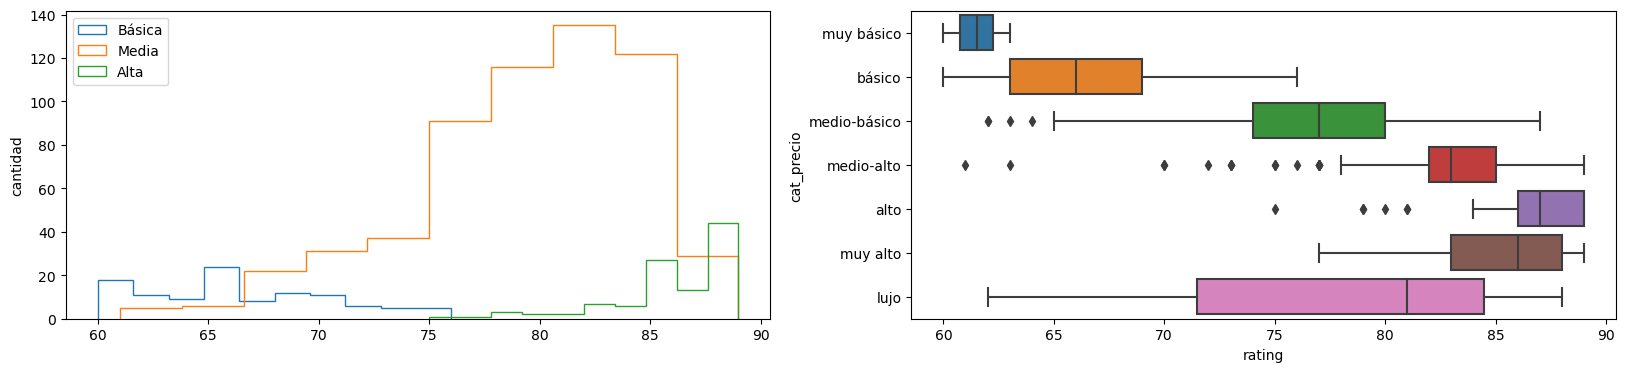

num_cores


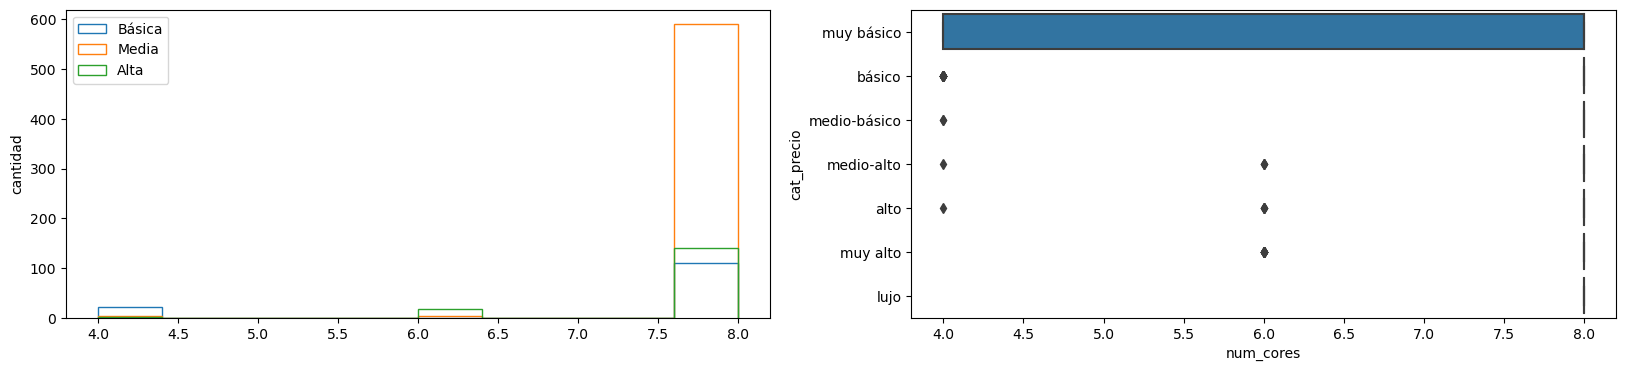

processor_speed


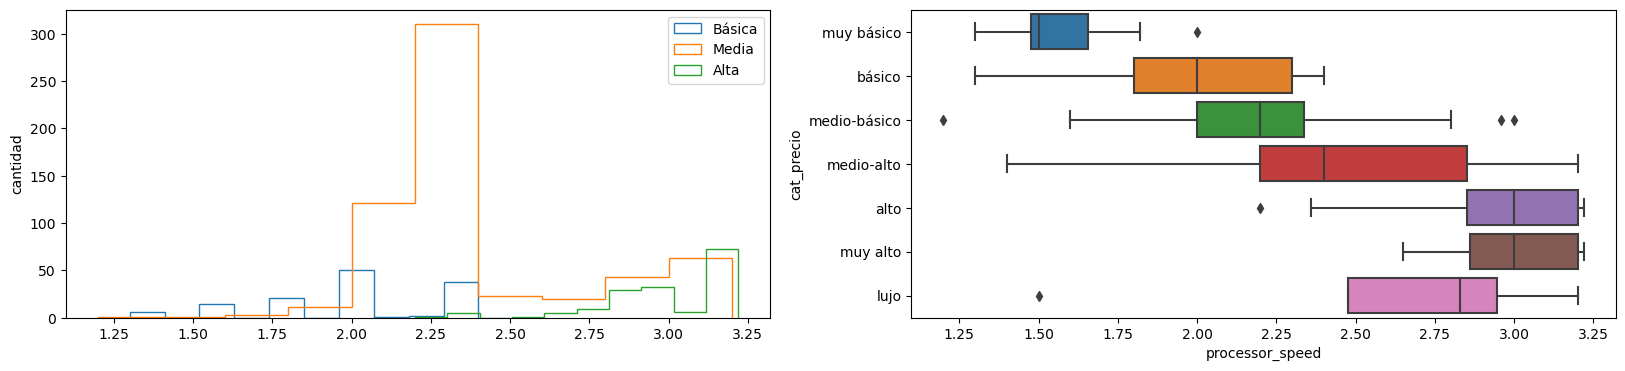

battery_capacity


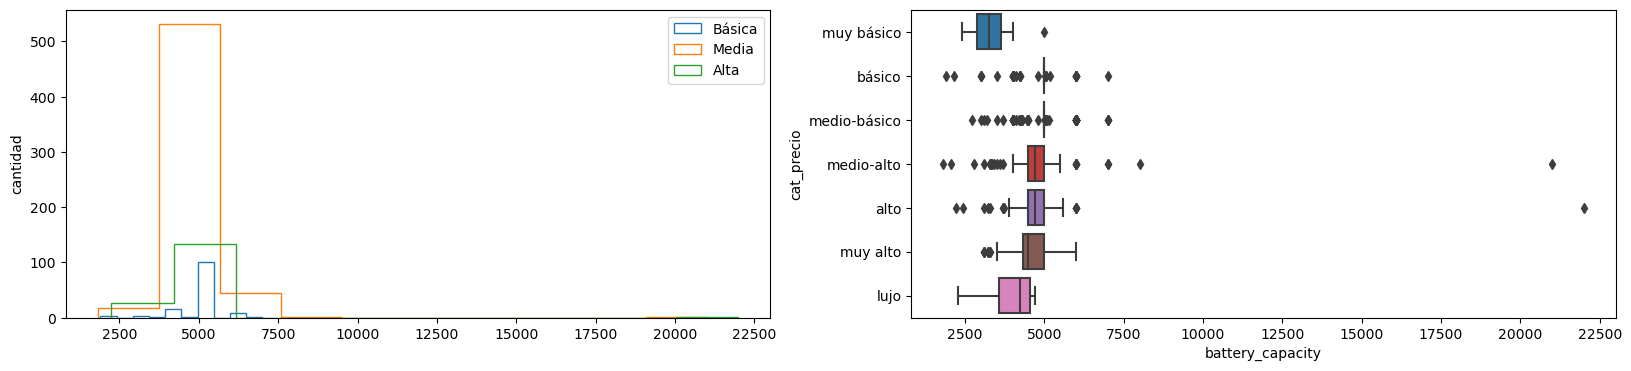

fast_charging


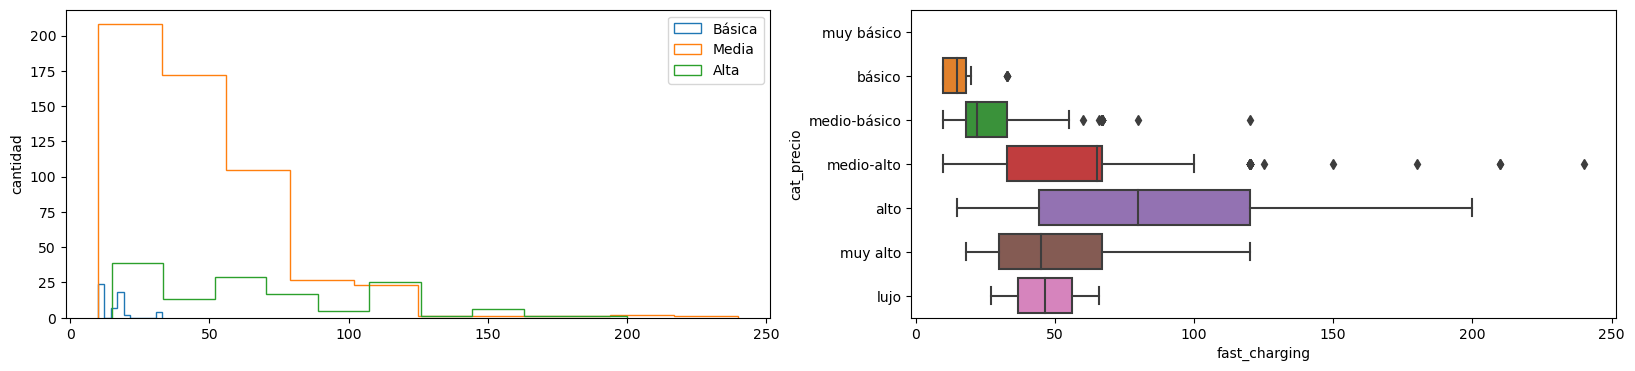

ram_capacity


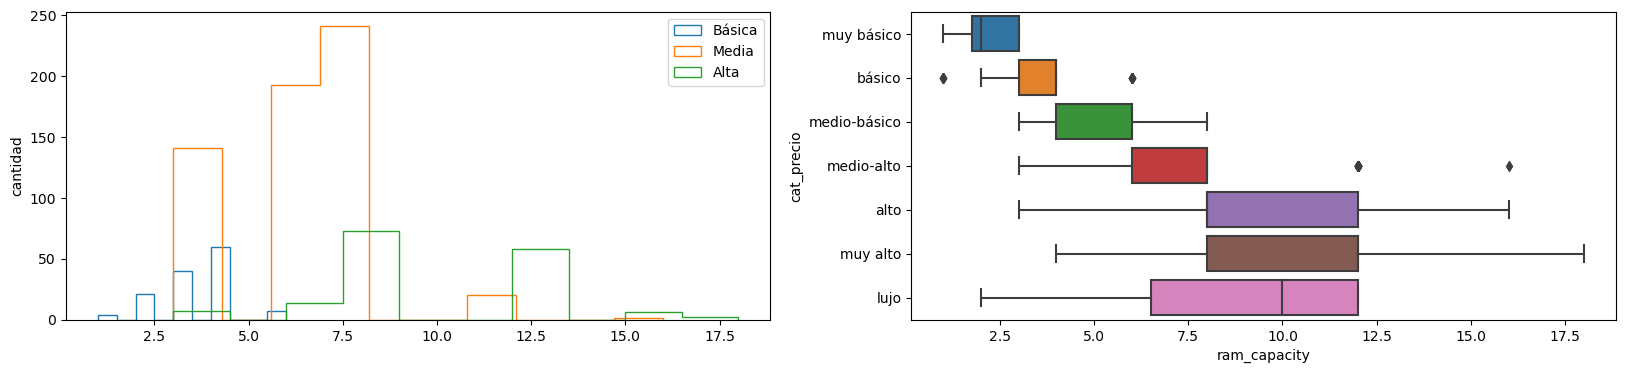

internal_memory


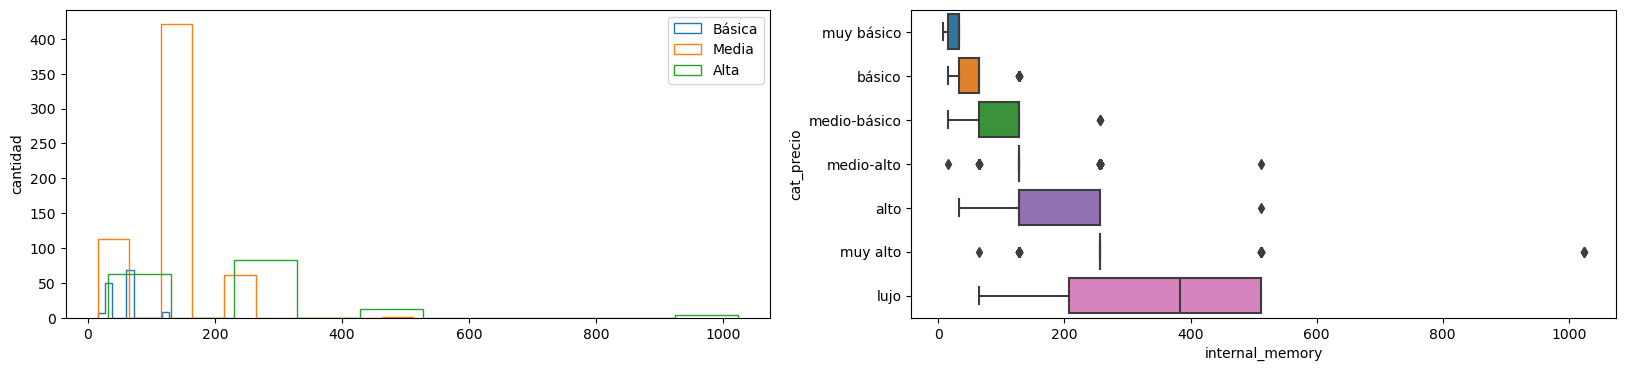

screen_size


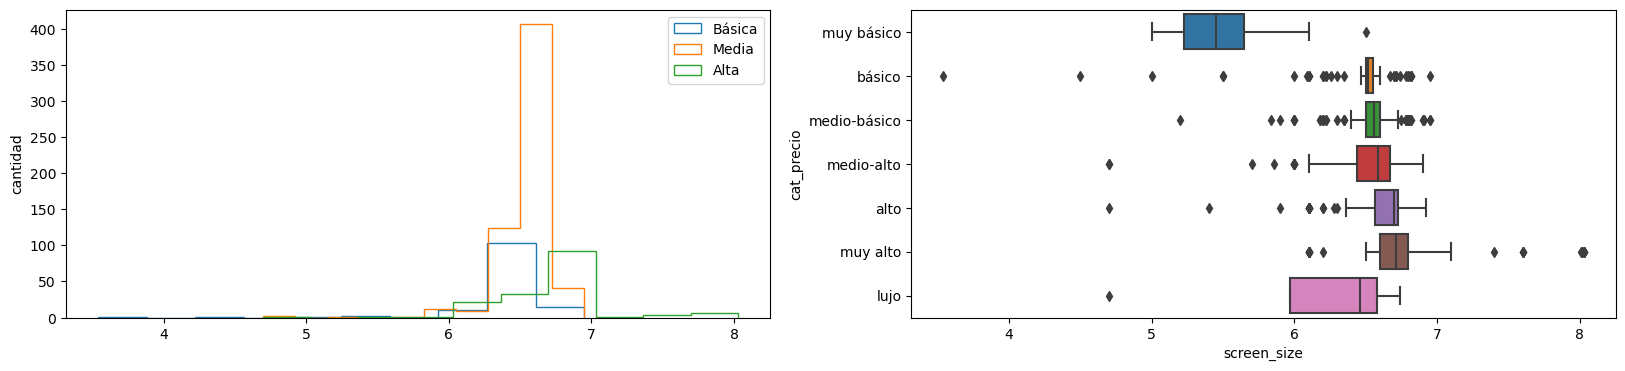

refresh_rate


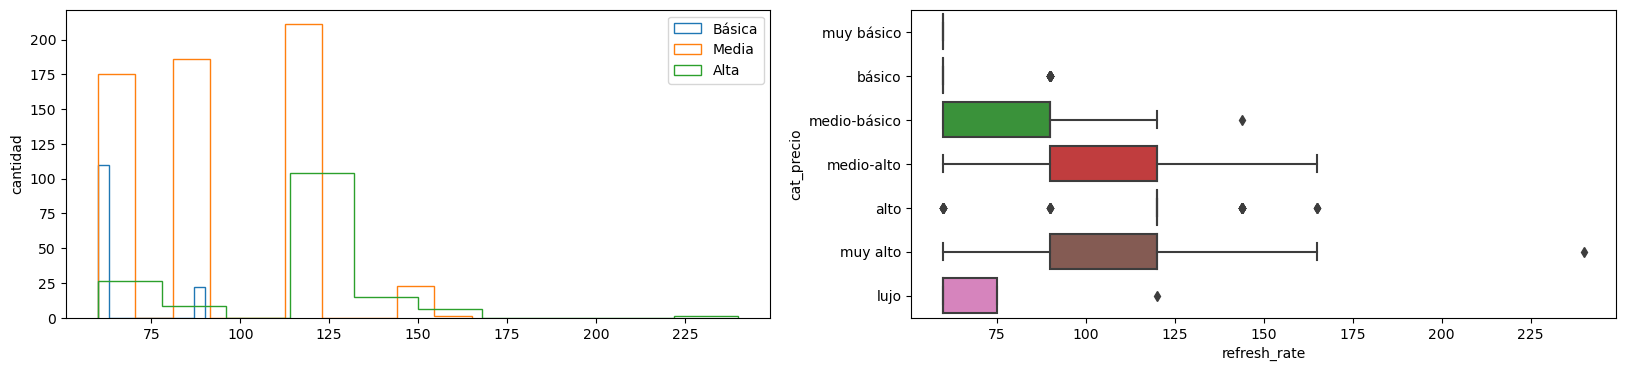

num_rear_cameras


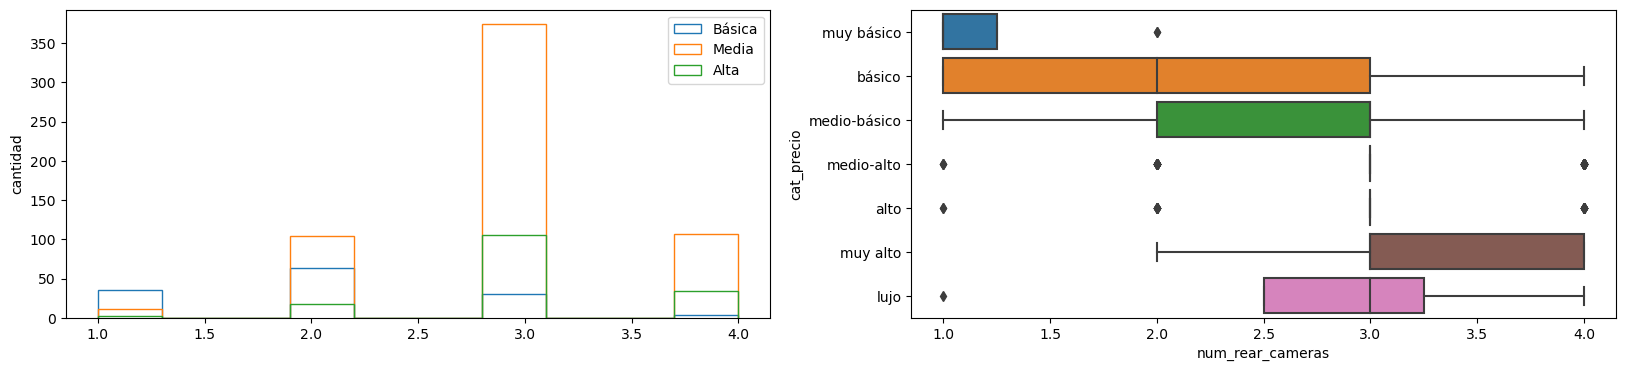

num_front_cameras


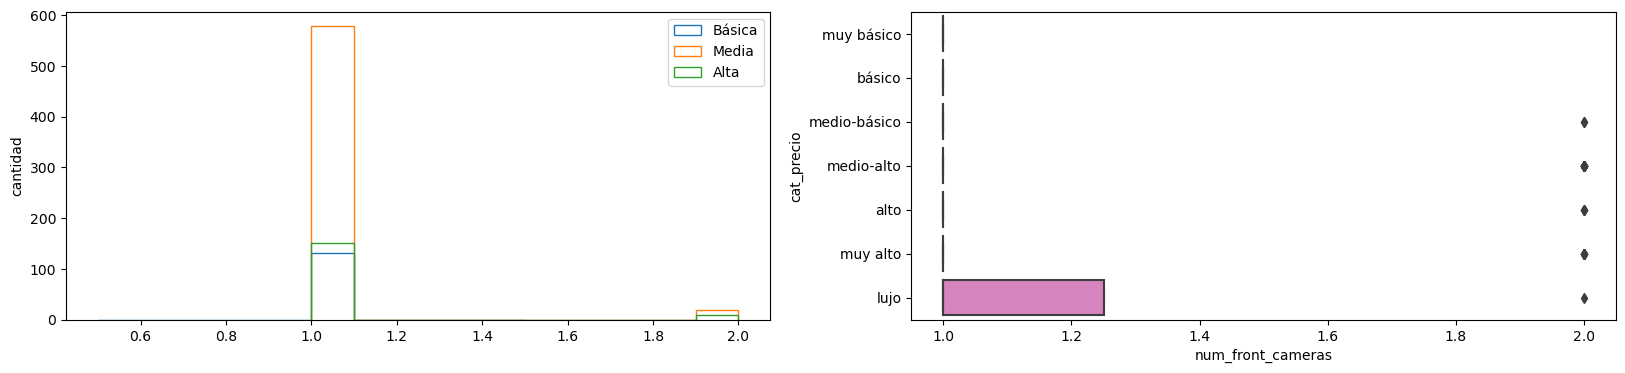

primary_camera_rear


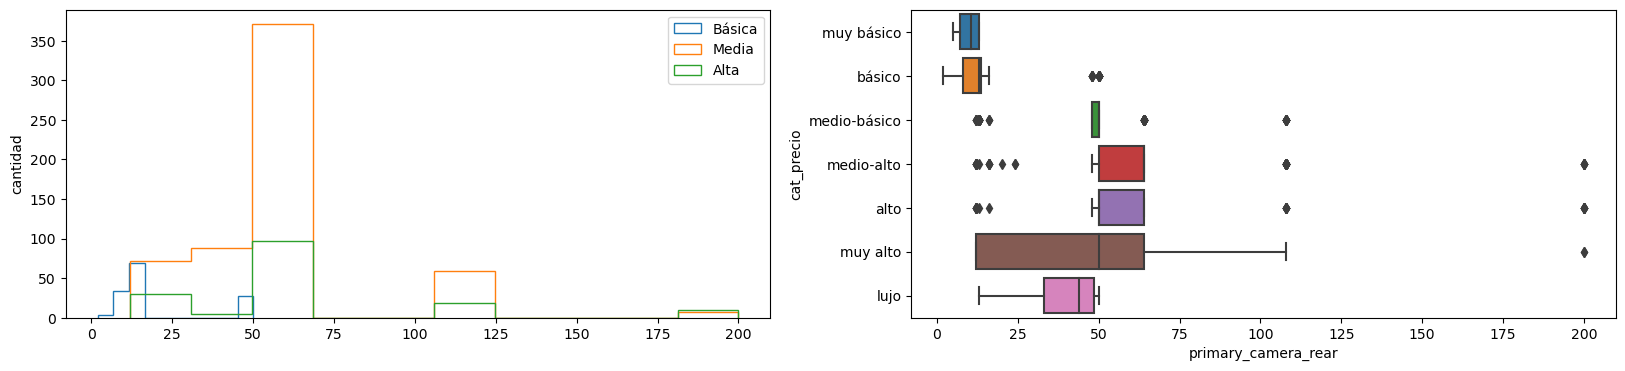

primary_camera_front


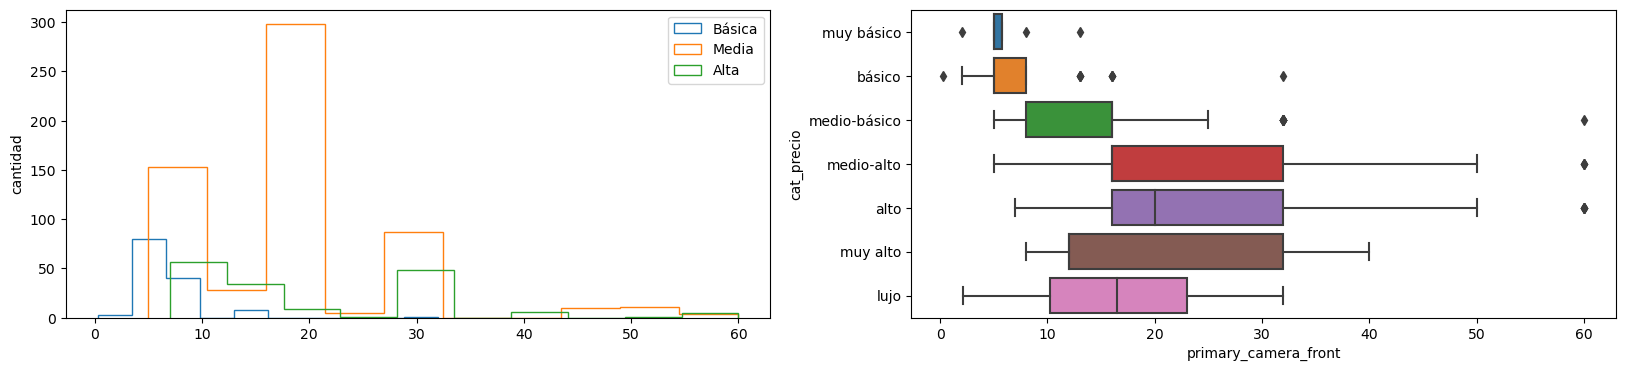

extended_upto


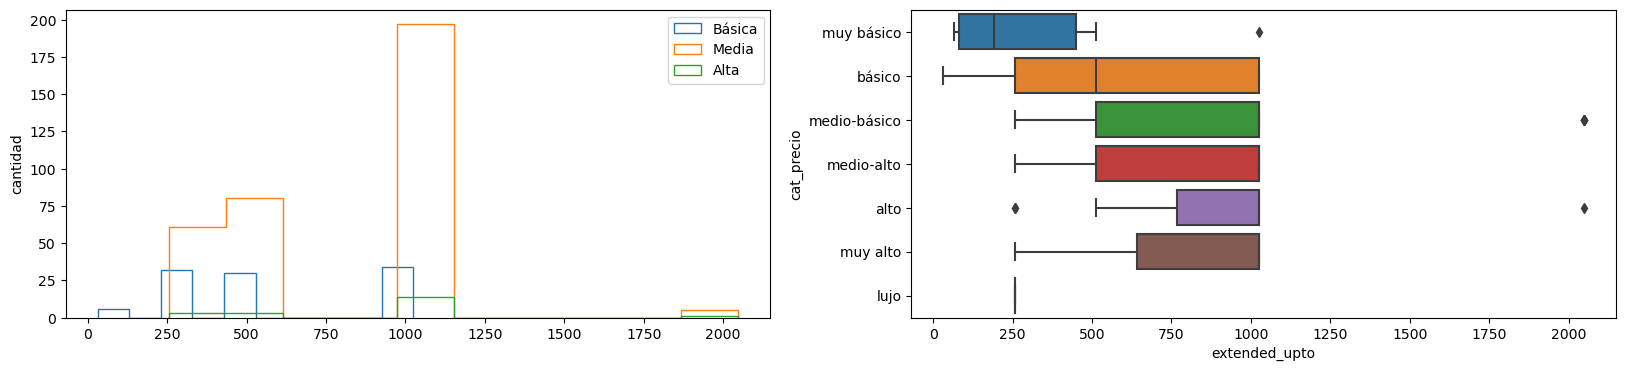

resolution_width


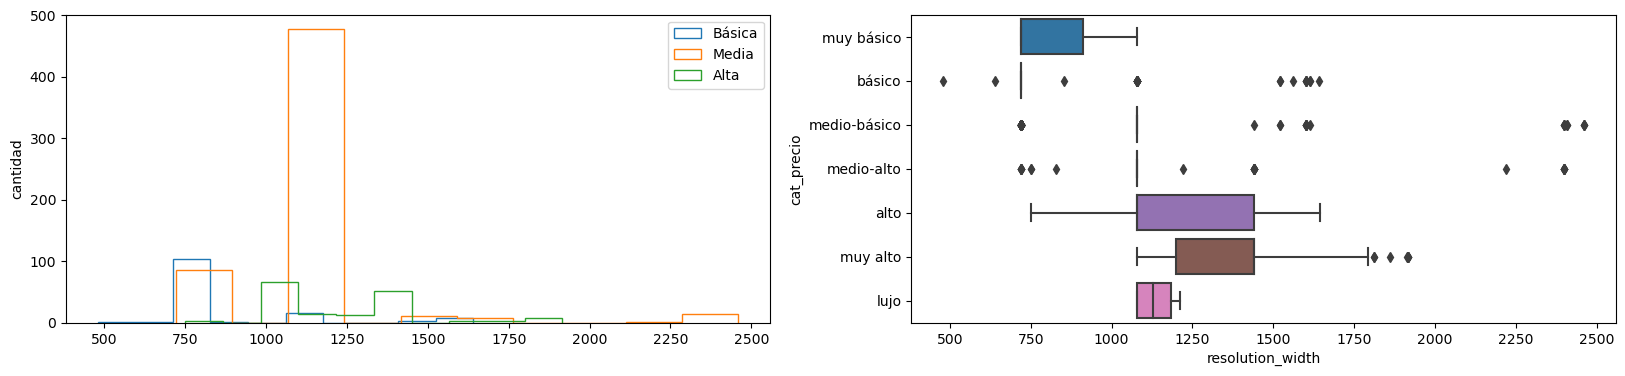

resolution_height


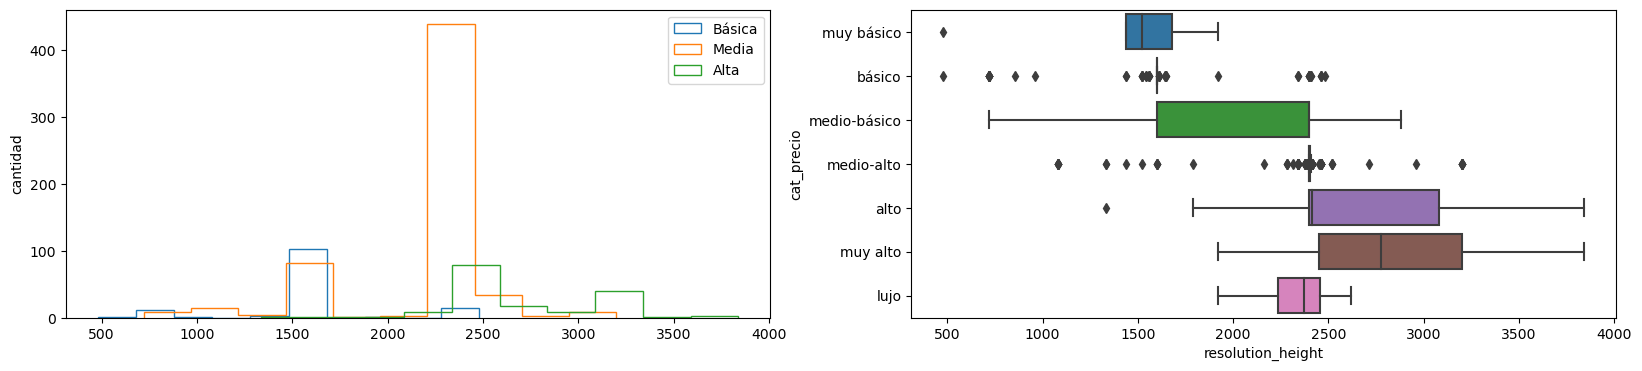

precio_eur


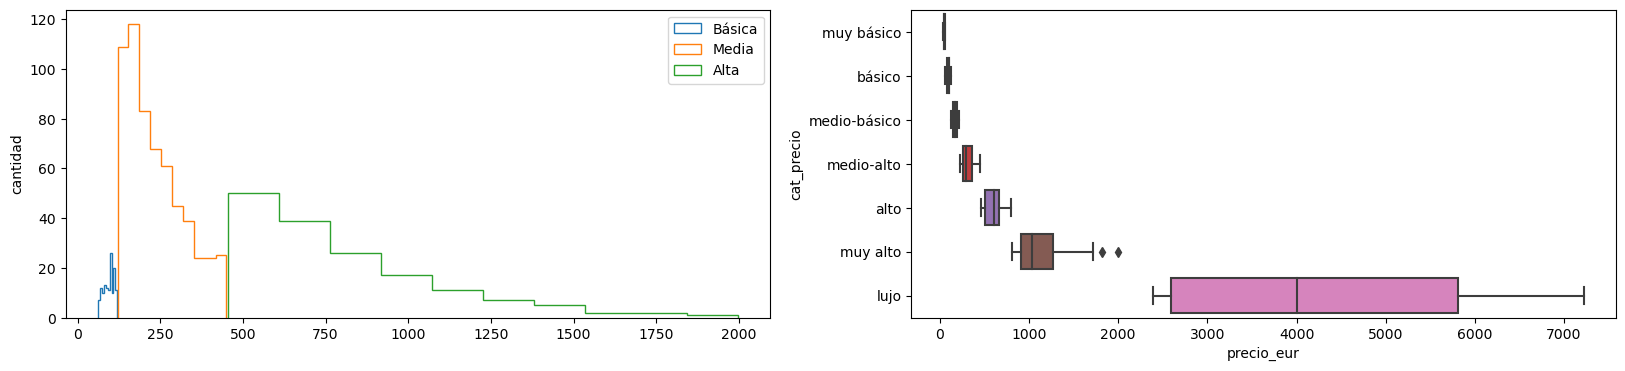

In [24]:
for col in num_cols:
    print(col)
    plt.figure(figsize = (20, 4))
    plt.subplot(1, 2, 1)
    # df_f[col].hist(grid=False, by=df_f['cat_precio'])
    # df_f[col].hist(grid=False)
    plt.hist(df_gbas[col], histtype='step', label='Básica')
    plt.hist(df_gmed[col], histtype='step', label='Media')
    plt.hist(df_galt[col], histtype='step', label='Alta')
    plt.ylabel('cantidad')
    plt.legend()
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df_f[col], y=df_f['cat_precio'])
    # sns.violinplot(x=df_f[col], y=df_f['cat_precio'])
    plt.show()

Observaciones: 
- Las valoraciones dadas a los móviles se concentran en el intervalo 75-85. La valoración dada a los móviles crece con el precio hasta la gama de precio alta, decreciendo posteriormente en las gamas muy alta y de lujo. 
- La gran mayoría de móviles tienen procesadores con 8 núcleos. 
- La velocidad de los procesadores tiende a crecer con el precio hasta la gama de precios alta. 
- La capacidad de la batería de los móviles se concentra en torno a 5000 mAh. No cambia significativamente en una amplia gama de precios, y es menor en la gama de lujo y sobre todo en la gama muy básica. 
- La potencia de carga rápida tiende a crecer desde la gama de precios básica hasta la alta. 
- La capacidad de RAM tiende a crecer con el precio hasta la gama de precios alta. 
- La capacidad de almacenamiento tiende a crecer con el precio. 
- El tamaño de pantalla tiende a crecer con el precio hasta la gama de lujo, observándose la diferencia más notable entre la gama muy básica y el resto de gamas. 
- La frecuencia de refresco tiende a ser más alta con el precio, hasta la gama de precios alta. 
- Nº de cámaras traseras: lo más típico en los móviles de gama básica es que tengan 1 ó 2 cámaras traseras. En los de gama media y alta, 3. 
- Las resoluciones de las cámaras de los móviles de gama básica es inferior a las de los móviles de las gamas medias y altas. 
- La resolución de pantalla tiende a crecer con el precio. 
- Algunas de las variables numéricas en las que se observa una correlación más clara con el precio: 
   - rating
   - processor_speed
   - fast_charging
   - ram_capacity
   - internal_memory
   - refresh_rate
   - num_rear_cameras
   - primary_camera_rear
   - resolution_width

Violin plots:

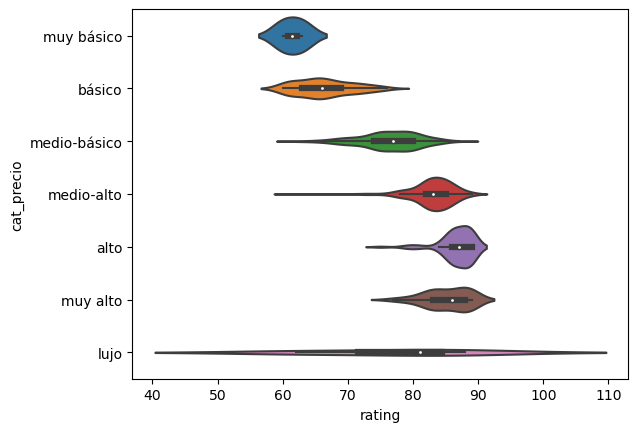

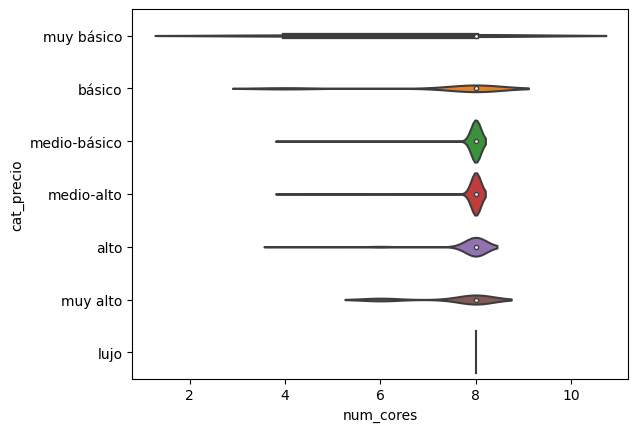

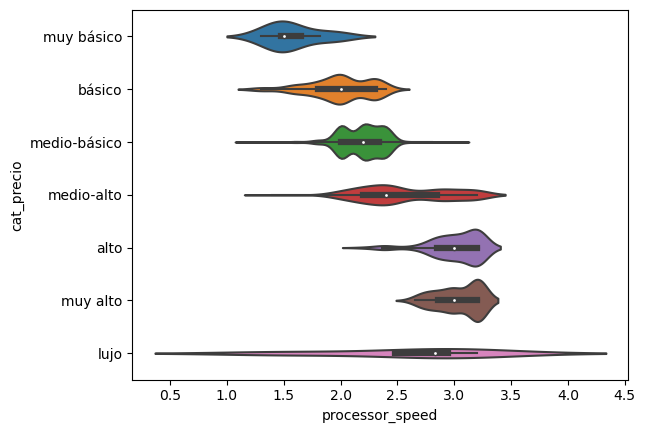

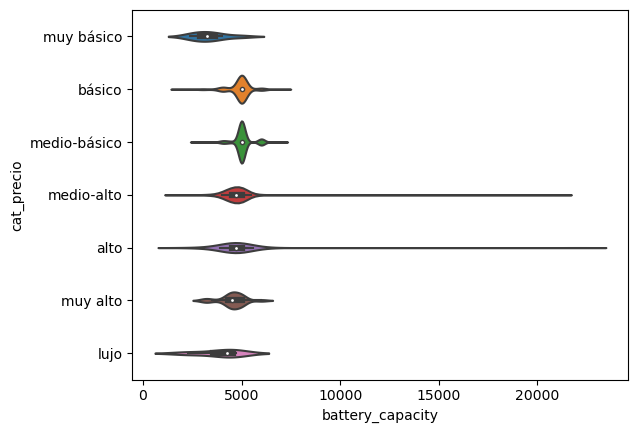

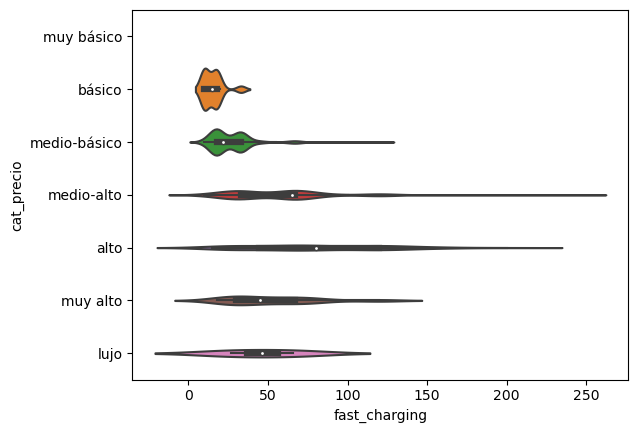

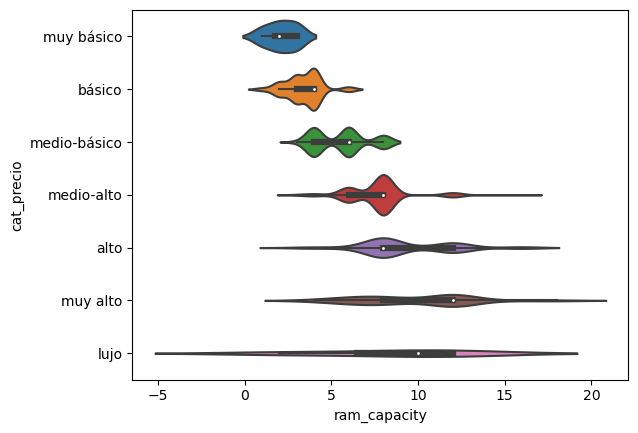

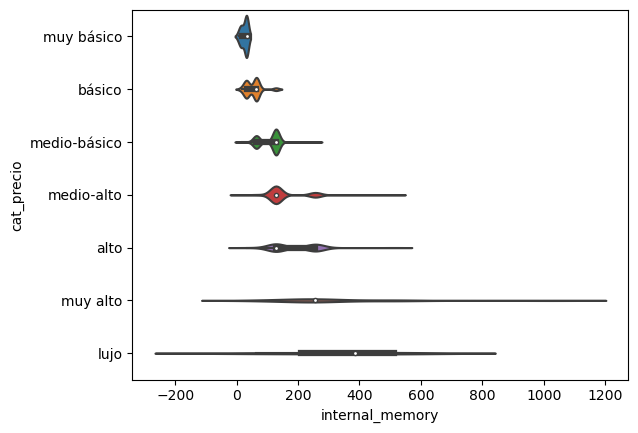

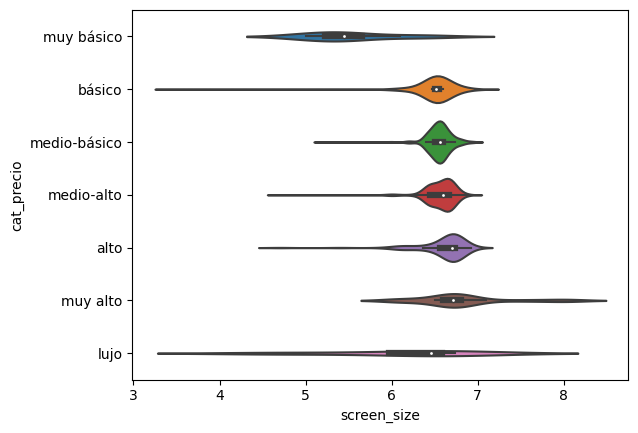

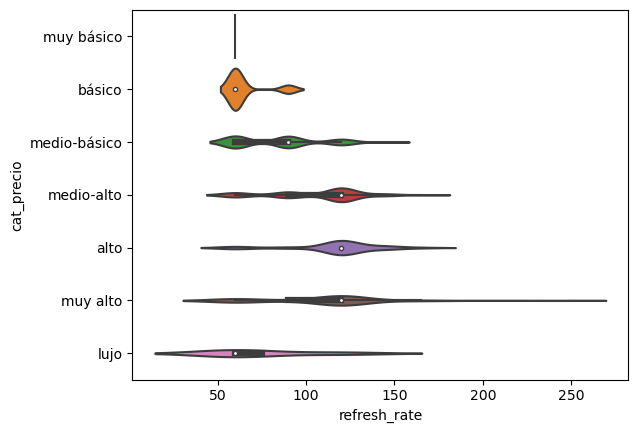

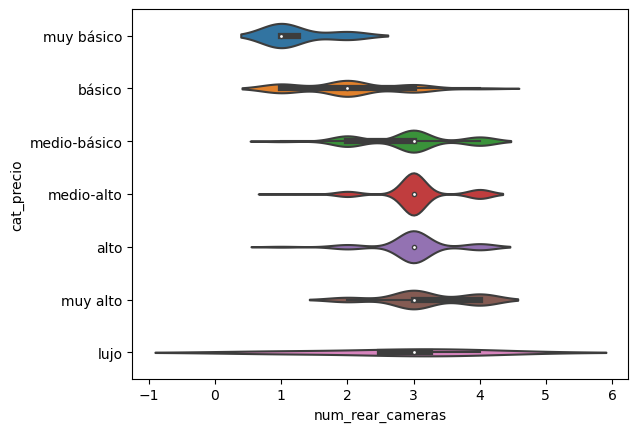

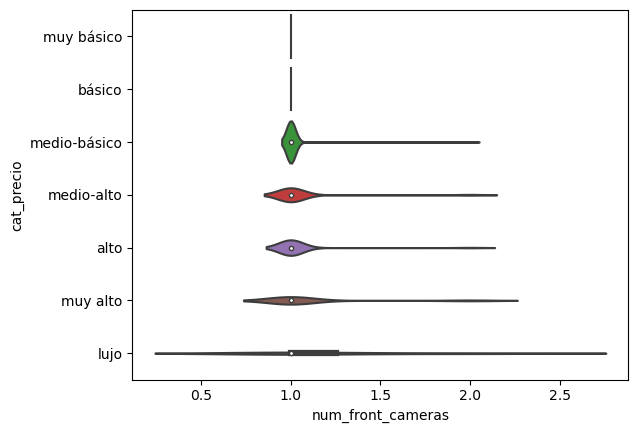

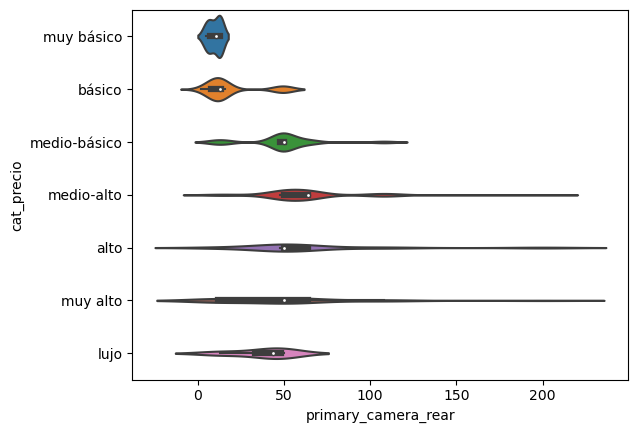

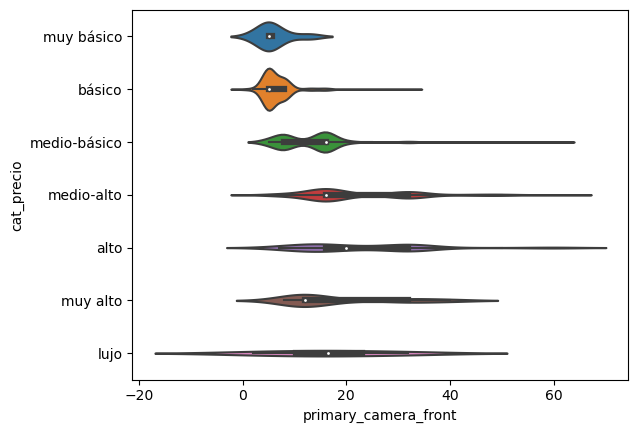

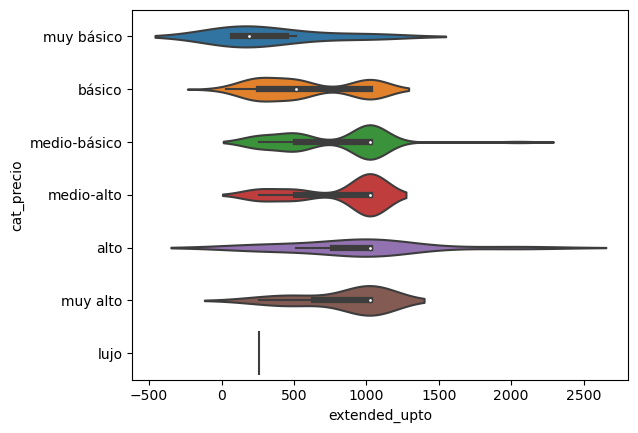

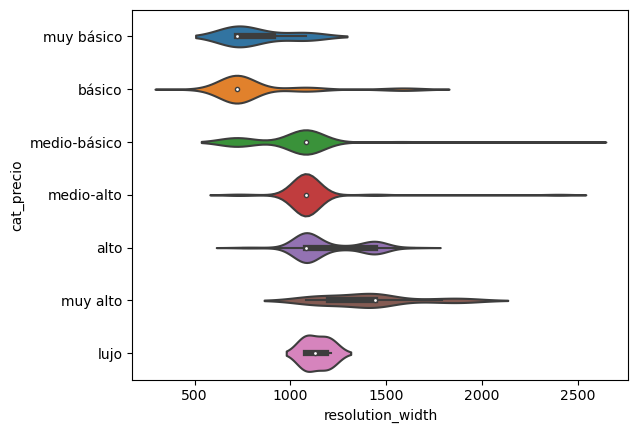

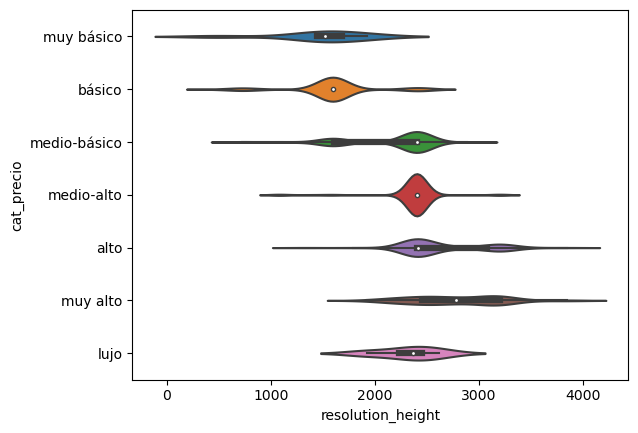

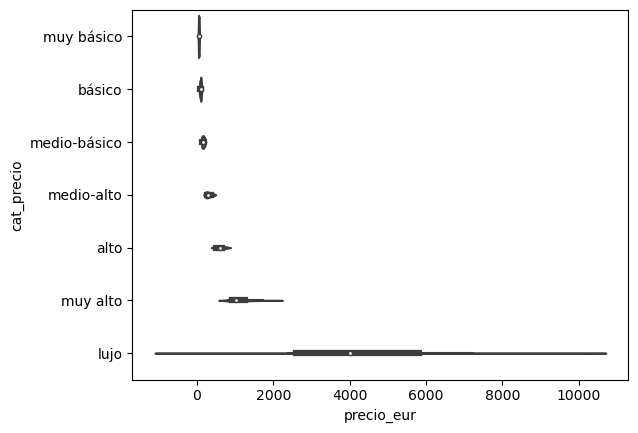

In [25]:
for col in num_cols:
    sns.violinplot(x=df_f[col], y=df_f['cat_precio'])
    plt.show()

#### <a id='toc1_4_1_2_'></a>[4.1.2. Variables categóricas y booleanas](#toc0_)

Diagramas de barras para las variables categóricas/booleanas: 

brand_name


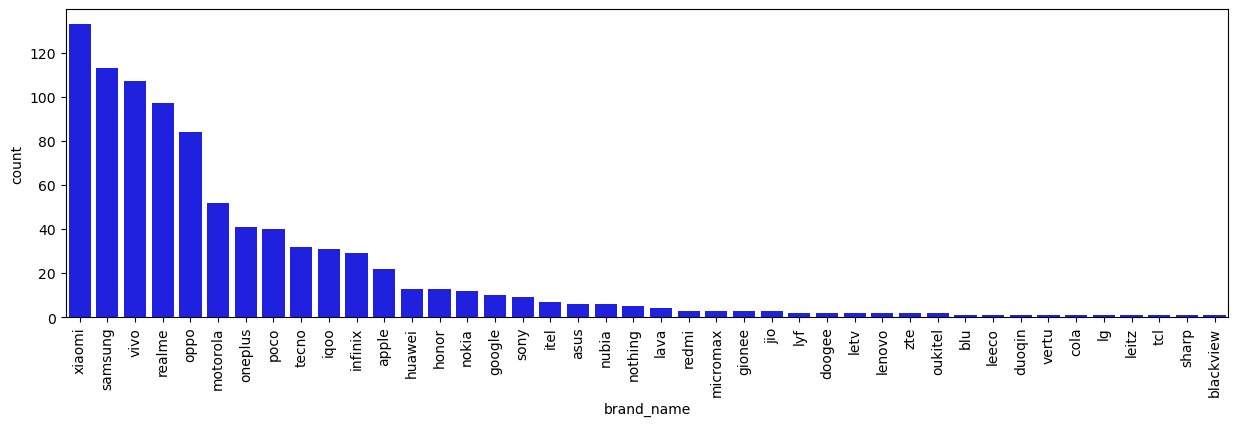

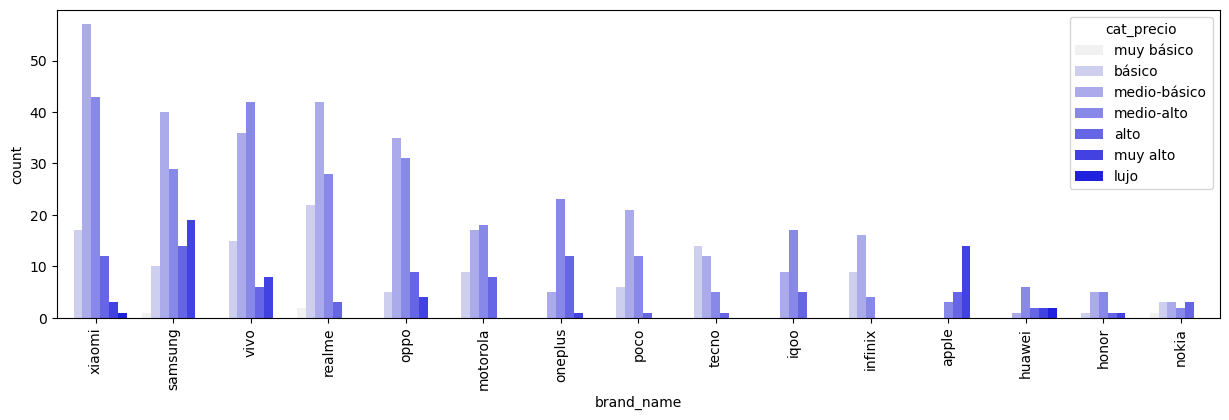

processor_brand


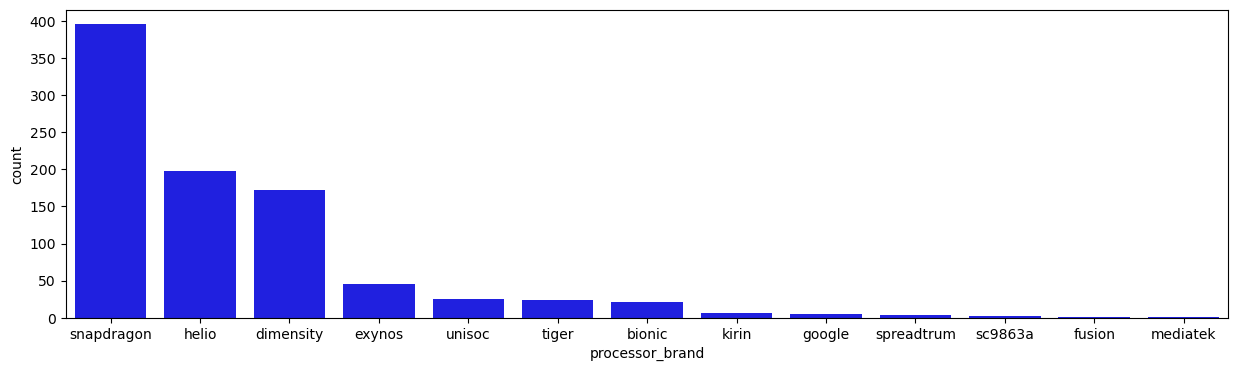

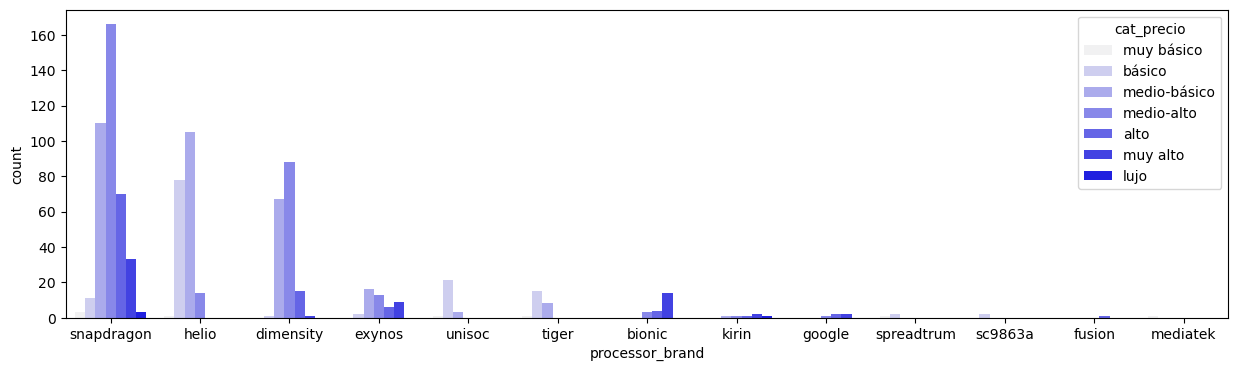

os


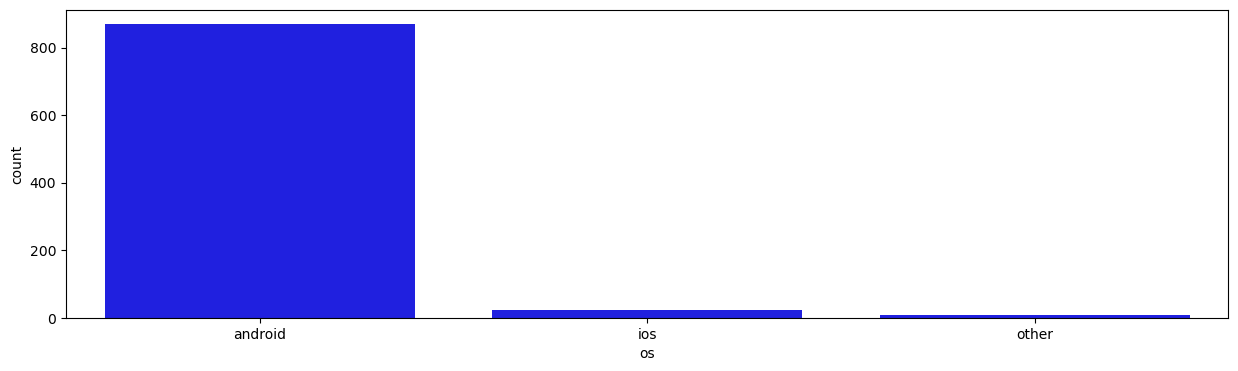

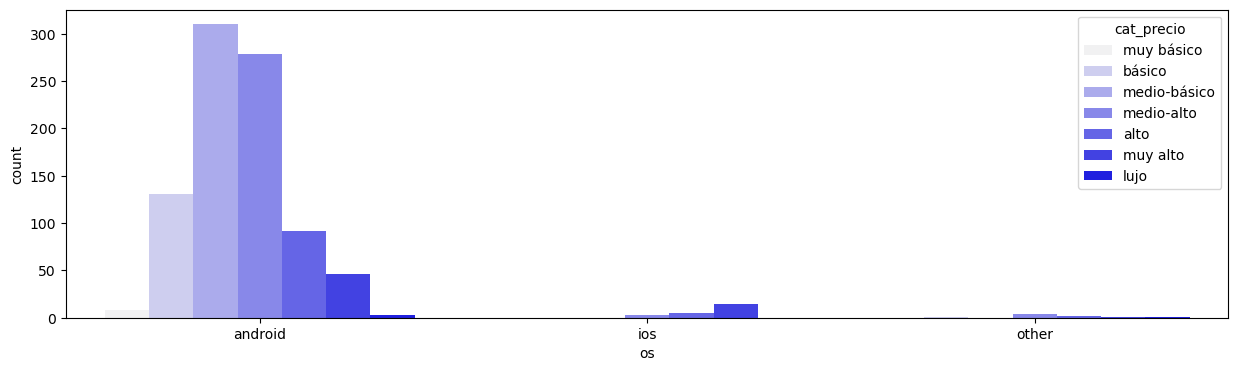

cat_precio


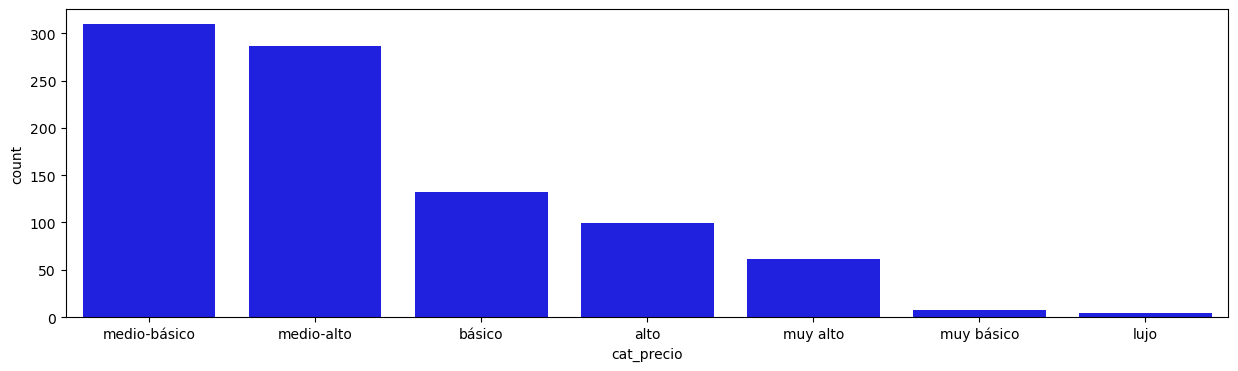

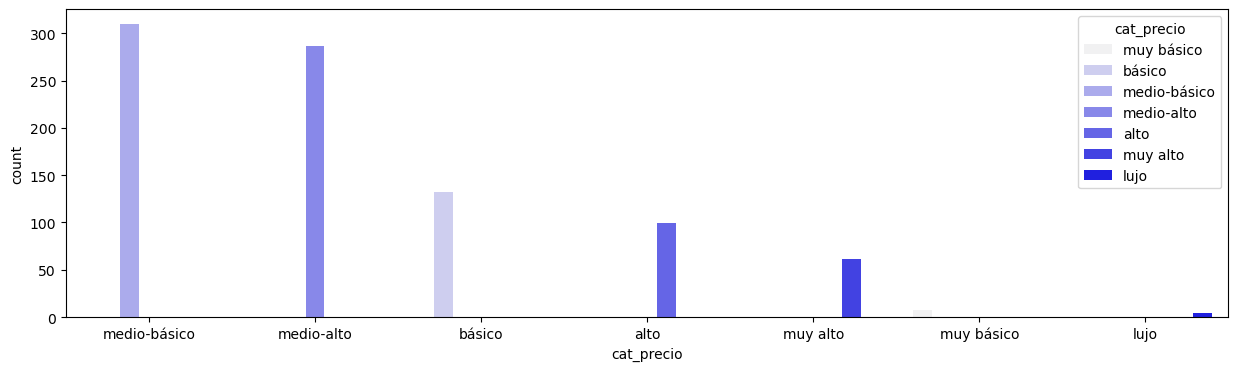

In [26]:
# for col in cat_cols_sin_mdl + bool_cols:
for col in cat_cols_sin_mdl:
    print(col)
    plt.figure(figsize = (15, 4))
    sns.countplot(x = col, data = df_f, color = 'blue', 
              order = df_f[col].value_counts().index);
    if df_f[col].nunique() > 20:
        plt.xticks(rotation=90)
    plt.figure(figsize = (15, 4))
    sns.countplot(x = col, data = df_f, color = 'blue', hue=df_f['cat_precio'],
                order = df_f[col].value_counts().index[:min(15, df_f[col].nunique())]);
    if df_f[col].nunique() > 20:
        plt.xticks(rotation=90)
    plt.show()

Observaciones: 
- La mayoría de modelos del dataset se concentran en la gama de precios media. Como excepción, la mayor parte de los modelos de Apple están en la gama de precios muy alta. También hay bastantes modelos de Samsung en la gama de precios muy alta, aunque menos que en las gamas medias. 
- Las marcas de procesadores dominantes son snapdragon, helio y dimensity. Los de los Apple son bionic, con 6 núcleos frente a los 8 núcleos de la mayoría del resto de móviles. 
- La inmensa mayoría de los móviles tiene sistema operativo Android. El de los Apple es ios. 

has_5g


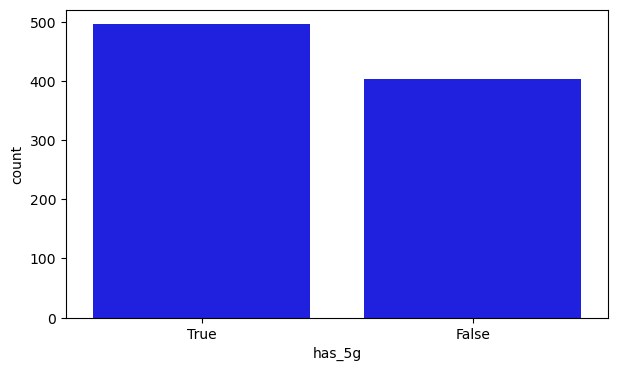

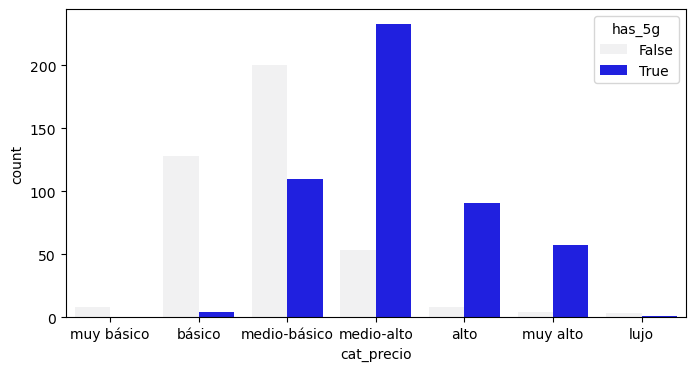

has_nfc


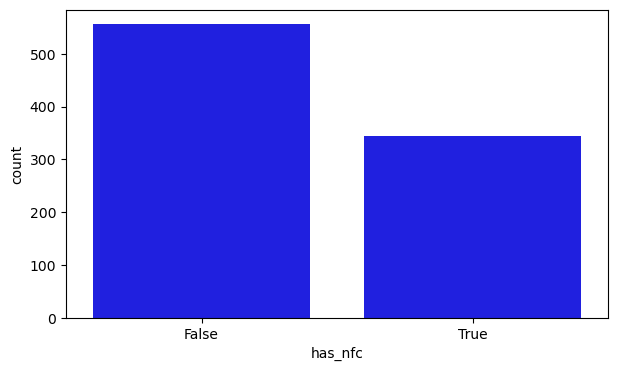

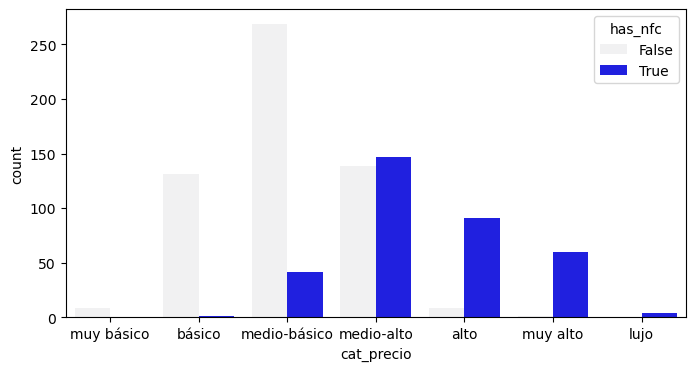

has_ir_blaster


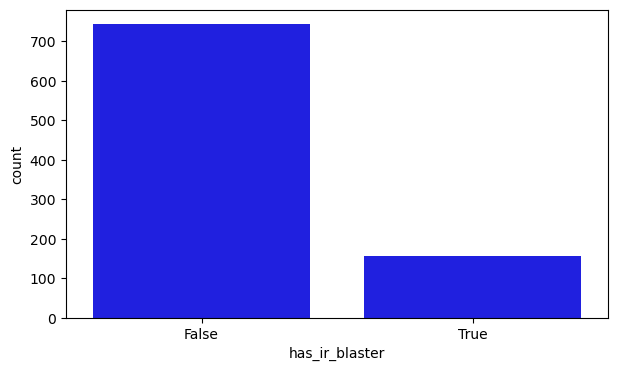

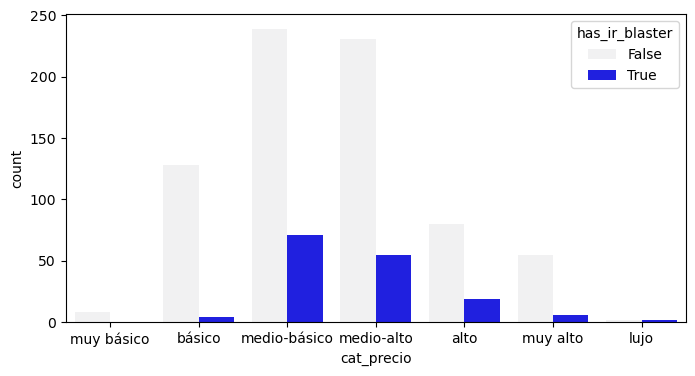

fast_charging_available


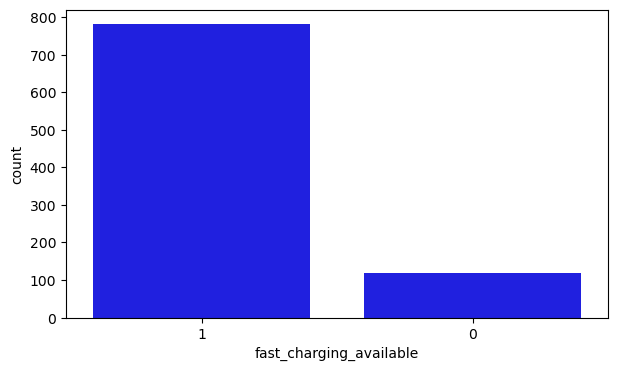

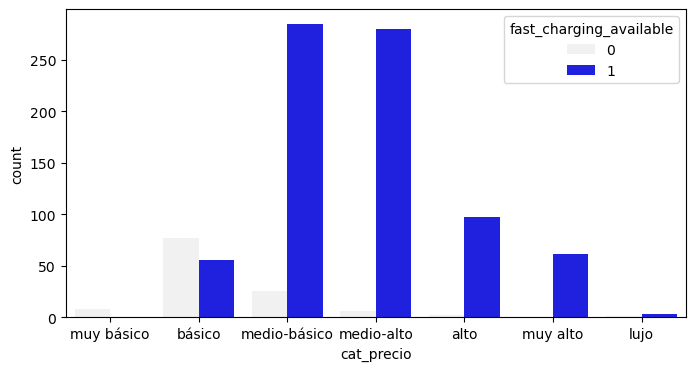

extended_memory_available


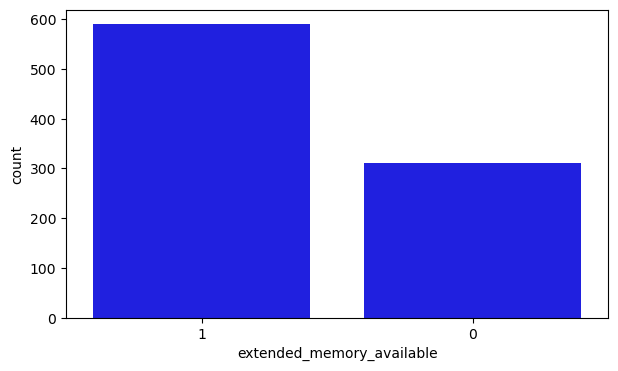

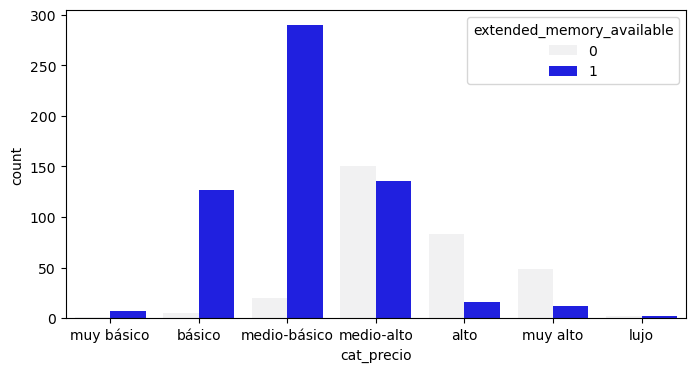

In [27]:
for col in bool_cols:
    print(col)
    plt.figure(figsize = (7, 4))
    sns.countplot(x = col, data = df_f, color = 'blue', 
              order = df_f[col].value_counts().index);
    if df_f[col].nunique() > 20:
        plt.xticks(rotation=90)
    plt.figure(figsize = (8, 4))
    sns.countplot(x = df_f['cat_precio'], data = df_f, color = 'blue', hue=col);
    if df_f[col].nunique() > 20:
        plt.xticks(rotation=90)
    plt.show()

Observaciones: 
- 5G: 
   - La cantidad de móviles con 5G en el dataset es ligeramente superior a la cantidad sin 5G. 
   - La proporción de móviles con 5G crece en gamas de precios más altas. 
- NFC: 
   - Hay bastantes más móviles sin NFC que con NFC. 
   - La proporción de móviles con NFC crece en gamas de precios más altas. Casi ningún móvil de los rangos de precio menores tiene NFC, y casi todos los de las gamas de precios más altas tiene NFC. 
- Puntero IR: 
   - Pocos móviles tienen puntero IR en todas las gamas, encontrándose sobre todo en la gama media. 
- Carga rápida: 
   - La gran mayoría de móviles del dataset tiene capacidad de carga rápida. Solo en las gamas más básicas hay una proporción no muy baja de móviles sin carga rápida. 
- Extensión de memoria. 
   - Hay bastantes más móviles con esta capacidad que sin ella, encontrándose sobre todo en las gamas media y baja. 

### <a id='toc1_4_2_'></a>[4.2. Análisis bivariante](#toc0_)

### <a id='toc1_4_2_1_'></a>[4.2.1. Heatmaps de correlación entre variables numéricas](#toc0_)

In [28]:
num_cols_slc = ['rating', 'processor_speed', 'battery_capacity','ram_capacity', 'internal_memory', 'refresh_rate', 'primary_camera_rear', 'extended_upto','resolution_height', 'precio_eur']

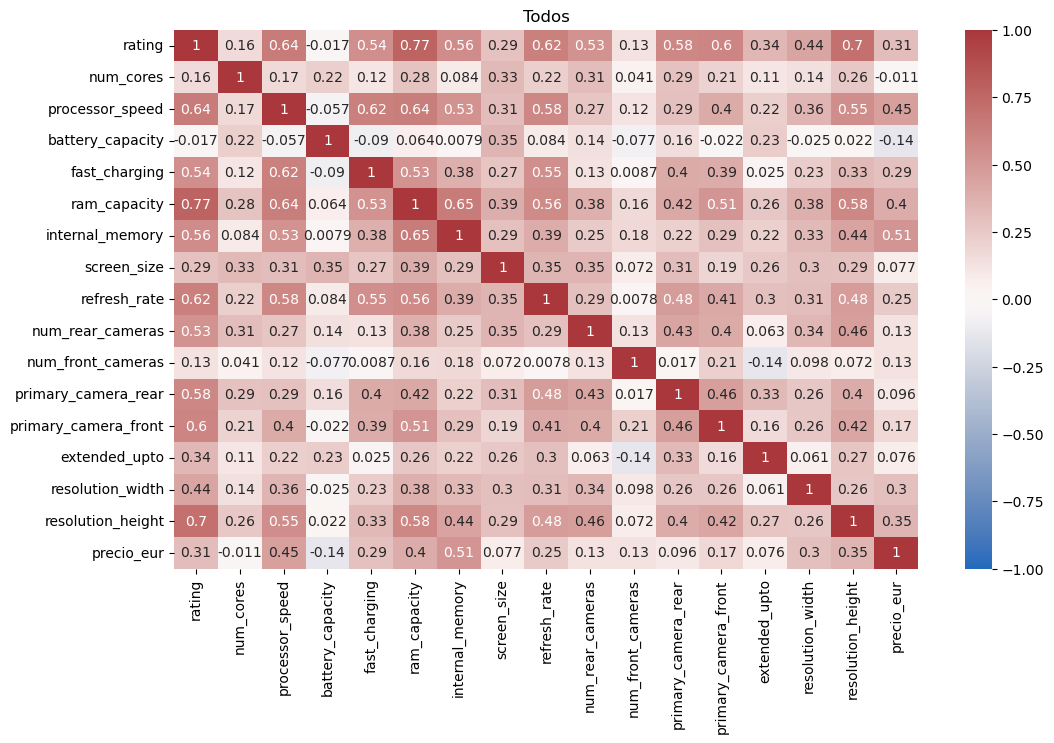

Valores de correlación de Pearson para rating de todos los móviles: 
rating                  1.000000
ram_capacity            0.774953
resolution_height       0.704479
processor_speed         0.641525
refresh_rate            0.620517
primary_camera_front    0.595668
primary_camera_rear     0.578248
internal_memory         0.559507
fast_charging           0.541485
num_rear_cameras        0.527066
resolution_width        0.436965
extended_upto           0.340705
precio_eur              0.309618
screen_size             0.285459
num_cores               0.158223
num_front_cameras       0.132736
battery_capacity       -0.016502
Name: rating, dtype: float64

Valores de correlación de Pearson para precio de todos los móviles: 
precio_eur              1.000000
internal_memory         0.514956
processor_speed         0.454490
ram_capacity            0.396808
resolution_height       0.345243
rating                  0.309618
resolution_width        0.301105
fast_charging           0.291489
refresh

In [29]:
m_corr_num_cols = df_f[num_cols].corr()

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_num_cols, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Todos')
plt.show()
print('Valores de correlación de Pearson para rating de todos los móviles: ')
print(m_corr_num_cols['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Pearson para precio de todos los móviles: ')
print(m_corr_num_cols['precio_eur'].sort_values(ascending=False))

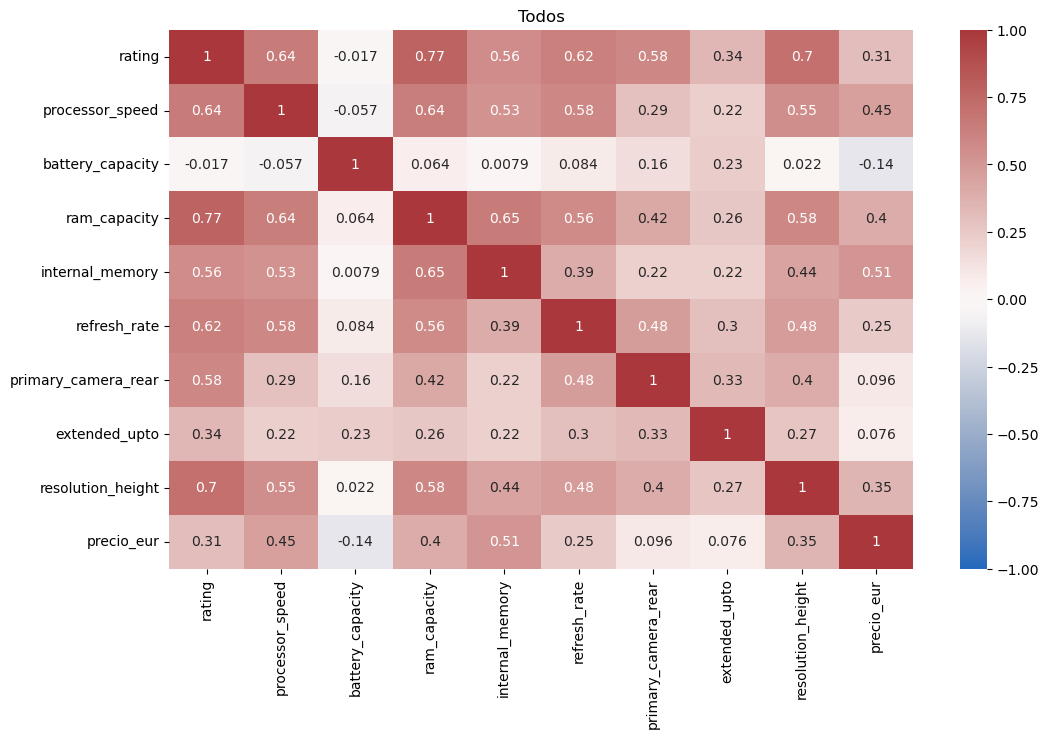

In [30]:
plt.figure(figsize=(12, 7))
sns.heatmap(m_corr_num_cols.loc[num_cols_slc, num_cols_slc], annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Todos')
plt.show()

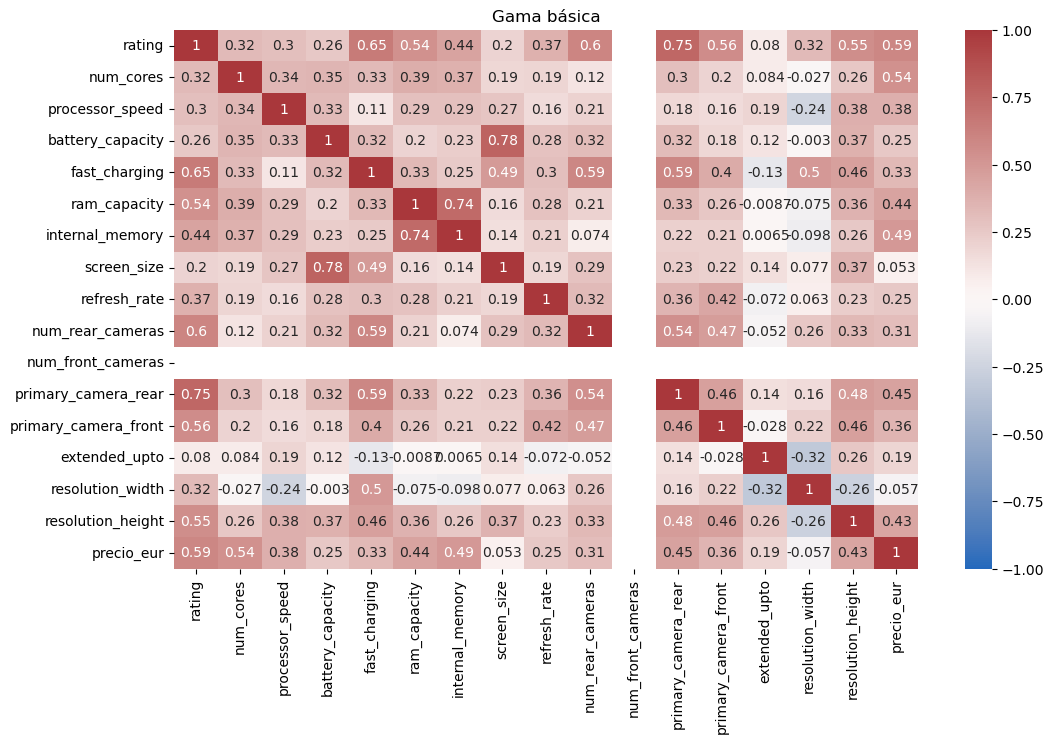

Valores de correlación de Pearson para rating de los móviles de gama básica: 
rating                  1.000000
primary_camera_rear     0.754769
fast_charging           0.650698
num_rear_cameras        0.598668
precio_eur              0.589619
primary_camera_front    0.556740
resolution_height       0.550255
ram_capacity            0.536393
internal_memory         0.439752
refresh_rate            0.369005
num_cores               0.324000
resolution_width        0.322651
processor_speed         0.301555
battery_capacity        0.255924
screen_size             0.201250
extended_upto           0.079931
num_front_cameras            NaN
Name: rating, dtype: float64

Valores de correlación de Pearson para precio de los móviles de gama básica: 
precio_eur              1.000000
rating                  0.589619
num_cores               0.535090
internal_memory         0.494491
primary_camera_rear     0.449624
ram_capacity            0.438496
resolution_height       0.431058
processor_speed       

In [31]:
m_corr_num_cols_b = df_gbas[num_cols].corr()

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_num_cols_b, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama básica')
plt.show()
print('Valores de correlación de Pearson para rating de los móviles de gama básica: ')
print(m_corr_num_cols_b['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Pearson para precio de los móviles de gama básica: ')
print(m_corr_num_cols_b['precio_eur'].sort_values(ascending=False))

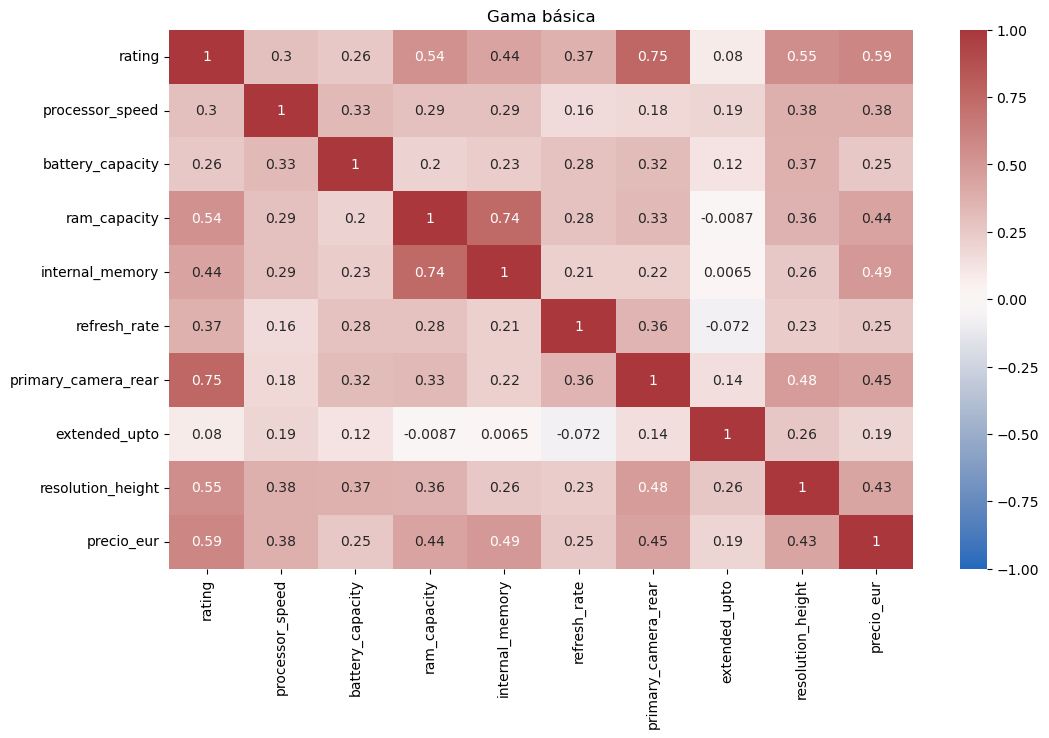

In [32]:
plt.figure(figsize=(12, 7))
sns.heatmap(m_corr_num_cols_b.loc[num_cols_slc, num_cols_slc], annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama básica')
plt.show()

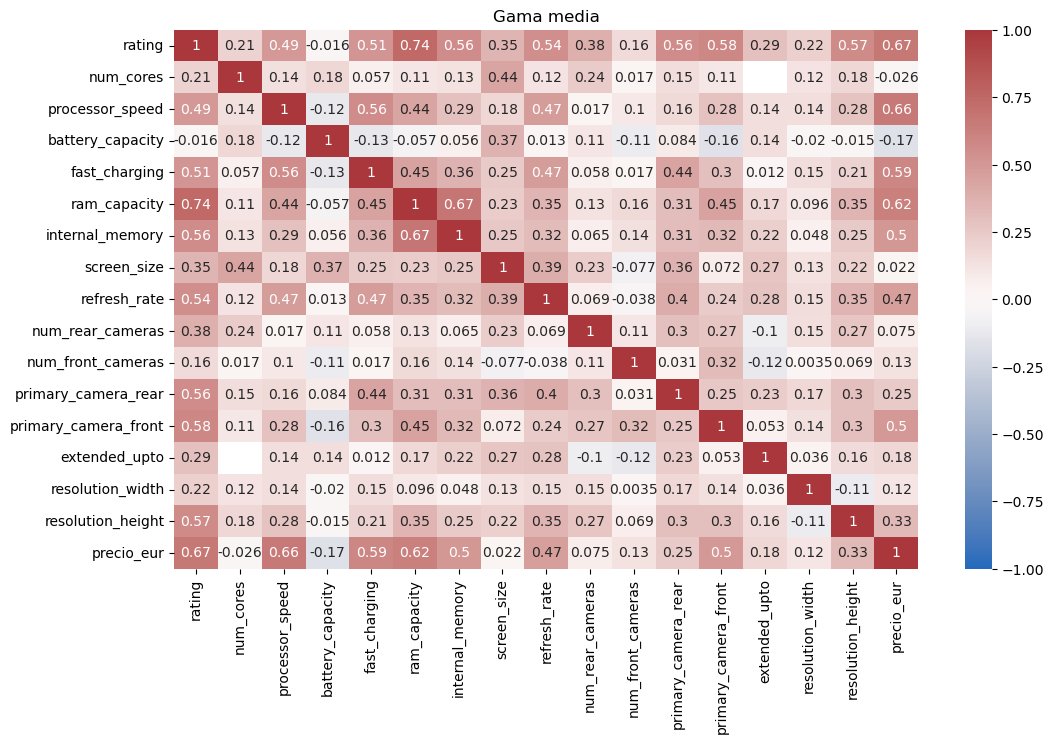

Valores de correlación de Pearson para rating de los móviles de gama media: 
rating                  1.000000
ram_capacity            0.742966
precio_eur              0.665456
primary_camera_front    0.579514
resolution_height       0.568994
primary_camera_rear     0.561315
internal_memory         0.558242
refresh_rate            0.543585
fast_charging           0.510642
processor_speed         0.494825
num_rear_cameras        0.381009
screen_size             0.350151
extended_upto           0.291290
resolution_width        0.217305
num_cores               0.206173
num_front_cameras       0.157490
battery_capacity       -0.015799
Name: rating, dtype: float64

Valores de correlación de Pearson para precio de los móviles de gama media: 
precio_eur              1.000000
rating                  0.665456
processor_speed         0.658817
ram_capacity            0.621646
fast_charging           0.587994
internal_memory         0.501839
primary_camera_front    0.495145
refresh_rate            

In [33]:
# m_corr_num_cols_m = df_gmed[num_cols].corr(method='spearman')
m_corr_num_cols_m = df_gmed[num_cols].corr()

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_num_cols_m, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama media')
plt.show()
print('Valores de correlación de Pearson para rating de los móviles de gama media: ')
print(m_corr_num_cols_m['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Pearson para precio de los móviles de gama media: ')
print(m_corr_num_cols_m['precio_eur'].sort_values(ascending=False))

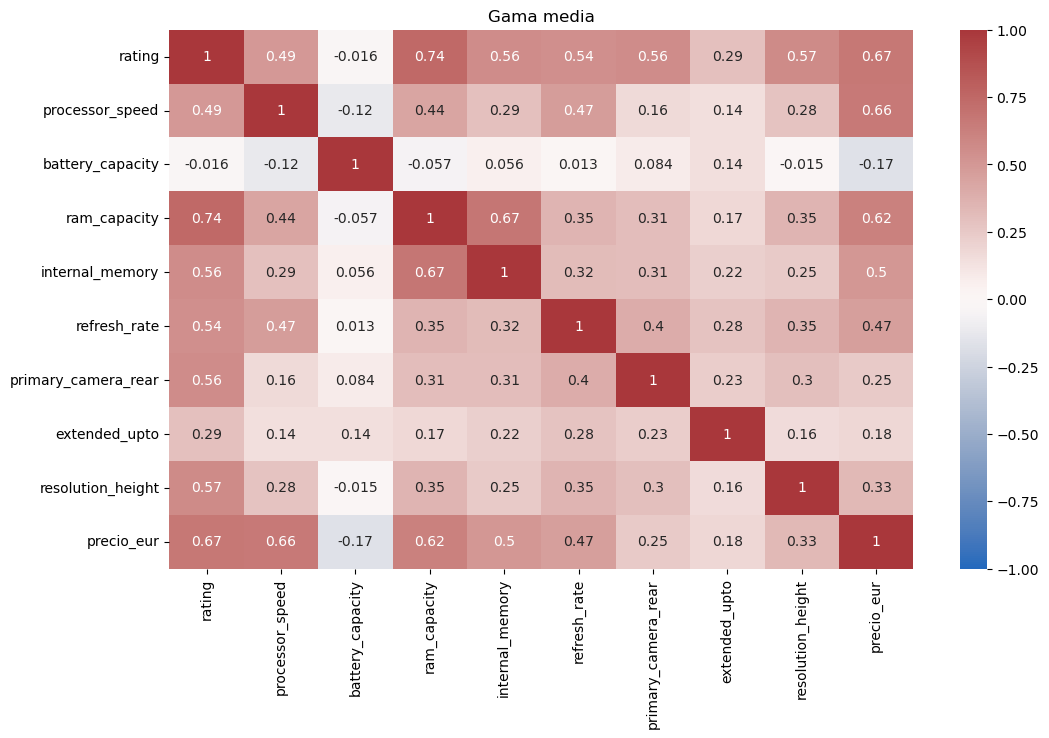

In [34]:
plt.figure(figsize=(12, 7))
sns.heatmap(m_corr_num_cols_m.loc[num_cols_slc, num_cols_slc], annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama media')
plt.show()

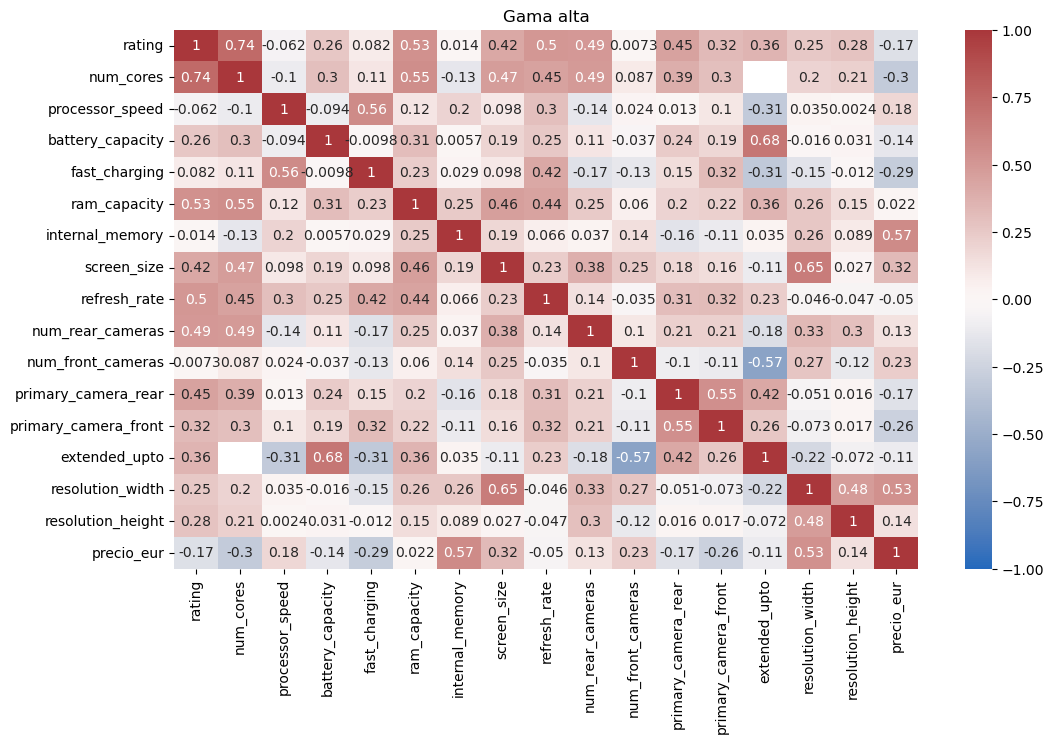

Valores de correlación de Pearson para rating de los móviles de gama alta: 
rating                  1.000000
num_cores               0.737071
ram_capacity            0.534220
refresh_rate            0.503958
num_rear_cameras        0.492246
primary_camera_rear     0.449426
screen_size             0.417107
extended_upto           0.356660
primary_camera_front    0.323235
resolution_height       0.279393
battery_capacity        0.263369
resolution_width        0.253728
fast_charging           0.082313
internal_memory         0.014321
num_front_cameras       0.007345
processor_speed        -0.062451
precio_eur             -0.174557
Name: rating, dtype: float64

Valores de correlación de Pearson para precio de los móviles de gama alta: 
precio_eur              1.000000
internal_memory         0.565445
resolution_width        0.534595
screen_size             0.323544
num_front_cameras       0.229704
processor_speed         0.183966
resolution_height       0.135445
num_rear_cameras        0.

In [35]:
m_corr_num_cols_a = df_galt[num_cols].corr()

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_num_cols_a, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama alta')
plt.show()
print('Valores de correlación de Pearson para rating de los móviles de gama alta: ')
print(m_corr_num_cols_a['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Pearson para precio de los móviles de gama alta: ')
print(m_corr_num_cols_a['precio_eur'].sort_values(ascending=False))

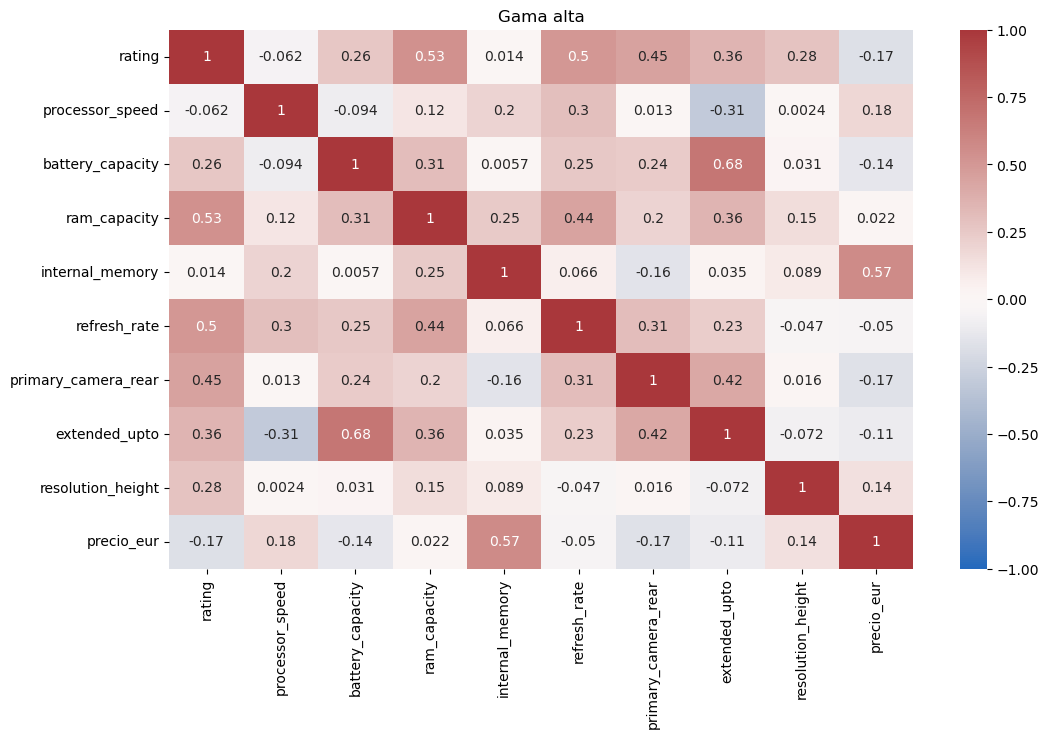

In [36]:
plt.figure(figsize=(12, 7))
sns.heatmap(m_corr_num_cols_a.loc[num_cols_slc, num_cols_slc], annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama alta')
plt.show()

### <a id='toc1_4_2_2_'></a>[4.2.2. Heatmaps de correlación de rating y precio con variables booleanas y categóricas](#toc0_)

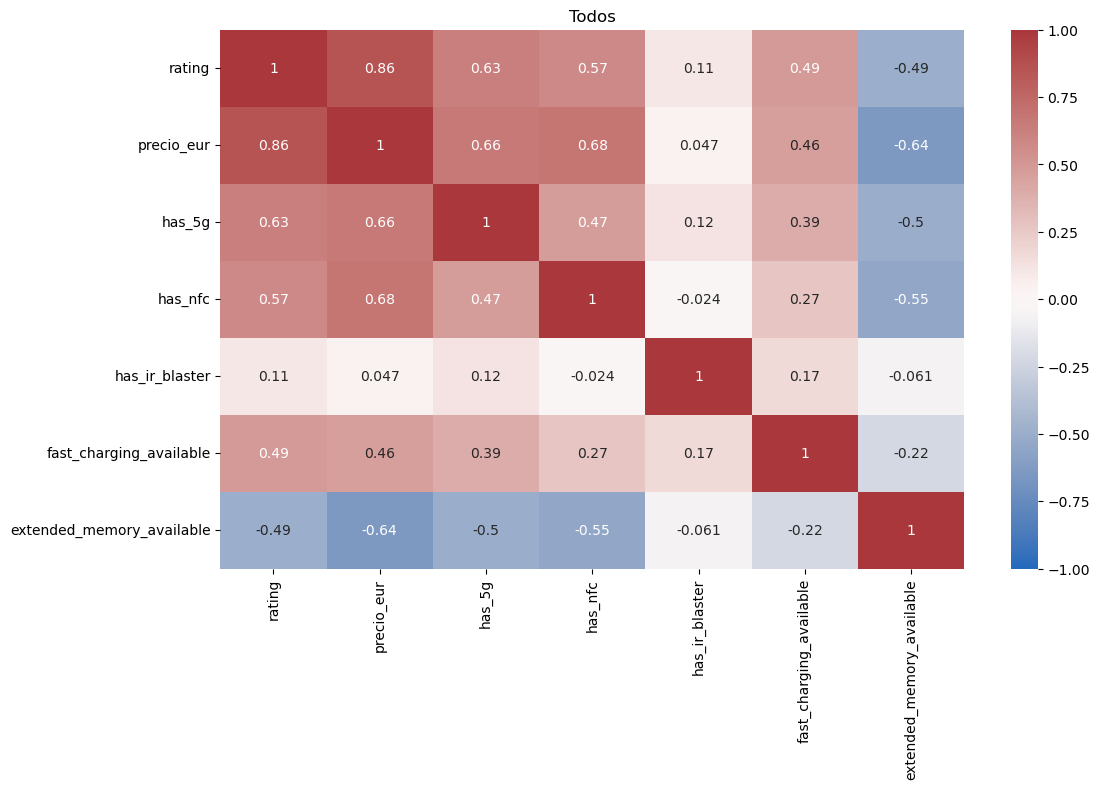

Valores de correlación de Spearman para rating de todos los móviles: 
rating                       1.000000
precio_eur                   0.856543
has_5g                       0.626638
has_nfc                      0.572998
fast_charging_available      0.485300
has_ir_blaster               0.108042
extended_memory_available   -0.494855
Name: rating, dtype: float64

Valores de correlación de Spearman para precio de todos los móviles: 
precio_eur                   1.000000
rating                       0.856543
has_nfc                      0.682164
has_5g                       0.659671
fast_charging_available      0.463673
has_ir_blaster               0.046596
extended_memory_available   -0.640907
Name: precio_eur, dtype: float64


In [37]:
m_corr_b_cols = df_f[['rating', 'precio_eur'] + bool_cols].corr(method='spearman')

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_b_cols, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Todos')
plt.show()
print('Valores de correlación de Spearman para rating de todos los móviles: ')
print(m_corr_b_cols['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Spearman para precio de todos los móviles: ')
print(m_corr_b_cols['precio_eur'].sort_values(ascending=False))

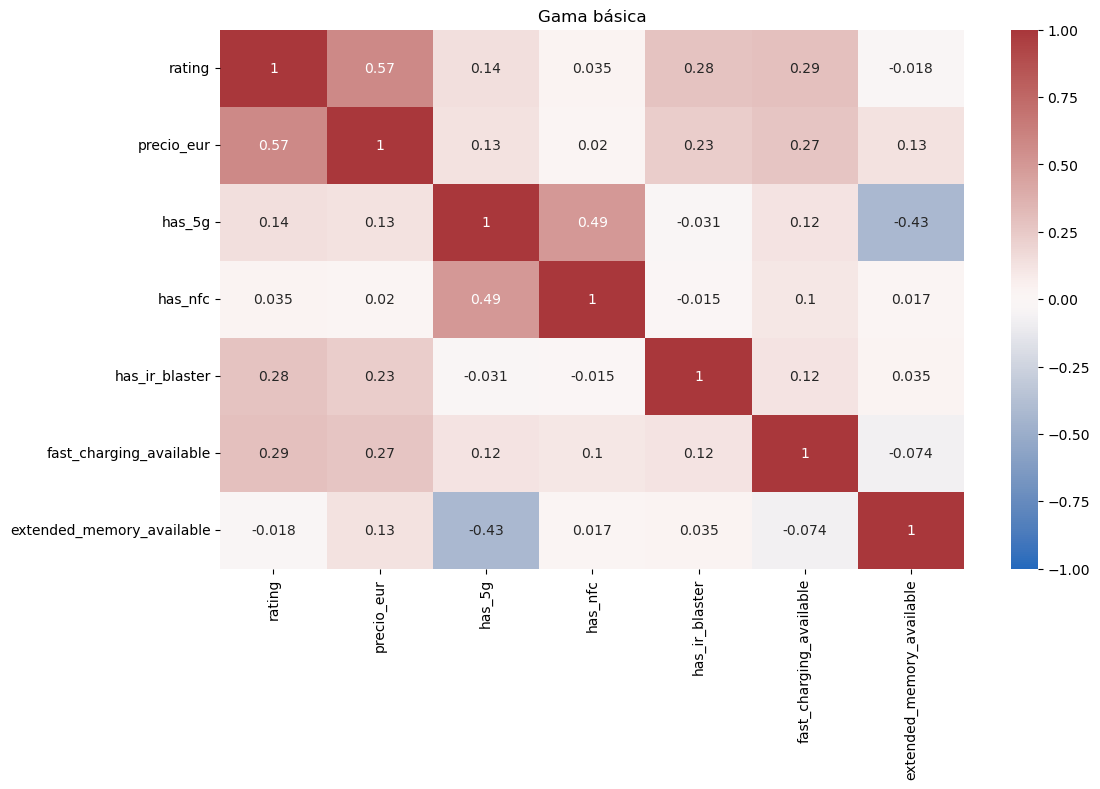

Valores de correlación de Spearman para rating de los móviles de gama básica: 
rating                       1.000000
precio_eur                   0.574291
fast_charging_available      0.290455
has_ir_blaster               0.278460
has_5g                       0.143119
has_nfc                      0.035279
extended_memory_available   -0.017878
Name: rating, dtype: float64

Valores de correlación de Spearman para precio de los móviles de gama básica: 
precio_eur                   1.000000
rating                       0.574291
fast_charging_available      0.271241
has_ir_blaster               0.232344
has_5g                       0.131274
extended_memory_available    0.127786
has_nfc                      0.019522
Name: precio_eur, dtype: float64


In [38]:
m_corr_b_cols_b = df_gbas[['rating', 'precio_eur'] + bool_cols].corr(method='spearman')

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_b_cols_b, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama básica')
plt.show()
print('Valores de correlación de Spearman para rating de los móviles de gama básica: ')
print(m_corr_b_cols_b['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Spearman para precio de los móviles de gama básica: ')
print(m_corr_b_cols_b['precio_eur'].sort_values(ascending=False))

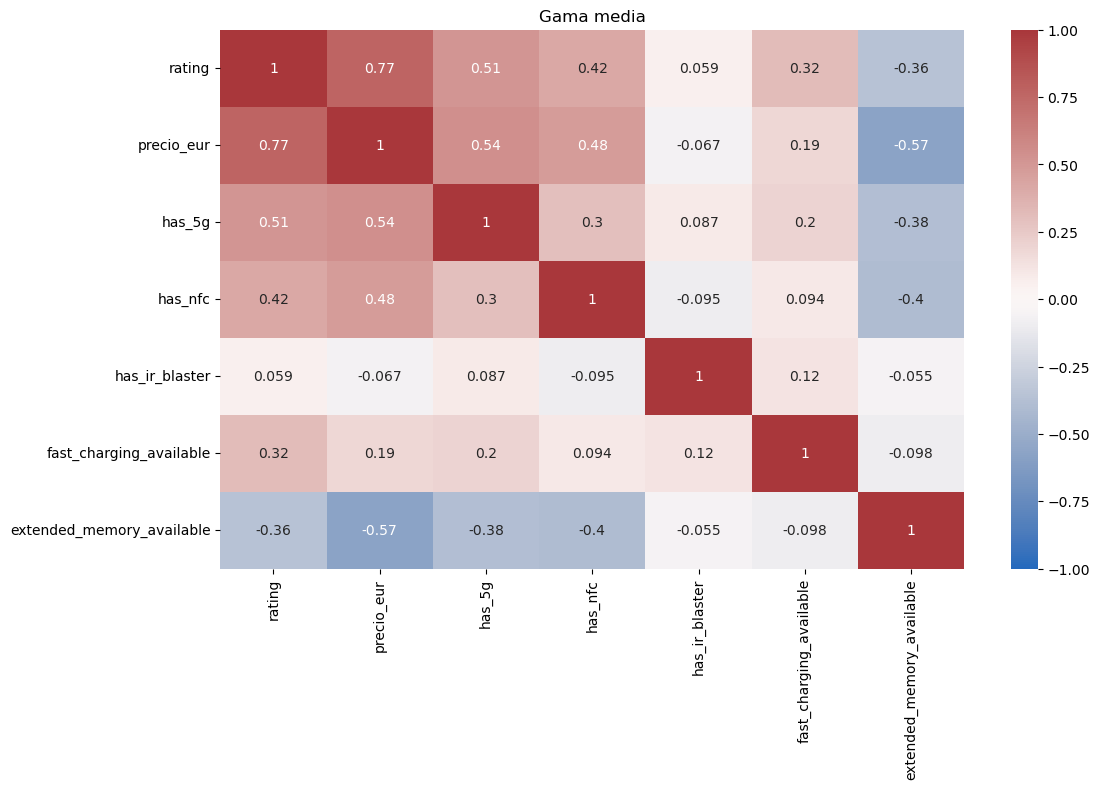

Valores de correlación de Spearman para rating de los móviles de gama media: 
rating                       1.000000
precio_eur                   0.772017
has_5g                       0.513713
has_nfc                      0.419857
fast_charging_available      0.319595
has_ir_blaster               0.058755
extended_memory_available   -0.362988
Name: rating, dtype: float64

Valores de correlación de Spearman para precio de los móviles de gama media: 
precio_eur                   1.000000
rating                       0.772017
has_5g                       0.544405
has_nfc                      0.479116
fast_charging_available      0.187092
has_ir_blaster              -0.067374
extended_memory_available   -0.571365
Name: precio_eur, dtype: float64


In [39]:
m_corr_b_cols_m = df_gmed[['rating', 'precio_eur'] + bool_cols].corr(method='spearman')

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_b_cols_m, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama media')
plt.show()
print('Valores de correlación de Spearman para rating de los móviles de gama media: ')
print(m_corr_b_cols_m['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Spearman para precio de los móviles de gama media: ')
print(m_corr_b_cols_m['precio_eur'].sort_values(ascending=False))

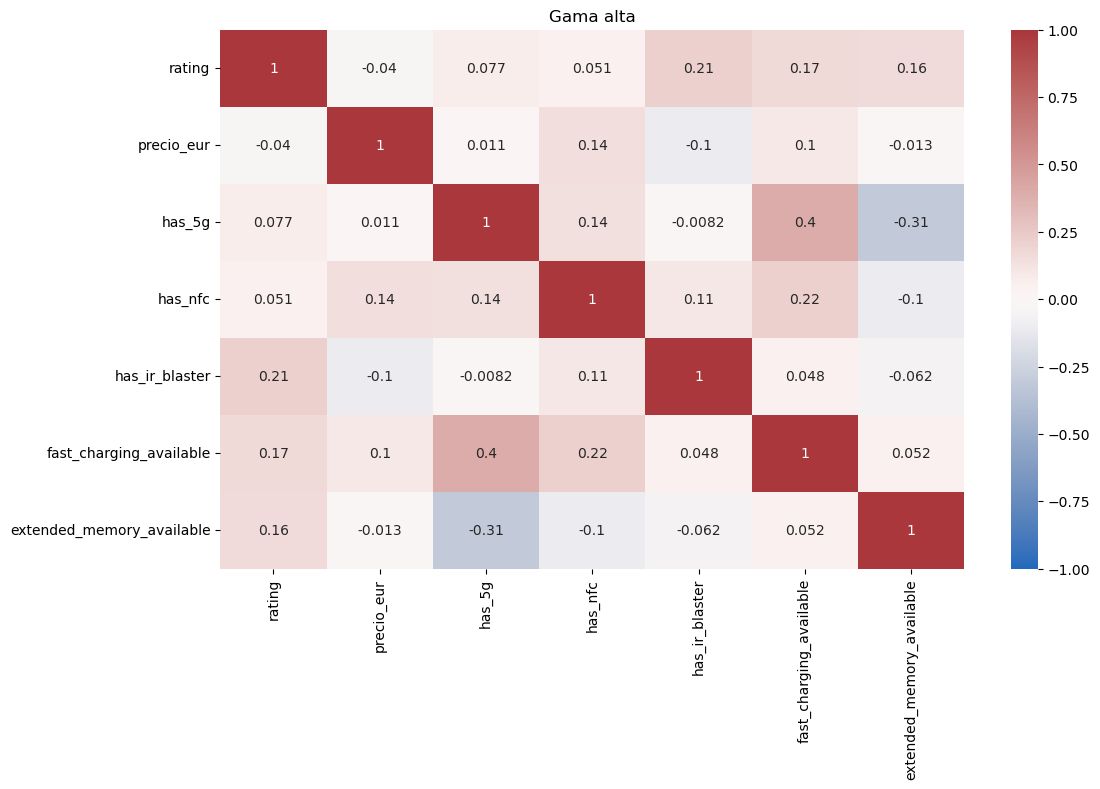

Valores de correlación de Spearman para rating de los móviles de gama alta: 
rating                       1.000000
has_ir_blaster               0.211356
fast_charging_available      0.169988
extended_memory_available    0.160746
has_5g                       0.076920
has_nfc                      0.050794
precio_eur                  -0.040485
Name: rating, dtype: float64

Valores de correlación de Spearman para precio de los móviles de gama alta: 
precio_eur                   1.000000
has_nfc                      0.143911
fast_charging_available      0.099886
has_5g                       0.010790
extended_memory_available   -0.013179
rating                      -0.040485
has_ir_blaster              -0.101756
Name: precio_eur, dtype: float64


In [40]:
m_corr_b_cols_a = df_galt[['rating', 'precio_eur'] + bool_cols].corr(method='spearman')

plt.figure(figsize=(12, 7))

sns.heatmap(m_corr_b_cols_a, annot = True, vmin = -1, vmax = 1, cmap='vlag')
plt.title('Gama alta')
plt.show()
print('Valores de correlación de Spearman para rating de los móviles de gama alta: ')
print(m_corr_b_cols_a['rating'].sort_values(ascending=False))
print()
print('Valores de correlación de Spearman para precio de los móviles de gama alta: ')
print(m_corr_b_cols_a['precio_eur'].sort_values(ascending=False))

### <a id='toc1_4_2_3_'></a>[4.2.3. Pairplots de variables numéricas](#toc0_)

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


<Figure size 1300x1700 with 0 Axes>

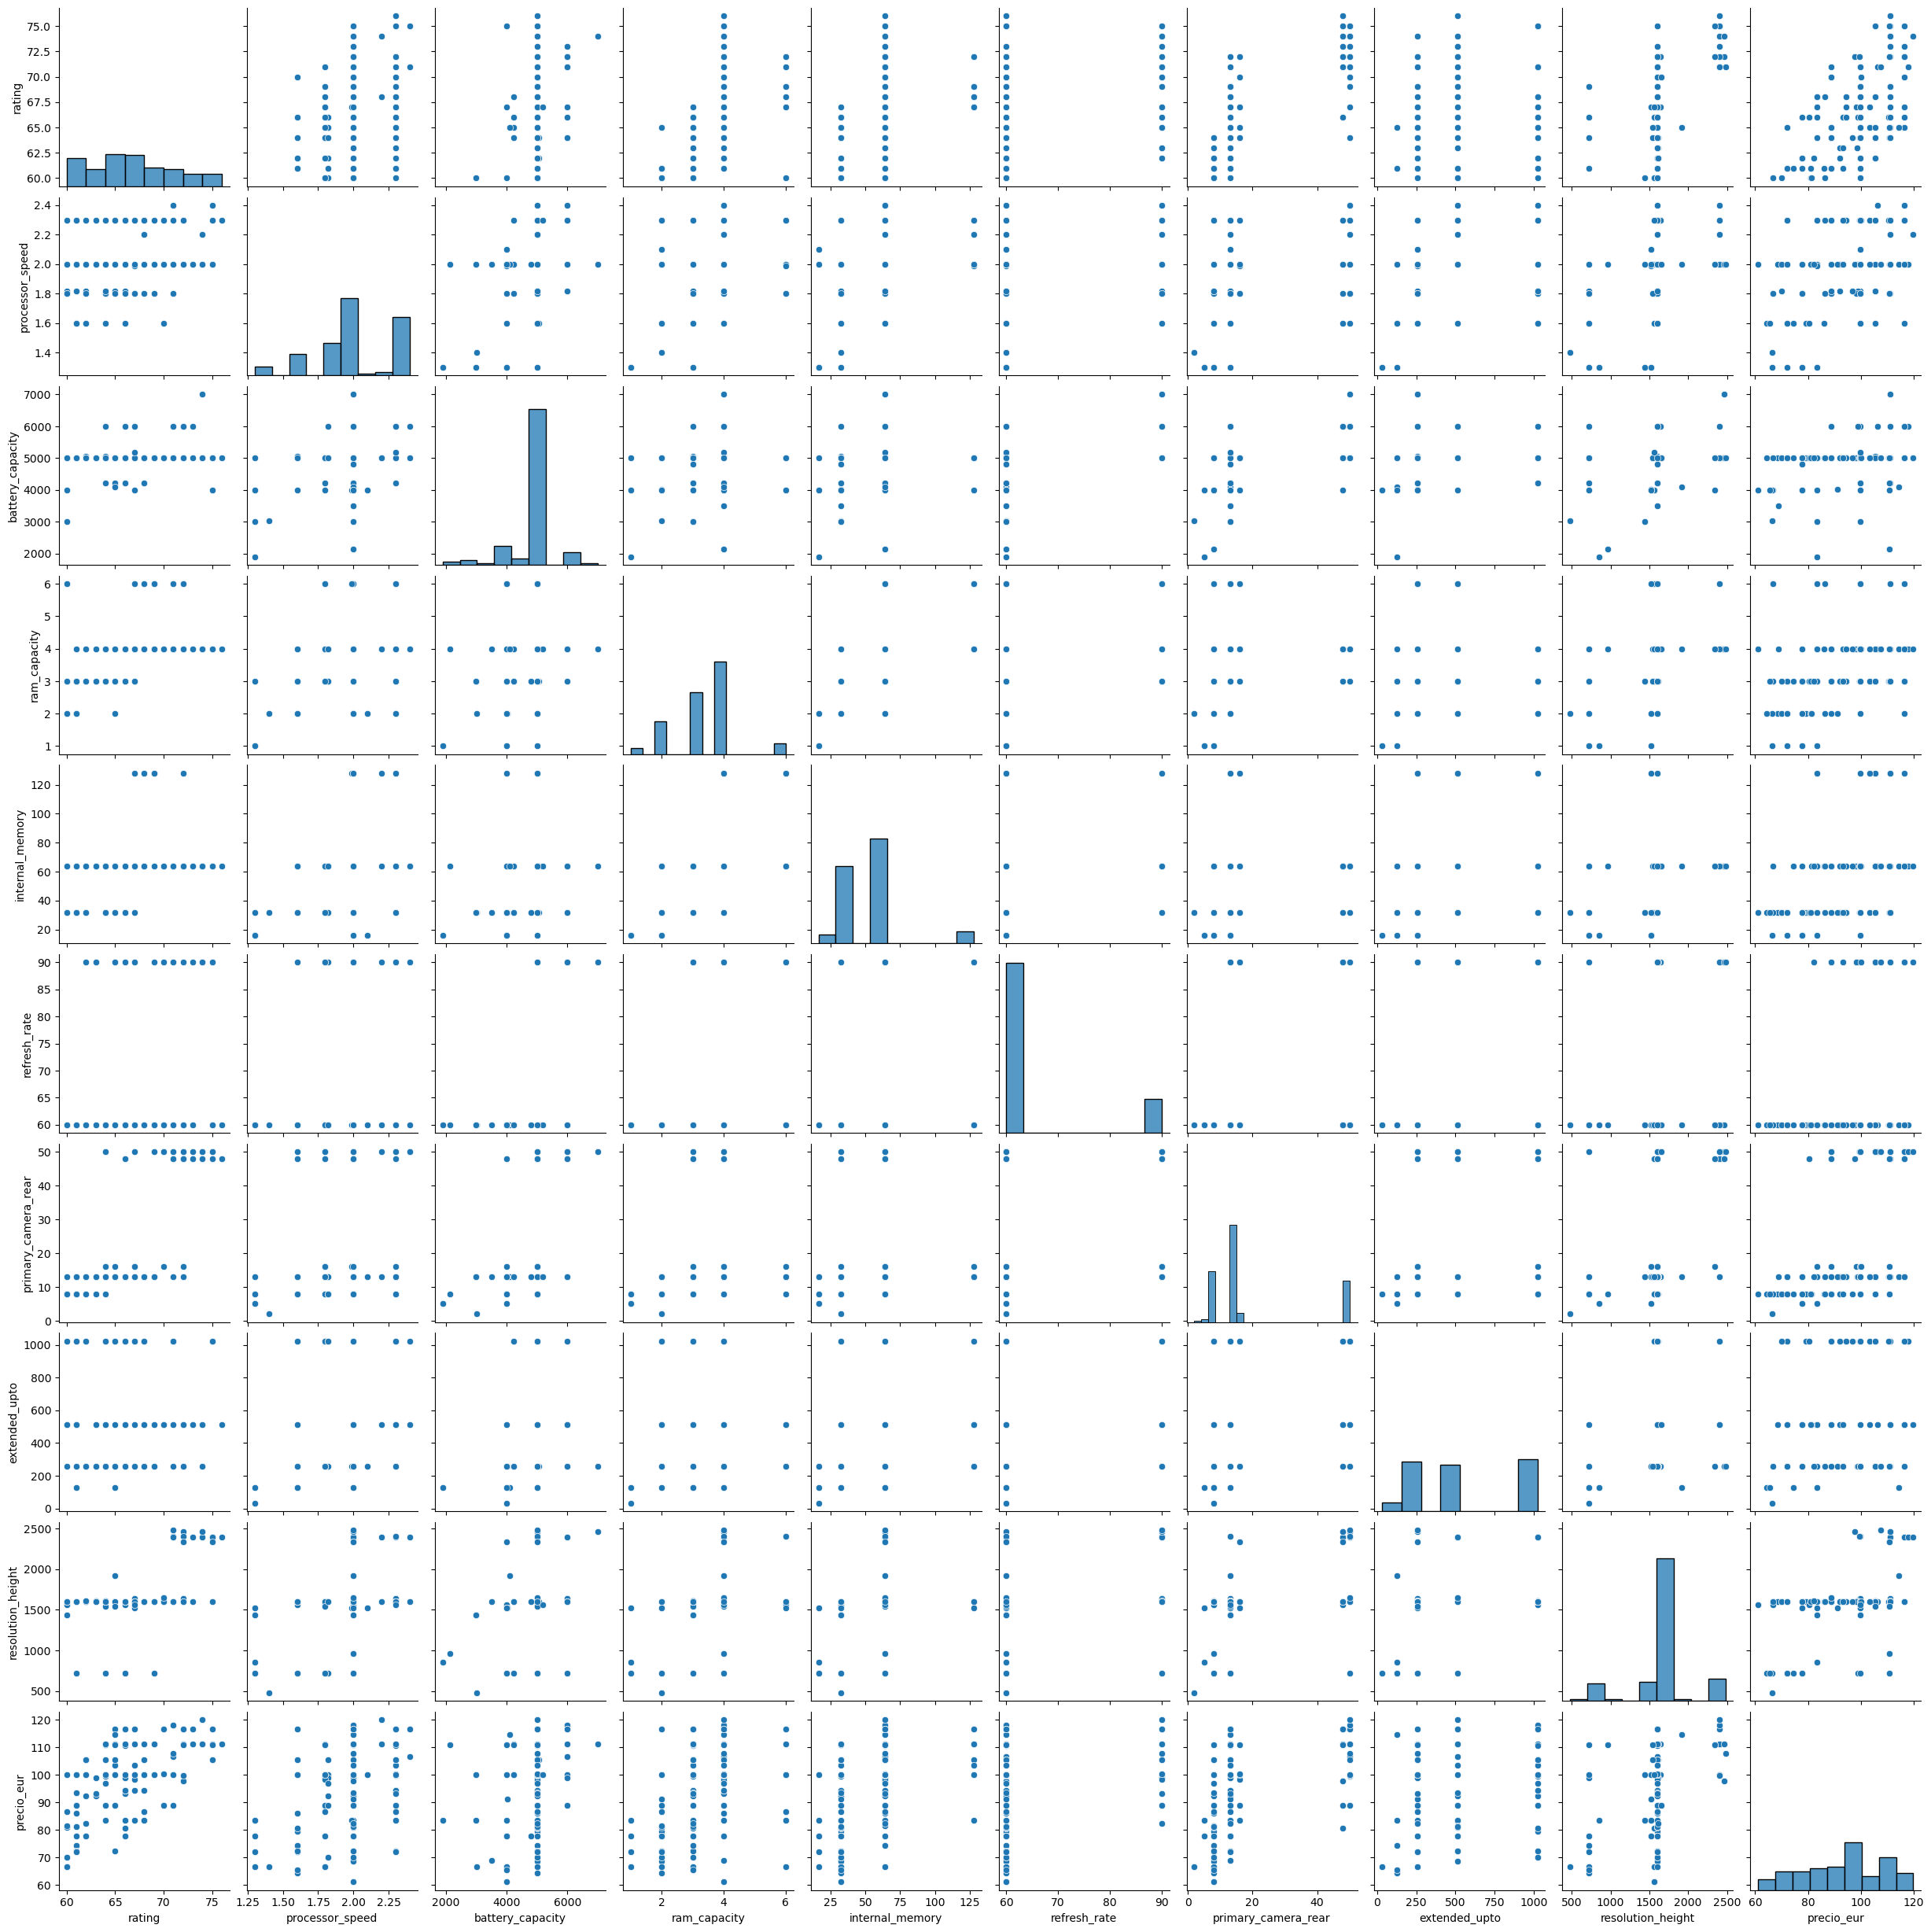

In [41]:
plt.figure(figsize=(13,17))
sns.pairplot(data=df_gbas[num_cols_slc]);
plt.show()

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


<Figure size 1300x1700 with 0 Axes>

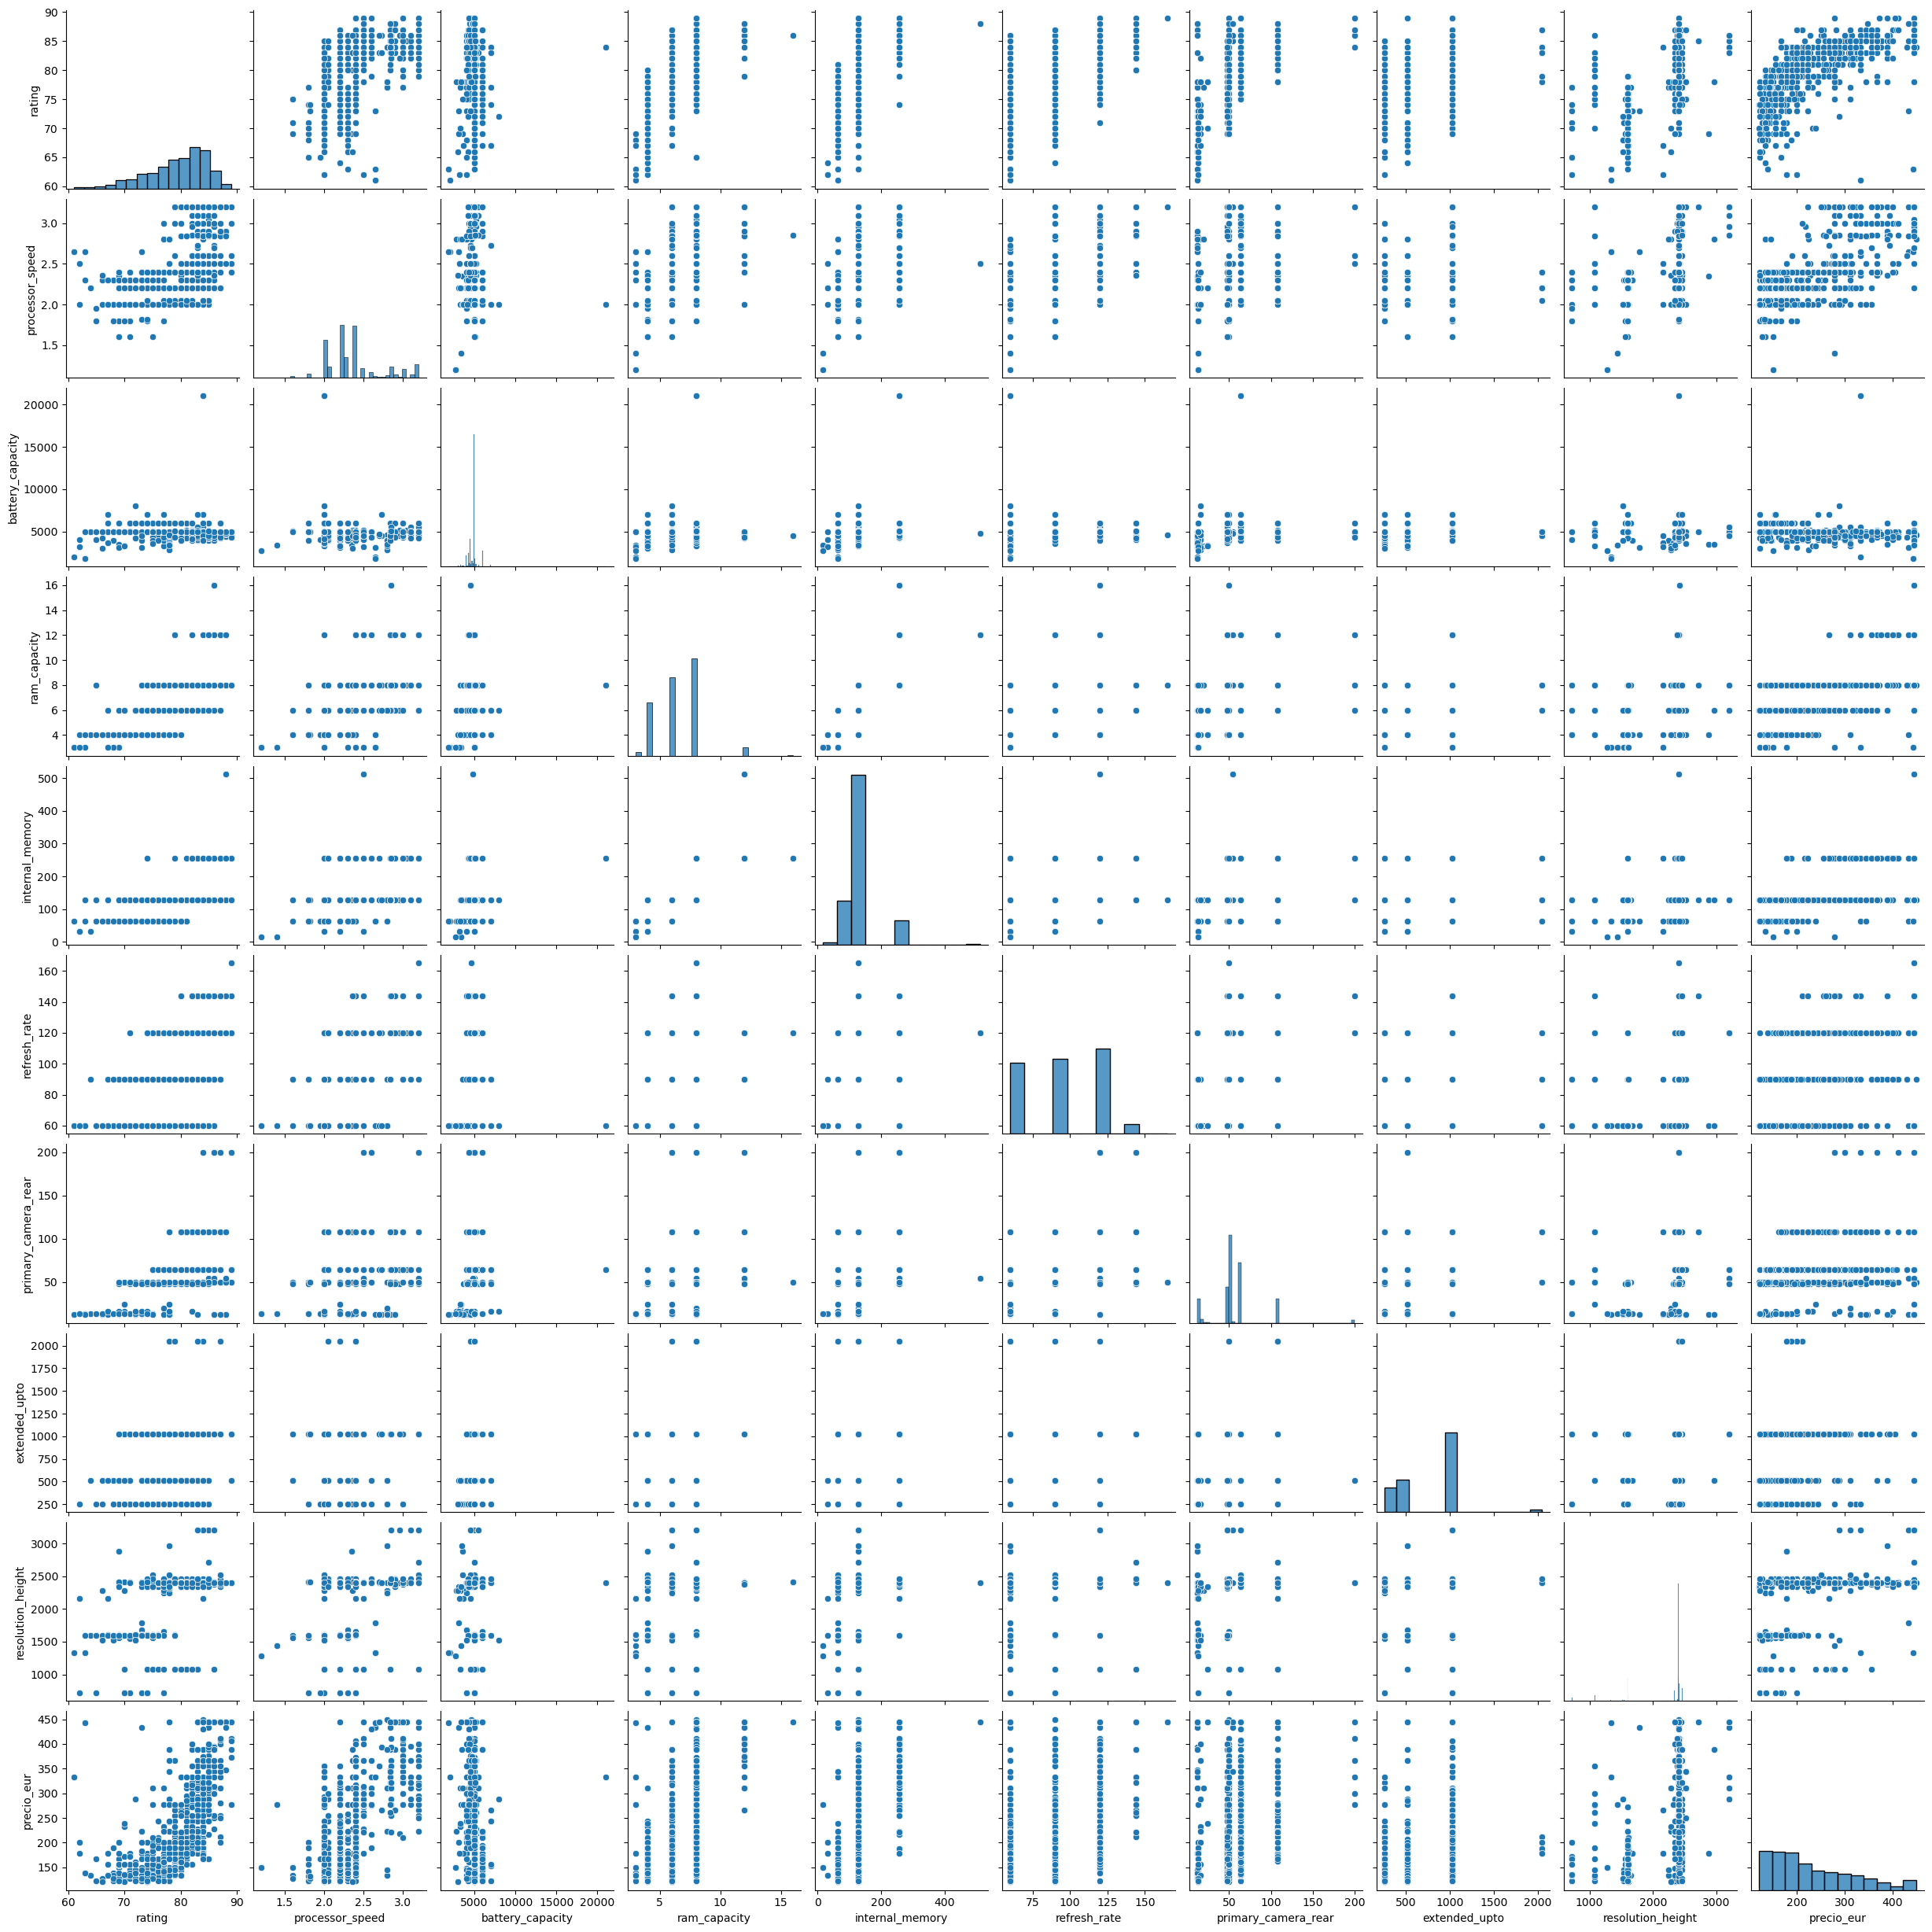

In [42]:
plt.figure(figsize=(13,17))
sns.pairplot(data=df_gmed[num_cols_slc]);
plt.show()

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


<Figure size 1300x1700 with 0 Axes>

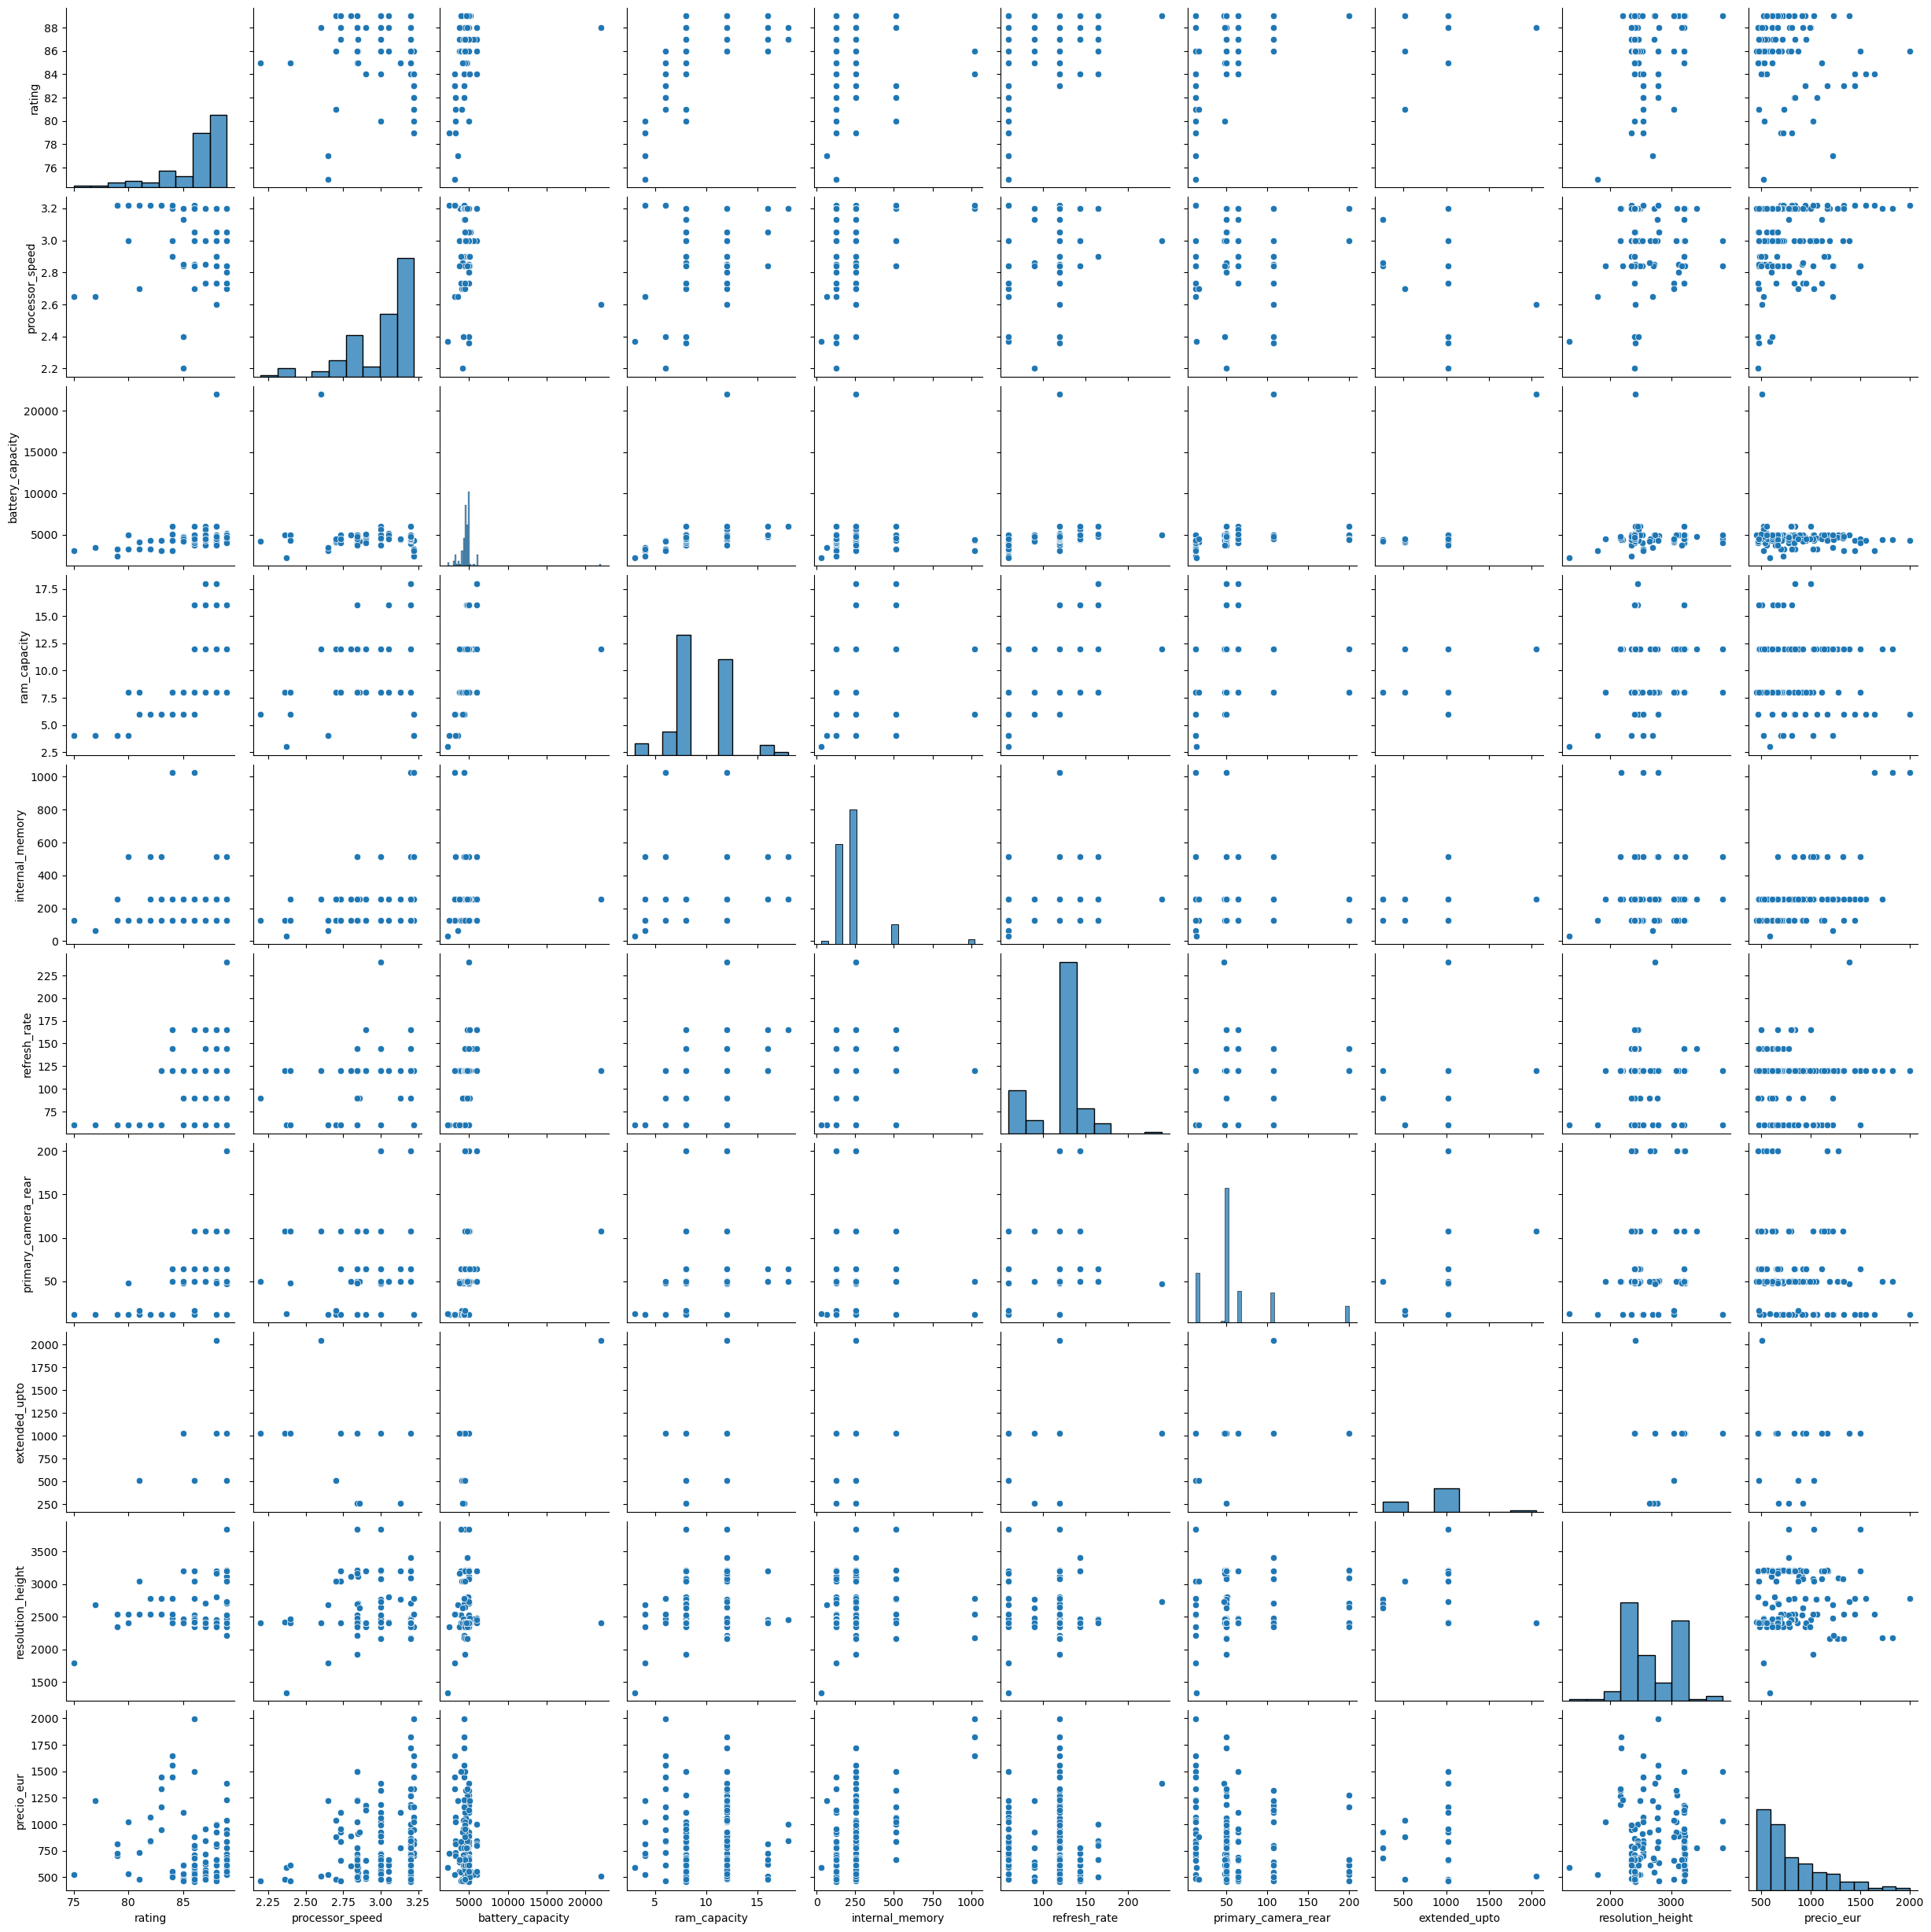

In [43]:
plt.figure(figsize=(13,17))
sns.pairplot(data=df_galt[num_cols_slc]);
plt.show()

### <a id='toc1_4_2_4_'></a>[4.2.4. ANOVAs con variables booleanas](#toc0_)

Con un $\alpha =0.05$ y $H_{0} -> \mu_{1} = \mu_{2}$:

- Si p-valor < 0.05 -> se rechaza $H_{0}$ y por tanto hay diferencias entre los grupos.

- Si p-valor >= 0.05 -> no se rechaza $H_{0}$.

In [44]:
bool_cols

['has_5g',
 'has_nfc',
 'has_ir_blaster',
 'fast_charging_available',
 'extended_memory_available']

In [45]:
print('Análisis para la gama de precios baja.')
for c in bool_cols:
    print(f"Precio medio con {c}=0: {df_gbas[df_gbas[c]==0]['precio_eur'].mean()}")
    print(f"Precio medio con {c}=1: {df_gbas[df_gbas[c]==1]['precio_eur'].mean()}")
    print(f'Influencia de {c} en el precio:')
    print(stats.f_oneway(df_gbas[df_gbas[c]==0]['precio_eur'], 
               df_gbas[df_gbas[c]==1]['precio_eur']))
    print()

Análisis para la gama de precios baja.
Precio medio con has_5g=0: 93.51362847222222
Precio medio con has_5g=1: 105.49444444444444
Influencia de has_5g en el precio:
F_onewayResult(statistic=2.395350731657648, pvalue=0.12412745553170149)

Precio medio con has_nfc=0: 93.83078880407125
Precio medio con has_nfc=1: 99.88888888888889
Influencia de has_nfc en el precio:
F_onewayResult(statistic=0.15404779462075394, pvalue=0.6953395449239759)

Precio medio con has_ir_blaster=0: 93.26979166666666
Precio medio con has_ir_blaster=1: 113.29722222222222
Influencia de has_ir_blaster en el precio:
F_onewayResult(statistic=6.922263423888243, pvalue=0.009541896956607792)

Precio medio con fast_charging_available=0: 90.32352092352092
Precio medio con fast_charging_available=1: 98.85111111111108
Influencia de fast_charging_available en el precio:
F_onewayResult(statistic=10.664597985222647, pvalue=0.001396345208944879)

Precio medio con extended_memory_available=0: 82.1711111111111
Precio medio con exten

En la gama de precios baja, se puede afirmar que correlan con el precio las variables booleanas has_ir_blaster y fast_charging_available, siendo más caros los móviles con las variables igual a True. 

In [46]:
print('Análisis para la gama de precios media.')
for c in bool_cols:
    print(f"Precio medio con {c}=0: {df_gmed[df_gmed[c]==0]['precio_eur'].mean()}")
    print(f"Precio medio con {c}=1: {df_gmed[df_gmed[c]==1]['precio_eur'].mean()}")
    print(f'Influencia de {c} en el precio:')
    print(stats.f_oneway(df_gmed[df_gmed[c]==0]['precio_eur'], 
               df_gmed[df_gmed[c]==1]['precio_eur']))
    print()

Análisis para la gama de precios media.
Precio medio con has_5g=0: 182.72064119455422
Precio medio con has_5g=1: 270.8382572076449
Influencia de has_5g en el precio:
F_onewayResult(statistic=199.59859468960911, pvalue=2.789673317021168e-39)

Precio medio con has_nfc=0: 204.31642156862748
Precio medio con has_nfc=1: 296.62098108747045
Influencia de has_nfc en el precio:
F_onewayResult(statistic=191.6506314798407, pvalue=5.628816529022479e-38)

Precio medio con has_ir_blaster=0: 236.28165484633573
Precio medio con has_ir_blaster=1: 222.805291005291
Influencia de has_ir_blaster en el precio:
F_onewayResult(statistic=2.3942183393871286, pvalue=0.12231719825135252)

Precio medio con fast_charging_available=0: 176.18888888888887
Precio medio con fast_charging_available=1: 236.5734316617502
Influencia de fast_charging_available en el precio:
F_onewayResult(statistic=14.505841498627698, pvalue=0.00015425714898404652)

Precio medio con extended_memory_available=0: 316.1245751633987
Precio medio

En la gama de precios media, se puede afirmar que correlan con el precio las variables booleanas has_5g, has_nfc, fast_charging_available y extended_memory_available. Tienden a ser más caros los móviles con las variables has_5g, has_nfc y fast_charging_available igual a True y con la variable extended_memory_available igual a False. 

La correlación negativa de la disponibilidad de extensión de memoria con el precio puede deberse a que los móviles con precios más altos prescinden de esa capacidad por tener de inicio mayor capacidad de almacenamiento. 

In [47]:
print('Análisis para la gama de precios alta.')
for c in bool_cols:
    print(f"Precio medio con {c}=0: {df_galt[df_galt[c]==0]['precio_eur'].mean()}")
    print(f"Precio medio con {c}=1: {df_galt[df_galt[c]==1]['precio_eur'].mean()}")
    print(f'Influencia de {c} en el precio:')
    print(stats.f_oneway(df_galt[df_galt[c]==0]['precio_eur'], 
               df_galt[df_galt[c]==1]['precio_eur']))
    print()

Análisis para la gama de precios alta.
Precio medio con has_5g=0: 785.9851851851851
Precio medio con has_5g=1: 800.0064564564565
Influencia de has_5g en el precio:
F_onewayResult(statistic=0.022141929645028303, pvalue=0.881899902477923)

Precio medio con has_nfc=0: 664.1530864197531
Precio medio con has_nfc=1: 806.9894039735099
Influencia de has_nfc en el precio:
F_onewayResult(statistic=1.7778416431188677, pvalue=0.18433375928829826)

Precio medio con has_ir_blaster=0: 815.9859259259259
Precio medio con has_ir_blaster=1: 706.9871111111111
Influencia de has_ir_blaster en el precio:
F_onewayResult(statistic=2.5840415338714804, pvalue=0.1099422545001725)

Precio medio con fast_charging_available=0: 555.4944444444445
Precio medio con fast_charging_available=1: 802.0366385372715
Influencia de fast_charging_available en el precio:
F_onewayResult(statistic=1.2273460514974797, pvalue=0.26960743810752763)

Precio medio con extended_memory_available=0: 801.6739057239057
Precio medio con extende

En la gama de precios alta no se observa una correlación significativa entre ninguna de estas variables booleanas y el precio. 

### <a id='toc1_4_2_5_'></a>[4.2.5. ANOVAs y test de Tukey entre distintas marcas](#toc0_)

In [48]:
# Conteo de móviles por marcas antes y después del filtrado del dataset
conteo_marcas_i = df['brand_name'].value_counts().sort_values(ascending=False)
conteo_marcas_i

brand_name
xiaomi       134
samsung      132
vivo         111
realme        97
oppo          88
motorola      52
apple         46
oneplus       42
poco          41
tecno         33
iqoo          32
infinix       29
huawei        16
google        14
nokia         13
honor         13
itel          10
sony           9
asus           7
nubia          6
nothing        5
lava           4
jio            4
redmi          3
ikall          3
letv           3
gionee         3
lg             3
micromax       3
oukitel        3
royole         2
doogee         2
zte            2
lenovo         2
lyf            2
leeco          1
cola           1
tesla          1
vertu          1
blu            1
tcl            1
duoqin         1
leitz          1
cat            1
sharp          1
blackview      1
Name: count, dtype: int64

In [49]:
conteo_marcas_f = df_gbma['brand_name'].value_counts().sort_values(ascending=False)
conteo_marcas_f

brand_name
xiaomi       132
samsung      112
vivo         107
realme        95
oppo          84
motorola      52
oneplus       41
poco          40
tecno         32
iqoo          31
infinix       29
apple         22
honor         13
huawei        11
nokia         11
google        10
sony           9
itel           6
asus           6
nubia          6
nothing        5
lava           4
gionee         3
micromax       3
redmi          3
jio            2
doogee         2
lenovo         2
oukitel        2
letv           2
zte            2
leitz          1
sharp          1
tcl            1
duoqin         1
lg             1
leeco          1
blu            1
cola           1
blackview      1
Name: count, dtype: int64

In [50]:
conteo_marcas = pd.concat(objs=[conteo_marcas_i, conteo_marcas_f], axis=1, keys=['count_i', 'count_f'])
conteo_marcas = conteo_marcas.fillna(0)
conteo_marcas

,count_i,count_f
brand_name,,
xiaomi,134,132.0
samsung,132,112.0
vivo,111,107.0
realme,97,95.0
oppo,88,84.0
motorola,52,52.0
apple,46,22.0
oneplus,42,41.0
poco,41,40.0


In [51]:
dif_conteo_marcas = conteo_marcas['count_i'] - conteo_marcas['count_f']
dif_conteo_marcas.sort_values(ascending=False)

brand_name
apple        24.0
samsung      20.0
huawei        5.0
itel          4.0
vivo          4.0
oppo          4.0
google        4.0
ikall         3.0
royole        2.0
lg            2.0
jio           2.0
nokia         2.0
xiaomi        2.0
lyf           2.0
realme        2.0
tecno         1.0
oukitel       1.0
tesla         1.0
letv          1.0
oneplus       1.0
iqoo          1.0
cat           1.0
vertu         1.0
asus          1.0
poco          1.0
blu           0.0
tcl           0.0
duoqin        0.0
sharp         0.0
cola          0.0
lenovo        0.0
leitz         0.0
leeco         0.0
redmi         0.0
zte           0.0
doogee        0.0
micromax      0.0
gionee        0.0
lava          0.0
nothing       0.0
nubia         0.0
sony          0.0
honor         0.0
infinix       0.0
motorola      0.0
blackview     0.0
dtype: float64

In [52]:
dif_conteo_marcas / conteo_marcas_i

brand_name
xiaomi       0.014925
samsung      0.151515
vivo         0.036036
realme       0.020619
oppo         0.045455
motorola     0.000000
apple        0.521739
oneplus      0.023810
poco         0.024390
tecno        0.030303
iqoo         0.031250
infinix      0.000000
huawei       0.312500
google       0.285714
nokia        0.153846
honor        0.000000
itel         0.400000
sony         0.000000
asus         0.142857
nubia        0.000000
nothing      0.000000
lava         0.000000
jio          0.500000
redmi        0.000000
ikall        1.000000
letv         0.333333
gionee       0.000000
lg           0.666667
micromax     0.000000
oukitel      0.333333
royole       1.000000
doogee       0.000000
zte          0.000000
lenovo       0.000000
lyf          1.000000
leeco        0.000000
cola         0.000000
tesla        1.000000
vertu        1.000000
blu          0.000000
tcl          0.000000
duoqin       0.000000
leitz        0.000000
cat          1.000000
sharp        0.000000

Es notable la cantidad de móviles eliminados de la marca Apple en el filtrado inicial del dataset (más de la mitad, 52%). 

>Nota: aquí se ha dejado el cálculo tras el filtrado inicial y tras descartar las gamas de precios más extremas. Se comprueba que la mayoría de registros se descartan en el filtrado inicial tanto para Apple como para Samsung. 

In [53]:
# Precios por marca de móvil, descartando gamas de precios más extremas
precios_med_x_marca = df_gbma.groupby('brand_name')['precio_eur'].median().sort_values(ascending=False)
precios_med_x_marca

brand_name
leitz        1388.777778
apple         894.433333
asus          805.544444
sony          777.666667
sharp         666.555556
lg            611.100000
lenovo        594.383333
nubia         538.777778
zte           455.494444
google        424.888889
doogee        338.877778
huawei        333.222222
oneplus       333.222222
nothing       313.877778
iqoo          311.100000
oukitel       310.494444
honor         277.666667
samsung       249.933333
vivo          222.111111
oppo          222.111111
motorola      219.383333
redmi         211.100000
nokia         199.888889
xiaomi        193.655556
cola          166.655556
poco          166.655556
realme        166.655556
blu           166.555556
infinix       144.433333
tecno         130.544444
leeco         122.211111
lava          111.100000
duoqin        111.000000
jio           108.272222
blackview      99.888889
tcl            99.888889
micromax       77.766667
gionee         77.766667
itel           66.555556
letv          

In [54]:
# Precios por marca de móvil, en las 20 marcas de móviles más frecuentes del dataset filtrado 
precios_med_x_marca_top20 = df_gbma[df_gbma['brand_name'].isin(df_gbma['brand_name'].value_counts().index[:20])].groupby('brand_name')['precio_eur'].median().sort_values(ascending=False)
precios_med_x_marca_top20


brand_name
apple       894.433333
asus        805.544444
sony        777.666667
nubia       538.777778
google      424.888889
huawei      333.222222
oneplus     333.222222
iqoo        311.100000
honor       277.666667
samsung     249.933333
oppo        222.111111
vivo        222.111111
motorola    219.383333
nokia       199.888889
xiaomi      193.655556
poco        166.655556
realme      166.655556
infinix     144.433333
tecno       130.544444
itel         66.555556
Name: precio_eur, dtype: float64

In [55]:
precios_x_marca_top20 = df_gbma[df_gbma['brand_name'].isin(df_gbma['brand_name'].value_counts().index[:20])].groupby('brand_name')['precio_eur'].mean().sort_values(ascending=False)
precios_x_marca_top20

brand_name
apple       990.943939
asus        768.474074
sony        673.007407
nubia       553.642593
huawei      478.653535
google      478.541111
samsung     414.525000
oneplus     398.661518
iqoo        340.383513
honor       336.687179
vivo        298.636241
oppo        298.048016
nokia       282.779798
motorola    267.776923
xiaomi      258.148064
poco        204.902222
realme      197.071345
tecno       164.495833
infinix     162.942146
itel         68.229630
Name: precio_eur, dtype: float64

ANOVAs entre algunas parejas de marcas:

In [56]:
# Apple - Samsung
print(f"Precio medio de Apple: {df_gbma[df_gbma['brand_name']=='apple']['precio_eur'].mean()}")
print(f"Precio medio de Samsung: {df_gbma[df_gbma['brand_name']=='samsung']['precio_eur'].mean()}")
print(f'ANOVA Apple - Samsung:')
print(stats.f_oneway(df_gbma[df_gbma['brand_name']=='apple']['precio_eur'], 
            df_gbma[df_gbma['brand_name']=='samsung']['precio_eur']))

Precio medio de Apple: 990.9439393939396
Precio medio de Samsung: 414.52500000000003
ANOVA Apple - Samsung:
F_onewayResult(statistic=40.948136895911595, pvalue=2.5073252216496265e-09)


In [57]:
# Samsung - Xiaomi
print(f"Precio medio de Samsung: {df_gbma[df_gbma['brand_name']=='samsung']['precio_eur'].mean()}")
print(f"Precio medio de Xiaomi: {df_gbma[df_gbma['brand_name']=='xiaomi']['precio_eur'].mean()}")
print(f'ANOVA Samsung - Xiaomi:')
print(stats.f_oneway(df_gbma[df_gbma['brand_name']=='samsung']['precio_eur'], 
            df_gbma[df_gbma['brand_name']=='xiaomi']['precio_eur']))

Precio medio de Samsung: 414.52500000000003
Precio medio de Xiaomi: 258.148063973064
ANOVA Samsung - Xiaomi:
F_onewayResult(statistic=17.351711554595283, pvalue=4.3242571588417856e-05)


In [58]:
# Xiaomi - Realme
print(f"Precio medio de Xiaomi: {df_gbma[df_gbma['brand_name']=='xiaomi']['precio_eur'].mean()}")
print(f"Precio medio de Realme: {df_gbma[df_gbma['brand_name']=='realme']['precio_eur'].mean()}")
print(f'ANOVA Xiaomi - Realme:')
print(stats.f_oneway(df_gbma[df_gbma['brand_name']=='xiaomi']['precio_eur'], 
            df_gbma[df_gbma['brand_name']=='realme']['precio_eur']))

Precio medio de Xiaomi: 258.148063973064
Precio medio de Realme: 197.07134502923984
ANOVA Xiaomi - Realme:
F_onewayResult(statistic=7.715639399313689, pvalue=0.00593641048962033)


In [59]:
# Realme - Tecno
print(f"Precio medio de Realme: {df_gbma[df_gbma['brand_name']=='realme']['precio_eur'].mean()}")
print(f"Precio medio de Tecno: {df_gbma[df_gbma['brand_name']=='tecno']['precio_eur'].mean()}")
print(f'ANOVA Realme - Tecno:')
print(stats.f_oneway(df_gbma[df_gbma['brand_name']=='realme']['precio_eur'], 
            df_gbma[df_gbma['brand_name']=='tecno']['precio_eur']))

Precio medio de Realme: 197.07134502923984
Precio medio de Tecno: 164.49583333333334
ANOVA Realme - Tecno:
F_onewayResult(statistic=2.475595743739776, pvalue=0.11815335588392954)


Estos ANOVAs indican que hay diferencias significativas de precios entre los conjuntos de móviles incluidos en el dataset de las marcas Apple, Samsung, Xiaomi y Realme. 

Esto no significa que haya influencia del factor marca en los precios, ya que las características técnicas de los distintos conjuntos comparados también podrían ser significativamente diferentes. Ver apartado [5.2](#toc1_5_2_). 

Se puede decir lo mismo del test de Tukey siguiente, salvo que no se confirma diferencia significativa de precios entre las marcas Xiaomi y Realme. 

In [60]:
# Test de Tukey para los móviles de las marcas Apple, Samsung, Xiaomi y Realme
lst_marcas_Tukey = ['apple', 'samsung', 'xiaomi', 'realme']
df_gbma_tukey = df_gbma[df_gbma['brand_name'].isin(lst_marcas_Tukey)]

x = df_gbma_tukey['brand_name']
y = df_gbma_tukey['precio_eur']

mc = multi.MultiComparison(y,x)
rst = mc.tukeyhsd()
print("Influencia de la marca en el precio")
print(rst)

Influencia de la marca en el precio
    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1  group2  meandiff p-adj    lower     upper   reject
-----------------------------------------------------------
  apple  realme -793.8726    0.0 -957.7448 -630.0004   True
  apple samsung -576.4189    0.0 -737.9357 -414.9022   True
  apple  xiaomi -732.7959    0.0  -892.291 -573.3007   True
 realme samsung  217.4537    0.0  120.8486  314.0587   True
 realme  xiaomi   61.0767 0.3295   -32.109  154.2625  False
samsung  xiaomi -156.3769    0.0 -245.3553  -67.3986   True
-----------------------------------------------------------


## <a id='toc1_5_'></a>[5. Contraste de hipótesis](#toc0_)

### <a id='toc1_5_1_'></a>[5.1. Hipótesis 1](#toc0_)

Hipótesis 1: Algunas características técnicas de los teléfonos influyen notablemente en su precio.

En el apartado [4](#toc1_4_) se ha observado correlación entre muchas de las características técnicas incluidas en el dataset y el precio de los móviles. A continuación se grafican los precios medios en función de algunas de las características técnicas para las marcas de móviles seleccionadas en el apartado [4.2.5](#toc1_4_2_5_). 

In [61]:
cols_slc = ['has_5g', 
            'has_nfc', 
            'processor_speed', 
            # 'battery_capacity', 
            'ram_capacity', 
            'internal_memory', 
            'screen_size', 
            'refresh_rate', 
            'num_rear_cameras', 
            'primary_camera_rear', 
            'resolution_width']
num_y_bool_cols

['rating',
 'has_5g',
 'has_nfc',
 'has_ir_blaster',
 'num_cores',
 'processor_speed',
 'battery_capacity',
 'fast_charging_available',
 'fast_charging',
 'ram_capacity',
 'internal_memory',
 'screen_size',
 'refresh_rate',
 'num_rear_cameras',
 'num_front_cameras',
 'primary_camera_rear',
 'primary_camera_front',
 'extended_memory_available',
 'extended_upto',
 'resolution_width',
 'resolution_height',
 'precio_eur']

In [62]:
# df_gbma_tukey.groupby(['brand_name', 'ram_capacity'])[['ram_capacity', 'precio_eur']].mean()

has_5g


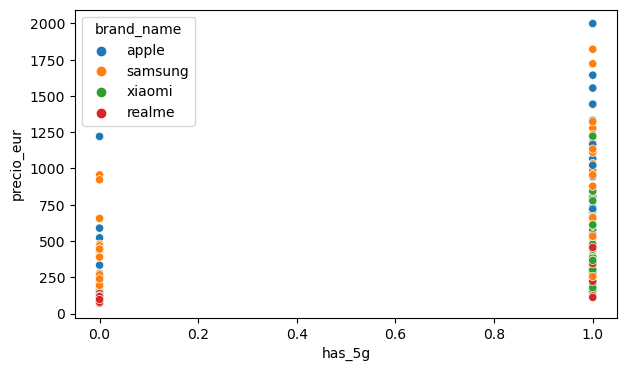

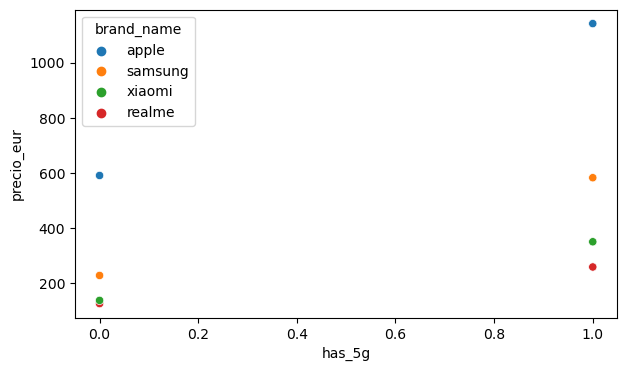

has_nfc


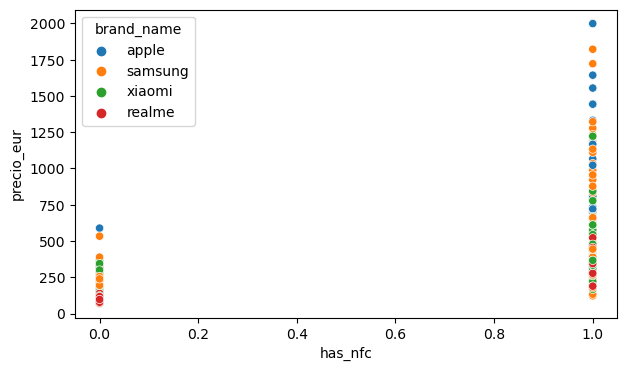

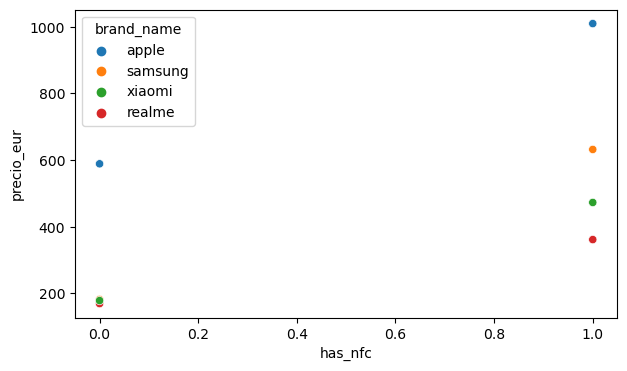

processor_speed


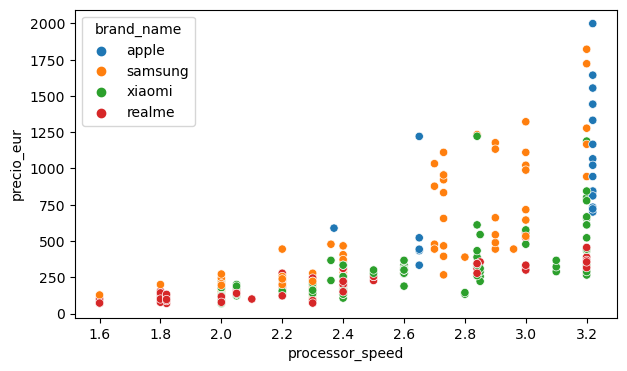

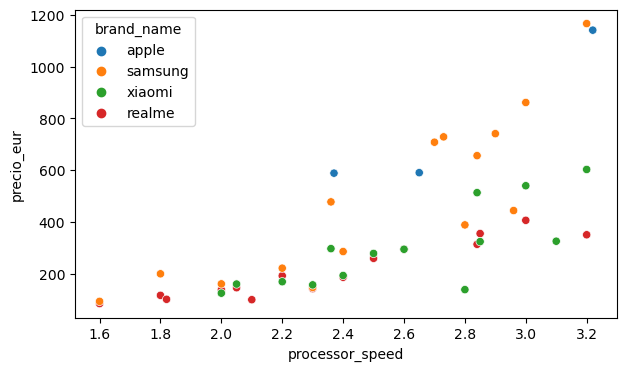

ram_capacity


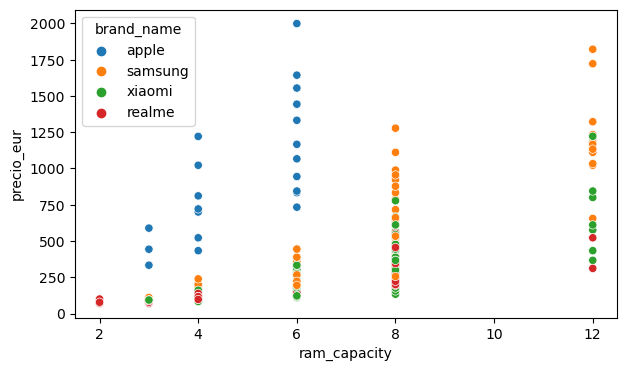

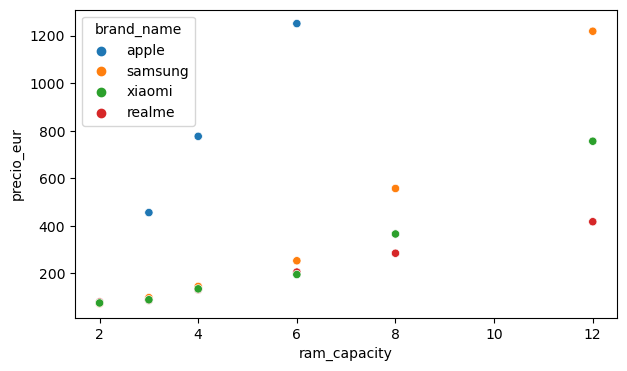

internal_memory


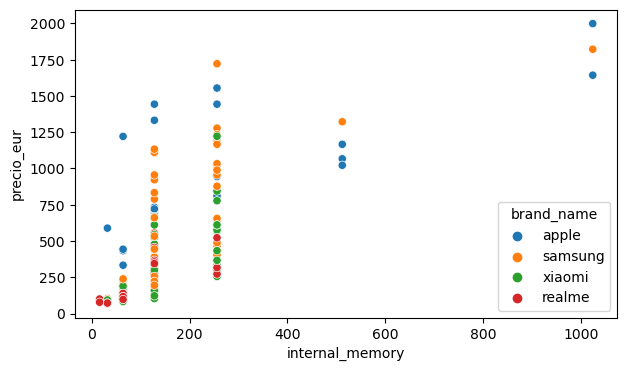

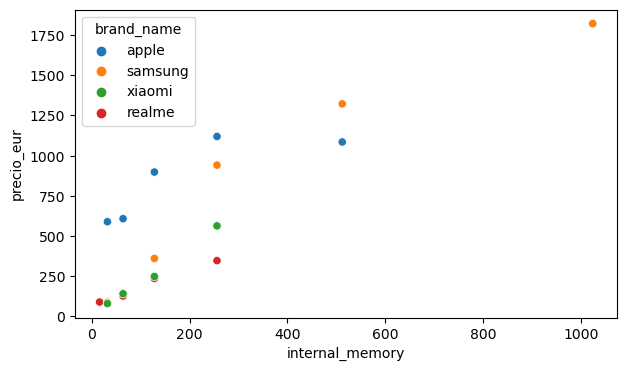

screen_size


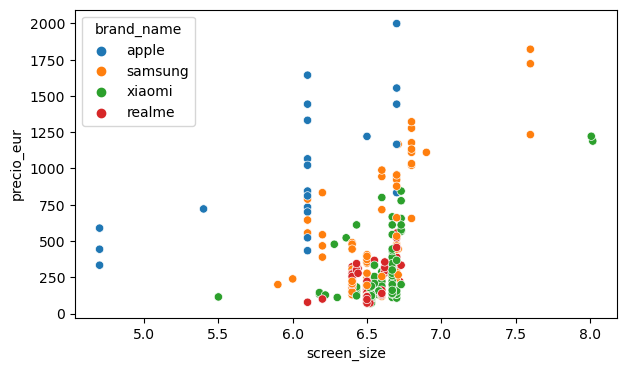

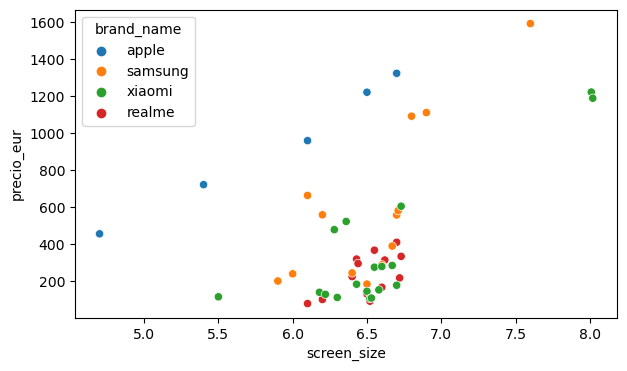

refresh_rate


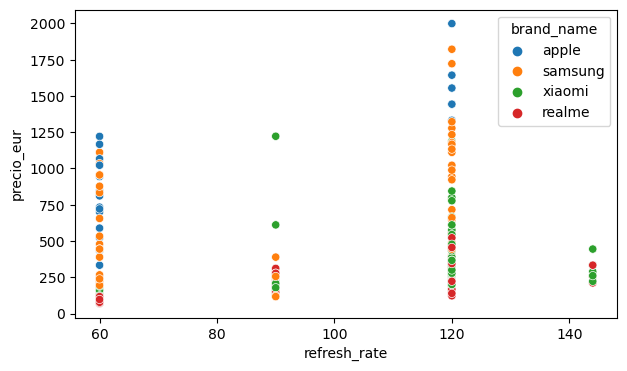

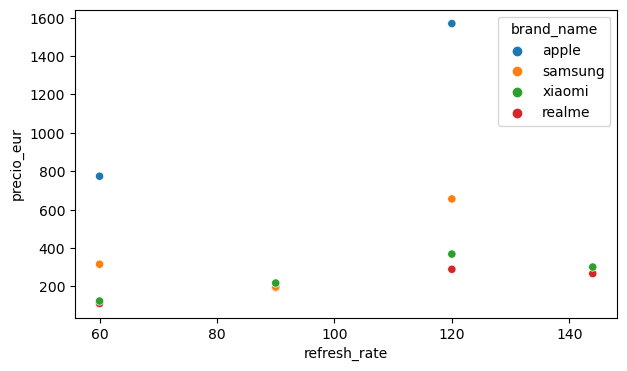

num_rear_cameras


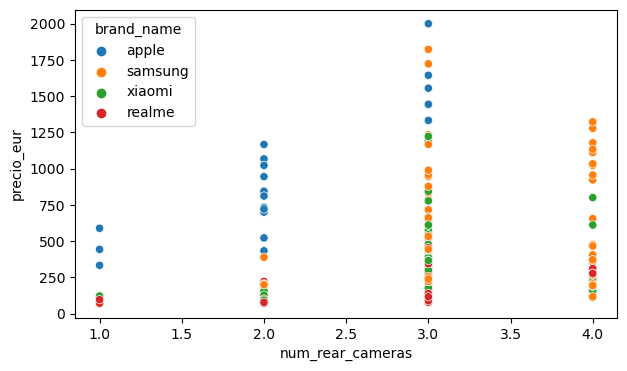

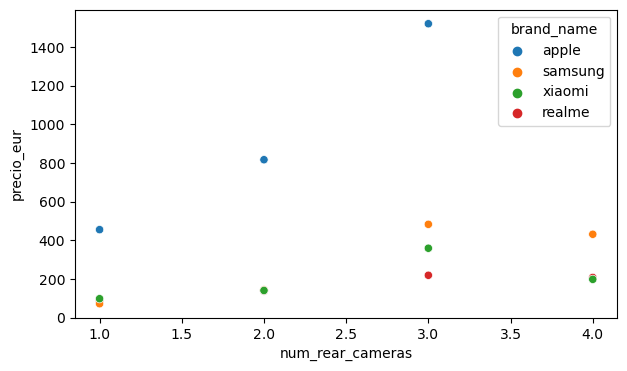

primary_camera_rear


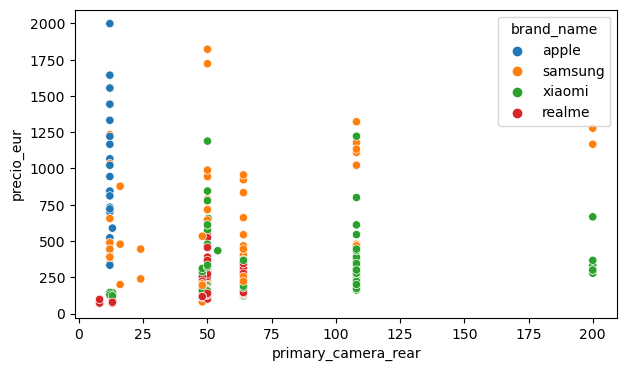

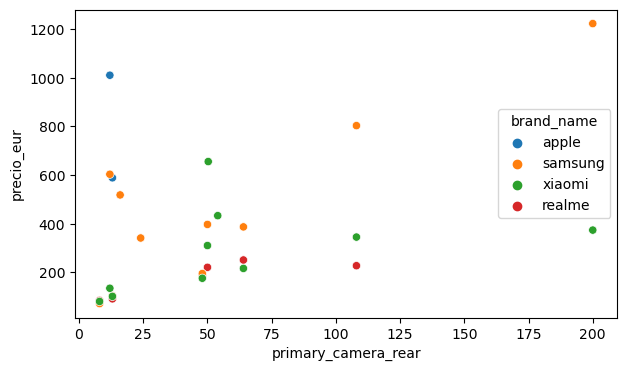

resolution_width


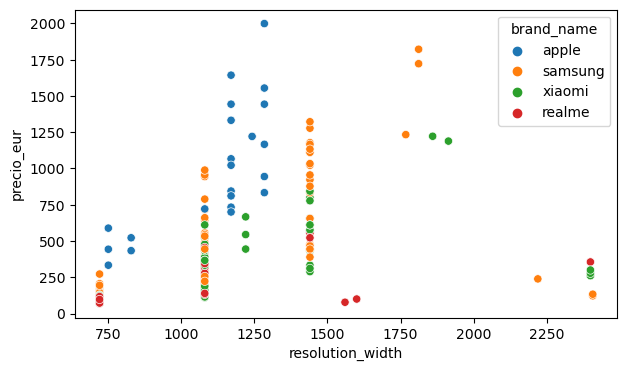

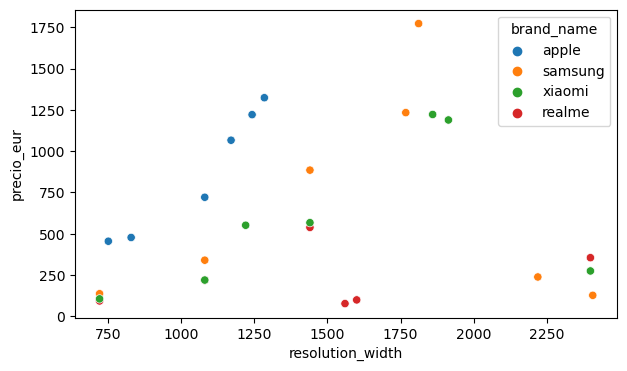

In [63]:
for col in cols_slc:
    print(col)
    plt.figure(figsize = (7, 4))
    sns.scatterplot(data=df_gbma_tukey, x=col, y='precio_eur', hue='brand_name', hue_order=lst_marcas_Tukey);
    plt.figure(figsize = (7, 4))
    df_gbma_tukey_gr = df_gbma_tukey.groupby(['brand_name', col])[[col, 'precio_eur']].mean()
    sns.scatterplot(data=df_gbma_tukey_gr, x=col, y='precio_eur', hue='brand_name', hue_order=lst_marcas_Tukey);
    plt.show()

Se considera confirmada la hipótesis 1. Estas son algunas de las características técnicas en las que se observa una correlación más clara con el precio (lista no limitativa): 
- has_5g
- has_nfc
- processor_speed
- ram_capacity
- internal_memory
- num_rear_cameras

A continuación se muestran gráficas similares a las anteriores para el rating. 

has_5g


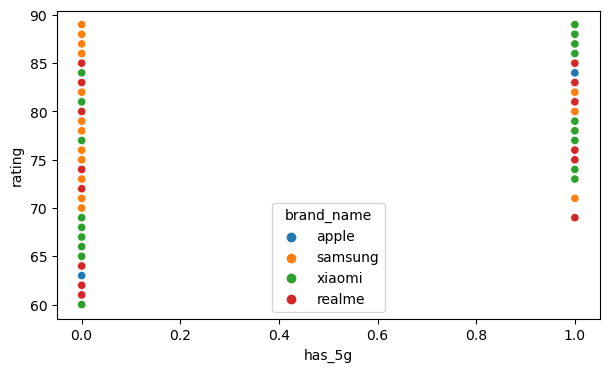

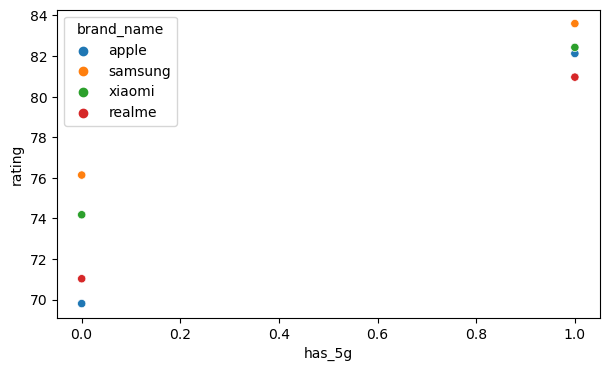

has_nfc


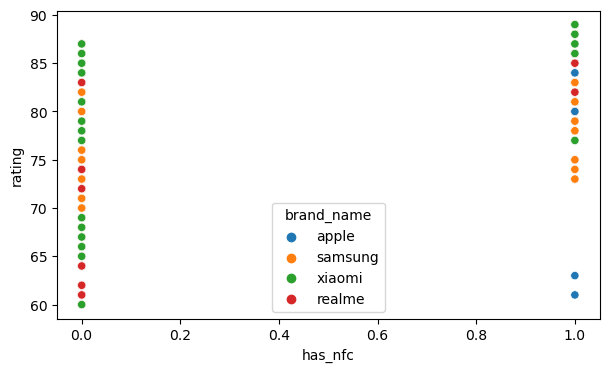

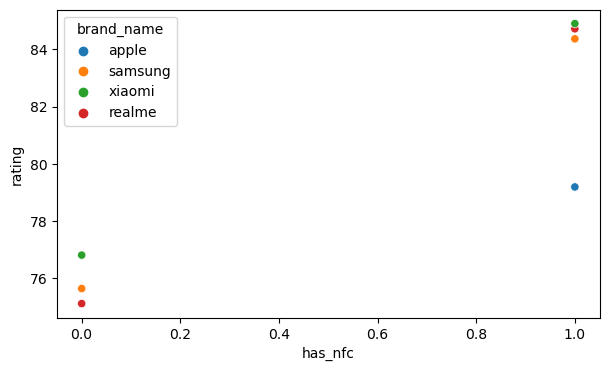

processor_speed


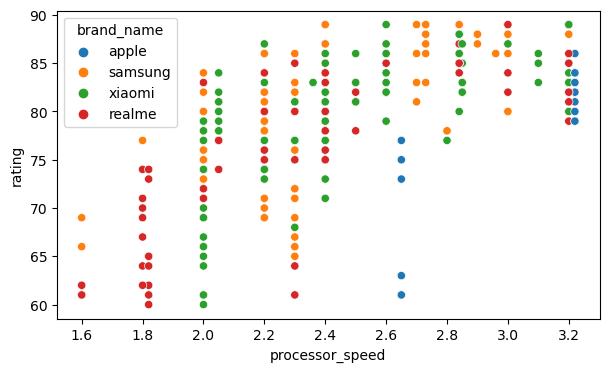

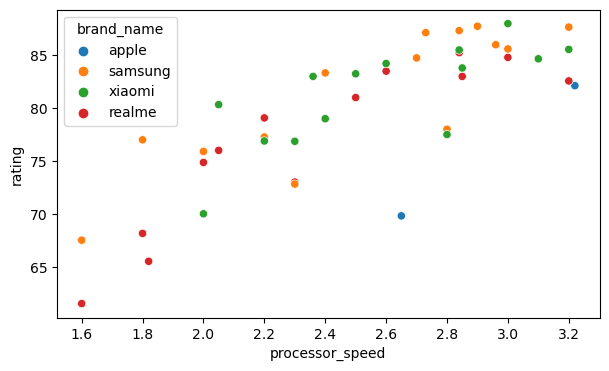

ram_capacity


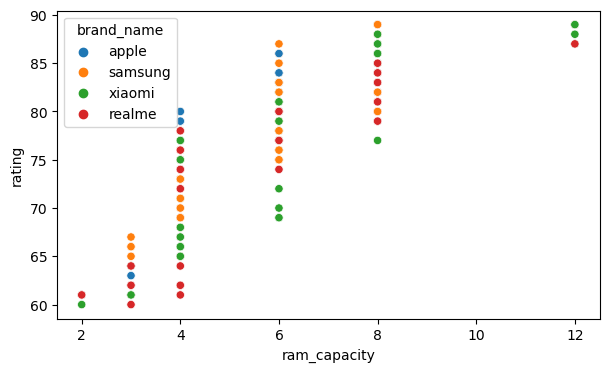

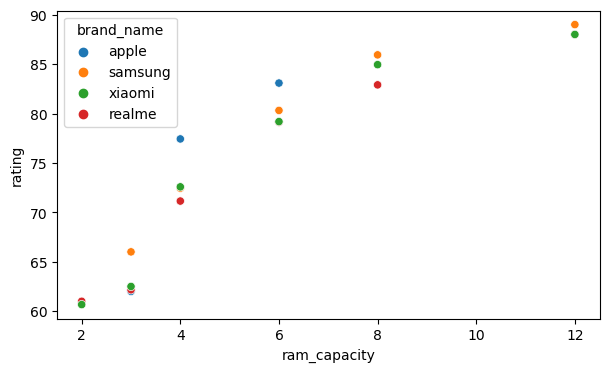

internal_memory


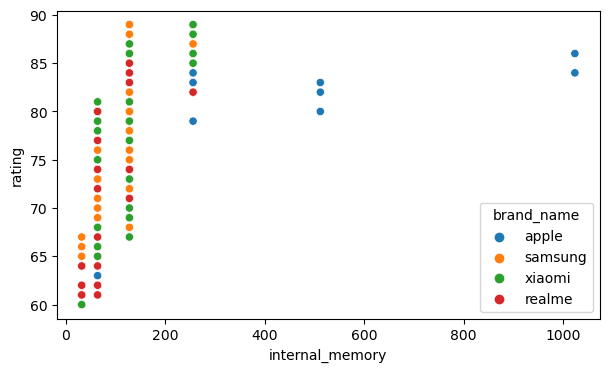

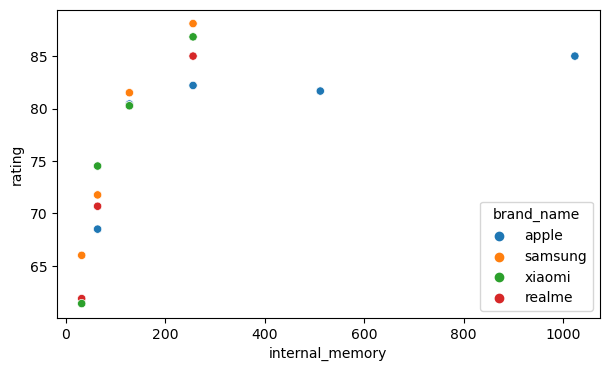

screen_size


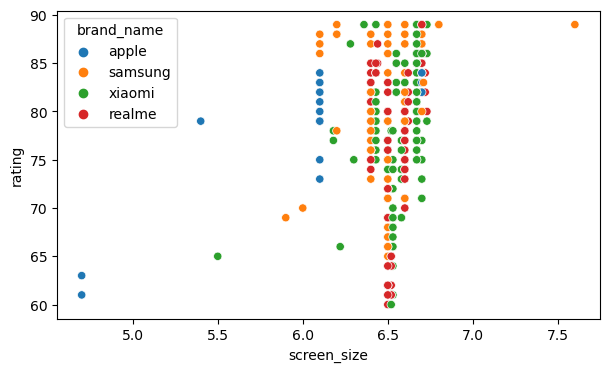

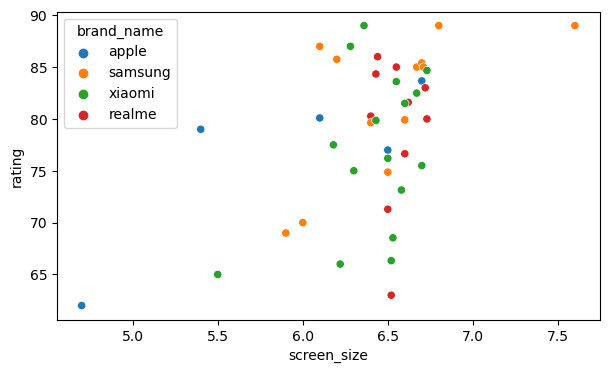

refresh_rate


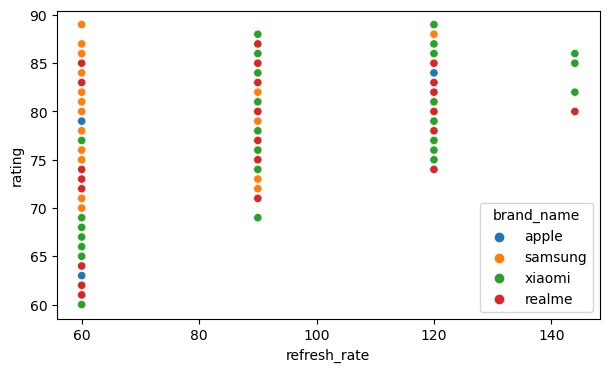

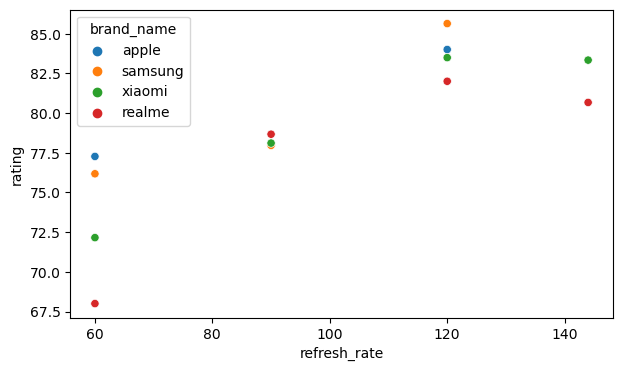

num_rear_cameras


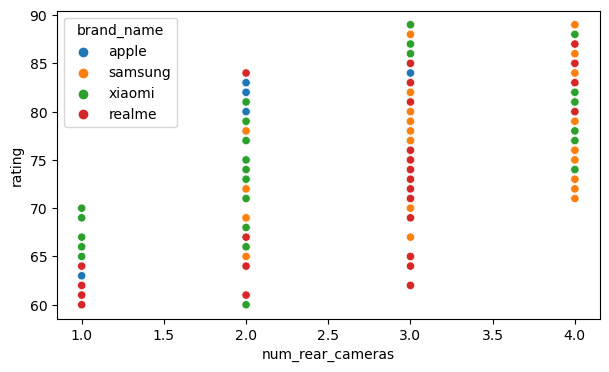

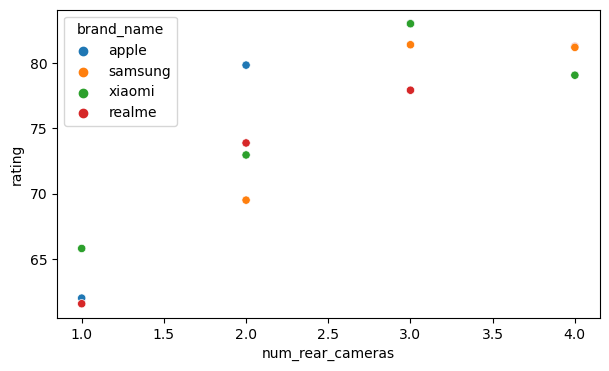

primary_camera_rear


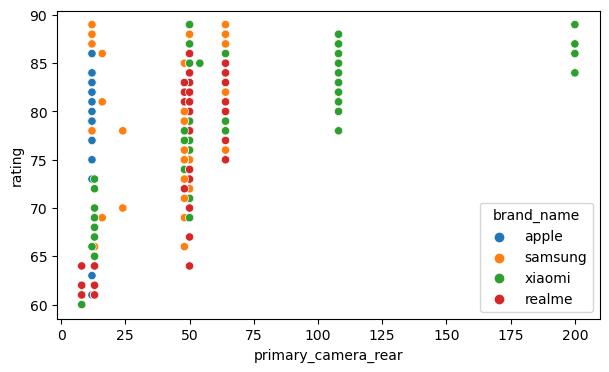

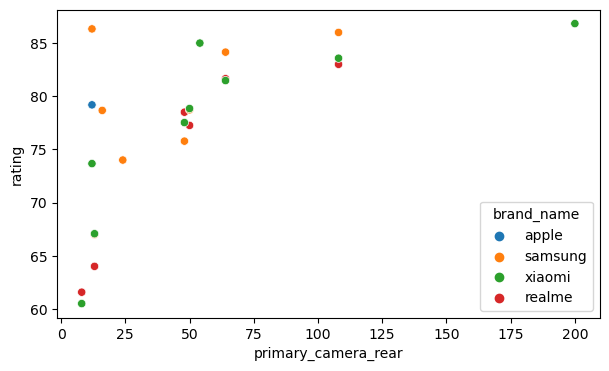

resolution_width


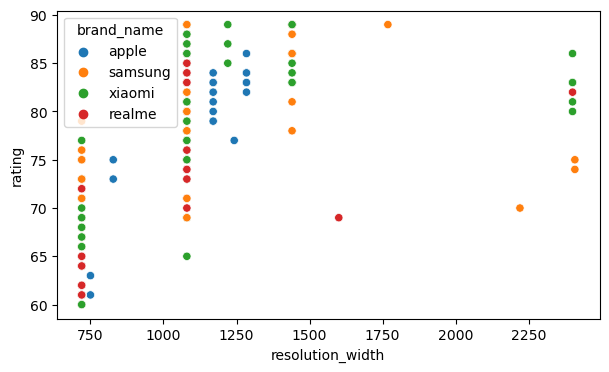

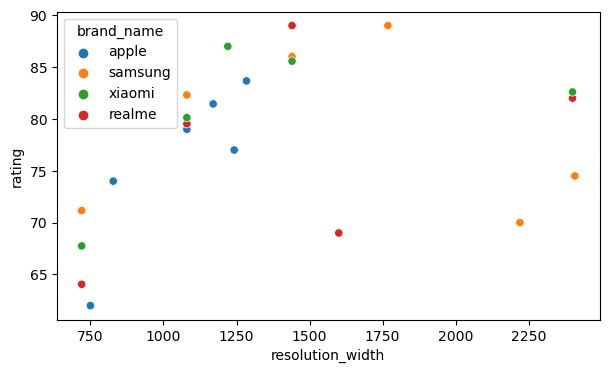

In [64]:
for col in cols_slc:
    print(col)
    plt.figure(figsize = (7, 4))
    sns.scatterplot(data=df_gbma_tukey, x=col, y='rating', hue='brand_name', hue_order=lst_marcas_Tukey);
    plt.figure(figsize = (7, 4))
    df_gbma_tukey_gr = df_gbma_tukey.groupby(['brand_name', col])[[col, 'rating']].mean()
    sns.scatterplot(data=df_gbma_tukey_gr, x=col, y='rating', hue='brand_name', hue_order=lst_marcas_Tukey);
    plt.show()

Muchas de las variables que correlan positivamente con el precio también lo hacen con el rating. 

### <a id='toc1_5_2_'></a>[5.2. Hipótesis 2](#toc0_)

Hipótesis 2: Hay un factor marca que también influye en el precio de los teléfonos.

Para contrastar esta hipótesis se compararán móviles de distintas gamas de las 4 marcas elegidas anteriormente, procurando en cada caso que las características técnicas de todos sean similares para "comparar manzanas con manzanas" en la medida de lo posible. 

In [65]:
from src.utils.funciones import filtrar_registros, encontrar_mas_parecido

Intentos de buscar móviles de carácterísticas similares con las funciones creadas: 

In [69]:
cols_num_b = {'processor_speed': ('mode', 0.95, 1.05), 
              'battery_capacity': ('mode', 0.95, 1.05), 
              'fast_charging': ('mode', 0.95, 1.05), 
              'ram_capacity': ('mode', 0.95, 1.05), 
              'internal_memory': ('mode', 0.95, 1.05), 
              'screen_size': ('mode', 0.95, 1.05), 
              'refresh_rate': ('mode', 0.95, 1.05), 
              'num_rear_cameras': ('mode', 0.95, 1.05), 
              'num_front_cameras': ('mode', 0.95, 1.05), 
              'primary_camera_rear': ('mode', 0.95, 1.05), 
              'primary_camera_front': ('mode', 0.95, 1.05), 
              'extended_upto': ('mode', 0.95, 1.05), 
              'resolution_width': ('mode', 0.95, 1.05), 
              'resolution_height': ('mode', 0.95, 1.05)}

In [72]:
cols_cat_b = {'has_5g': False, 
              'has_nfc': False, 
              'has_ir_blaster': False, 
              'fast_charging_available': 1,
              'extended_memory_available': 1,
              'cat_precio': 'básico'}

In [74]:
xiaomi_b = filtrar_registros(df_gbma[df_gbma['brand_name']=='xiaomi'], cols_cat=cols_cat_b, cols_num=cols_num_b)
xiaomi_b


-filtrar_registros-: 
Longitud del dataset de entrada: 132

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_5g: 57

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_nfc: 56

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_ir_blaster: 21

-filtrar_registros-: 
Longitud del dataset tras filtrado por fast_charging_available: 11

-filtrar_registros-: 
Longitud del dataset tras filtrado por extended_memory_available: 11

-filtrar_registros-: 
Longitud del dataset tras filtrado por cat_precio: 6

-filtrar_registros-: 
Longitud del dataset tras filtrado por processor_speed: 5

-filtrar_registros-: 
Longitud del dataset tras filtrado por battery_capacity: 5

-filtrar_registros-: 
Longitud del dataset tras filtrado por fast_charging: 5

-filtrar_registros-: 
Longitud del dataset tras filtrado por ram_capacity: 2

-filtrar_registros-: 
Longitud del dataset tras filtrado por internal_memory: 2

-filtrar_registros-: 
Longitud del dataset tras filt

,brand_name,model,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,battery_capacity,...,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height,precio_eur,cat_precio
114,xiaomi,Xiaomi Redmi A1,NaN,False,False,False,helio,4.0,2.0,5000.0,...,1.0,android,8.0,5.0,1,512.0,720,1600,68.566667,básico
501,xiaomi,Xiaomi Redmi A1 Plus,60.0,False,False,False,helio,4.0,2.0,5000.0,...,1.0,android,8.0,5.0,1,512.0,720,1600,80.988889,básico


In [77]:
xiaomi_b = df_gbma[df_gbma['model']=='Xiaomi Redmi A1 Plus'].iloc[0]
xiaomi_b

brand_name                                 xiaomi
model                        Xiaomi Redmi A1 Plus
rating                                       60.0
has_5g                                      False
has_nfc                                     False
has_ir_blaster                              False
processor_brand                             helio
num_cores                                     4.0
processor_speed                               2.0
battery_capacity                           5000.0
fast_charging_available                         1
fast_charging                                10.0
ram_capacity                                  2.0
internal_memory                              32.0
screen_size                                  6.52
refresh_rate                                   60
num_rear_cameras                                2
num_front_cameras                             1.0
os                                        android
primary_camera_rear                           8.0


In [78]:
cols_cat_e_b = {'has_5g': 1, 
                'has_nfc': 1, 
                'has_ir_blaster': 1, 
                'fast_charging_available': 1,
                'extended_memory_available': 1}

In [79]:
cols_num_e_b = {'processor_speed': 1. / xiaomi_b['processor_speed'], 
                'battery_capacity': 1. / xiaomi_b['battery_capacity'], 
                'fast_charging': 0., 
                'ram_capacity': 1. / xiaomi_b['ram_capacity'], 
                'internal_memory': 1. / xiaomi_b['internal_memory'], 
                'screen_size': 1. / xiaomi_b['screen_size'], 
                'refresh_rate': 1. / xiaomi_b['refresh_rate'], 
                'num_rear_cameras': 1. / xiaomi_b['num_rear_cameras'], 
                'num_front_cameras': 1. / xiaomi_b['num_front_cameras'], 
                'primary_camera_rear': 1. / xiaomi_b['primary_camera_rear'], 
                'primary_camera_front': 1. / xiaomi_b['primary_camera_front'], 
                'extended_upto': 0., 
                'resolution_width': 1. / xiaomi_b['resolution_width'], 
                'resolution_height': 1. / xiaomi_b['resolution_height']}

In [82]:
samsung_b, difer = encontrar_mas_parecido(regis=xiaomi_b, df=df_gbma[df_gbma['brand_name']=='samsung'], cols_cat=cols_cat_e_b, cols_num=cols_num_e_b)
samsung_b

brand_name                                   samsung
model                        Samsung Galaxy A03 Core
rating                                           NaN
has_5g                                         False
has_nfc                                        False
has_ir_blaster                                 False
processor_brand                               unisoc
num_cores                                        4.0
processor_speed                                  1.6
battery_capacity                              5000.0
fast_charging_available                            0
fast_charging                                    NaN
ram_capacity                                     2.0
internal_memory                                 32.0
screen_size                                      6.5
refresh_rate                                      60
num_rear_cameras                                   1
num_front_cameras                                1.0
os                                           a

In [68]:
apples_b = filtrar_registros(df_gbma[df_gbma['brand_name']=='apple'], cols_cat=cols_cat_b, cols_num={'precio_eur': (400, 0.8, 1.2)})
apples_b


-filtrar_registros-: 
Longitud del dataset de entrada: 22

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_5g: 6

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_nfc: 5

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_ir_blaster: 5

-filtrar_registros-: 
Longitud del dataset tras filtrado por fast_charging_available: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por extended_memory_available: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por precio_eur: 2


,brand_name,model,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,battery_capacity,...,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height,precio_eur,cat_precio
173,apple,Apple iPhone 9,61.0,False,True,False,bionic,6.0,2.65,2050.0,...,1.0,ios,12.0,7.0,0,NaN,750,1334,333.222222,medio-alto
638,apple,Apple iPhone SE 2020,63.0,False,True,False,bionic,6.0,2.65,1821.0,...,1.0,ios,12.0,7.0,0,NaN,750,1334,443.333333,medio-alto


In [69]:
apple_b = df_gbma[df_gbma['model']=='Apple iPhone 9'].iloc[0]
apple_b

brand_name                            apple
model                        Apple iPhone 9
rating                                 61.0
has_5g                                False
has_nfc                                True
has_ir_blaster                        False
processor_brand                      bionic
num_cores                               6.0
processor_speed                        2.65
battery_capacity                     2050.0
fast_charging_available                   1
fast_charging                           NaN
ram_capacity                            3.0
internal_memory                        64.0
screen_size                             4.7
refresh_rate                             60
num_rear_cameras                          1
num_front_cameras                       1.0
os                                      ios
primary_camera_rear                    12.0
primary_camera_front                    7.0
extended_memory_available                 0
extended_upto                   

In [148]:
cols_cat_b = {'has_5g': 10, 
              'has_nfc': 20, 
              'has_ir_blaster': 20, 
              'fast_charging_available': 1,
              'extended_memory_available': 1}

In [146]:
cols_num_b = {'processor_speed': 100. / apple_b['processor_speed'], 
              'battery_capacity': 0.01 / apple_b['battery_capacity'], 
              'fast_charging': 0, 
              'ram_capacity': 1. / apple_b['ram_capacity'], 
              'internal_memory': 1. / apple_b['internal_memory'], 
              'screen_size': 1. / apple_b['screen_size'], 
              'refresh_rate': 1. / apple_b['refresh_rate'], 
              'num_rear_cameras': 1. / apple_b['num_rear_cameras'], 
              'num_front_cameras': 1. / apple_b['num_front_cameras'], 
              'primary_camera_rear': 1. / apple_b['primary_camera_rear'], 
              'primary_camera_front': 1. / apple_b['primary_camera_front'], 
              'extended_upto': 0.01, 
              'resolution_width': 1. / apple_b['resolution_width'], 
              'resolution_height': 1. / apple_b['resolution_height']}

In [124]:
samsung_b, difer = encontrar_mas_parecido(regis=apple_b, df=df_gbma[df_gbma['brand_name']=='samsung'], cols_cat=cols_cat_b, cols_num=cols_num_b)
samsung_b

brand_name                                 samsung
model                        Samsung Galaxy A13 5G
rating                                        73.0
has_5g                                        True
has_nfc                                       True
has_ir_blaster                               False
processor_brand                          dimensity
num_cores                                      8.0
processor_speed                                2.2
battery_capacity                            5000.0
fast_charging_available                          1
fast_charging                                 15.0
ram_capacity                                   4.0
internal_memory                               64.0
screen_size                                    6.5
refresh_rate                                    90
num_rear_cameras                                 3
num_front_cameras                              1.0
os                                         android
primary_camera_rear            

In [149]:
xiaomi_b, difer = encontrar_mas_parecido(regis=apple_b, df=df_gbma[df_gbma['brand_name']=='xiaomi'], cols_cat=cols_cat_b, cols_num=cols_num_b)
xiaomi_b

brand_name                             xiaomi
model                        Xiaomi Mi 10T 5G
rating                                   80.0
has_5g                                   True
has_nfc                                  True
has_ir_blaster                          False
processor_brand                    snapdragon
num_cores                                 8.0
processor_speed                          2.84
battery_capacity                       5000.0
fast_charging_available                     1
fast_charging                            33.0
ram_capacity                              6.0
internal_memory                         128.0
screen_size                              6.67
refresh_rate                              144
num_rear_cameras                            3
num_front_cameras                         1.0
os                                    android
primary_camera_rear                      64.0
primary_camera_front                     20.0
extended_memory_available         

In [167]:
cols_num_b = {'processor_speed': (apple_b['processor_speed'], 0.95, 1.2), 
              'battery_capacity': (apple_b['battery_capacity'], 0.95, 4.), 
              # 'fast_charging': (apple_b['fast_charging'], 0.95, 1.05), 
              'ram_capacity': (apple_b['ram_capacity'], 0.95, 2.5), 
              'internal_memory': (apple_b['internal_memory'], 0.95, 2.5), 
              'screen_size': (apple_b['screen_size'], 0.95, 1.5), 
              'refresh_rate': (apple_b['refresh_rate'], 0.95, 1.05), 
              'num_rear_cameras': (apple_b['num_rear_cameras'], 0.95, 4.05), 
              'num_front_cameras': (apple_b['num_front_cameras'], 0.95, 1.05), 
              'primary_camera_rear': (apple_b['primary_camera_rear'], 0.95, 5.5), 
              'primary_camera_front': (apple_b['primary_camera_front'], 0.95, 5.5), 
              # 'extended_upto': (apple_b['extended_upto'], 0.95, 1.5), 
              'resolution_width': (apple_b['resolution_width'], 0.75, 2.5), 
              'resolution_height': (apple_b['resolution_height'], 0.75, 2.5)}

In [165]:
cols_cat_b = {'has_5g': False, 
              'has_nfc': True, 
              'has_ir_blaster': False, 
              'fast_charging_available': 1,
              # 'extended_memory_available': 0
              }

In [168]:
samsungs_b = filtrar_registros(df_gbma[df_gbma['brand_name']=='samsung'], cols_cat=cols_cat_b, cols_num=cols_num_b)
samsungs_b


-filtrar_registros-: 
Longitud del dataset de entrada: 112

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_5g: 53

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_nfc: 13

-filtrar_registros-: 
Longitud del dataset tras filtrado por has_ir_blaster: 13

-filtrar_registros-: 
Longitud del dataset tras filtrado por fast_charging_available: 13

-filtrar_registros-: 
Longitud del dataset tras filtrado por processor_speed: 9

-filtrar_registros-: 
Longitud del dataset tras filtrado por battery_capacity: 9

-filtrar_registros-: 
Longitud del dataset tras filtrado por ram_capacity: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por internal_memory: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por screen_size: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por refresh_rate: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por num_rear_cameras: 3

-filtrar_registros-: 
Longitud del dataset tras filtrado por n

,brand_name,model,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,battery_capacity,...,num_front_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height,precio_eur,cat_precio
663,samsung,Samsung Galaxy Note 10 Lite,83.0,False,True,False,exynos,8.0,2.70,4500.0,...,1.0,android,12.0,32.0,1,1024.0,1080,2400,444.433333,medio-alto
780,samsung,Samsung Galaxy S9 Plus (128GB),78.0,False,True,False,exynos,8.0,2.80,3500.0,...,1.0,android,12.0,8.0,1,512.0,1440,2960,388.877778,medio-alto
822,samsung,Samsung Galaxy M62,83.0,False,True,False,exynos,8.0,2.73,7000.0,...,1.0,android,64.0,32.0,1,1024.0,1080,2400,266.655556,medio-alto


In [163]:
apple_b

brand_name                            apple
model                        Apple iPhone 9
rating                                 61.0
has_5g                                False
has_nfc                                True
has_ir_blaster                        False
processor_brand                      bionic
num_cores                               6.0
processor_speed                        2.65
battery_capacity                     2050.0
fast_charging_available                   1
fast_charging                           NaN
ram_capacity                            3.0
internal_memory                        64.0
screen_size                             4.7
refresh_rate                             60
num_rear_cameras                          1
num_front_cameras                       1.0
os                                      ios
primary_camera_rear                    12.0
primary_camera_front                    7.0
extended_memory_available                 0
extended_upto                   

Finalmente, se seleccionan manualmente móviles de distintas gamas de las marcas Xiaomi, Samsung, Realme y Apple, de distintas gamas, intentando que en cada gama los móviles de distintas marcas tengan características lo más similares posibles. En esta selección se descartan los móviles que contienen la palabra 'fold' dentro de nombre del modelo (hay 10 en todo el dataset), considerando que son móviles con pantalla plegable, que tienen un coste considerablemente superior a los móviles con pantalla rígida. 

In [115]:
lst_bas = ['Samsung Galaxy M13 (4GB RAM + 64GB)', 'Xiaomi Redmi 9 Power', 'Realme Narzo 20']
lst_med = ['Apple iPhone 11 (128GB)', 'Samsung Galaxy S21 FE 5G', 'Xiaomi Mi 11T Pro 5G', 'Realme GT Neo 3 5G']  # El Apple se incluye aquí, por tener algunas características inferiores pero precio superior a los otros
lst_alt = ['Apple iPhone 13 Pro Max (256GB)', 'Xiaomi 12S Ultra', 'Realme GT 2 Pro 5G (12GB RAM + 256GB)', 'Samsung Galaxy S22 Plus 5G (8GB RAM + 256GB)']

df_slc_bas = df_gbma[df_gbma['model'].isin(lst_bas)]
df_slc_bas['gama'] = ['bas'] * len(df_slc_bas)
df_slc_med = df_gbma[df_gbma['model'].isin(lst_med)]
df_slc_med['gama'] = ['med'] * len(df_slc_med)
df_slc_alt = df_gbma[df_gbma['model'].isin(lst_alt)]
df_slc_alt['gama'] = ['alt'] * len(df_slc_alt)
df_slc = pd.concat([df_slc_bas, df_slc_med, df_slc_alt])
df_slc

C:\Users\julio\AppData\Local\Temp\ipykernel_26436\2862729965.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_slc_bas['gama'] = ['bas'] * len(df_slc_bas)
C:\Users\julio\AppData\Local\Temp\ipykernel_26436\2862729965.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_slc_med['gama'] = ['med'] * len(df_slc_med)
C:\Users\julio\AppData\Local\Temp\ipykernel_26436\2862729965.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i

,brand_name,model,rating,has_5g,has_nfc,has_ir_blaster,processor_brand,num_cores,processor_speed,battery_capacity,...,os,primary_camera_rear,primary_camera_front,extended_memory_available,extended_upto,resolution_width,resolution_height,precio_eur,cat_precio,gama
512,samsung,Samsung Galaxy M13 (4GB RAM + 64GB),71.0,False,False,False,exynos,8.0,2.00,6000.0,...,android,50.0,8.0,1,1024.0,1080,2400,118.111111,básico,bas
770,xiaomi,Xiaomi Redmi 9 Power,74.0,False,False,True,snapdragon,8.0,2.00,6000.0,...,android,48.0,8.0,1,512.0,1080,2340,127.766667,medio-básico,bas
944,realme,Realme Narzo 20,72.0,False,False,False,helio,8.0,2.00,6000.0,...,android,48.0,8.0,1,256.0,720,1600,116.655556,básico,bas
35,samsung,Samsung Galaxy S21 FE 5G,87.0,True,True,False,exynos,8.0,2.90,4500.0,...,android,12.0,32.0,0,NaN,1080,2340,444.433333,medio-alto,med
136,apple,Apple iPhone 11 (128GB),75.0,False,True,False,bionic,6.0,2.65,3110.0,...,ios,12.0,12.0,0,NaN,828,1792,522.211111,alto,med
424,xiaomi,Xiaomi Mi 11T Pro 5G,86.0,True,True,True,snapdragon,8.0,2.84,5000.0,...,android,108.0,16.0,0,NaN,1080,2400,388.777778,medio-alto,med
579,realme,Realme GT Neo 3 5G,83.0,True,True,False,dimensity,8.0,2.85,5000.0,...,android,50.0,16.0,0,NaN,1080,2412,355.488889,medio-alto,med
419,xiaomi,Xiaomi 12S Ultra,NaN,True,True,True,snapdragon,8.0,3.20,4860.0,...,android,50.0,32.0,0,NaN,1440,3200,777.666667,alto,alt
682,apple,Apple iPhone 13 Pro Max (256GB),84.0,True,True,False,bionic,6.0,3.22,4352.0,...,ios,12.0,12.0,0,NaN,1284,2778,1554.444444,muy alto,alt
745,realme,Realme GT 2 Pro 5G (12GB RAM + 256GB),89.0,True,True,False,snapdragon,8.0,3.00,5000.0,...,android,50.0,32.0,0,NaN,1440,3216,522.211111,alto,alt


c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


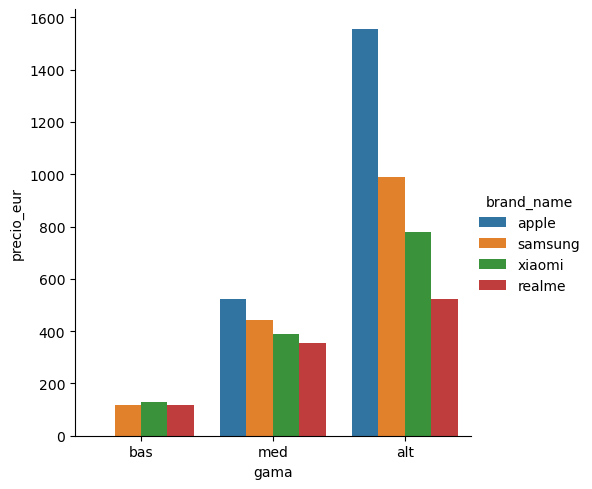

In [120]:
sns.catplot(x='gama', y='precio_eur', hue='brand_name', kind='bar', data = df_slc, hue_order=['apple', 'samsung', 'xiaomi', 'realme'])

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


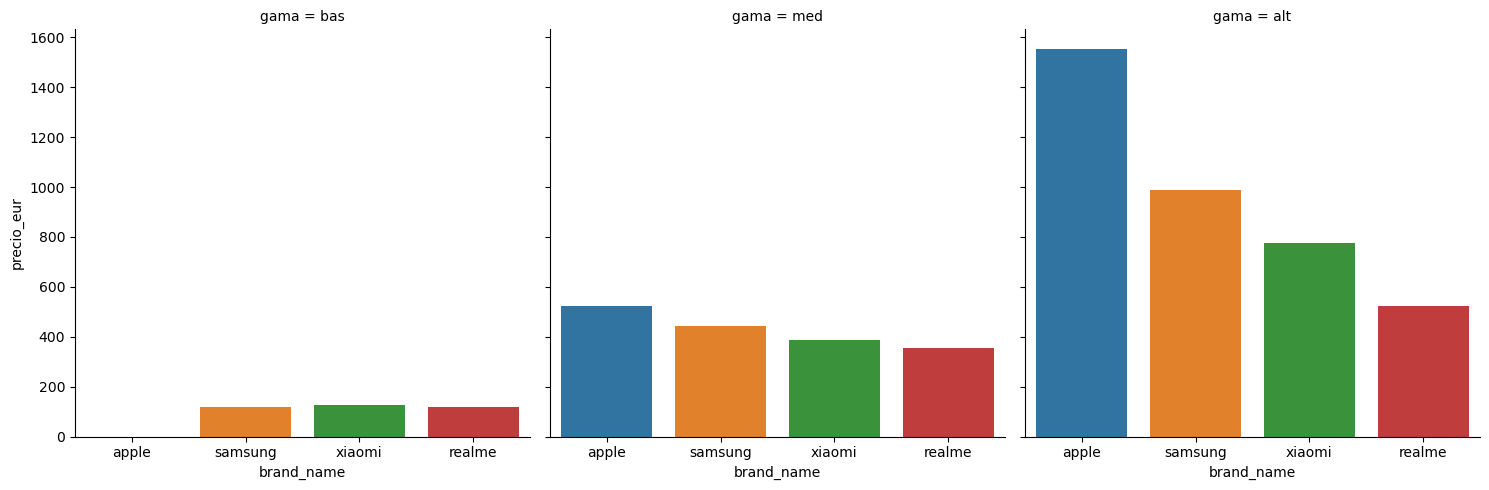

In [137]:
g = sns.catplot(x='brand_name', y='precio_eur', col='gama', kind='bar', order=['apple', 'samsung', 'xiaomi', 'realme'], data = df_slc)

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
C:\Users\julio\AppData\Local\Temp\ipykernel_26436\1693337797.py:6: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(1, 3, 2)
c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\julio\AppData\Local\Temp\ipykernel_26436\1693337797.py:8: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplo

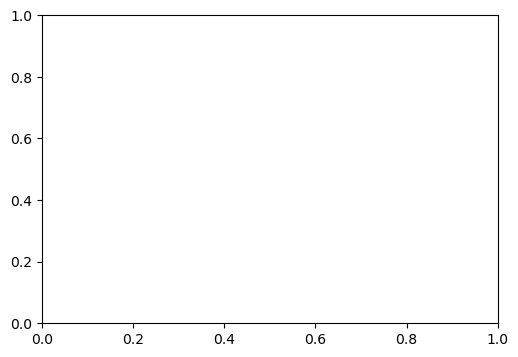

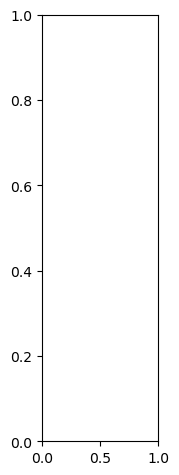

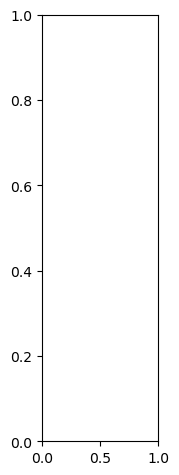

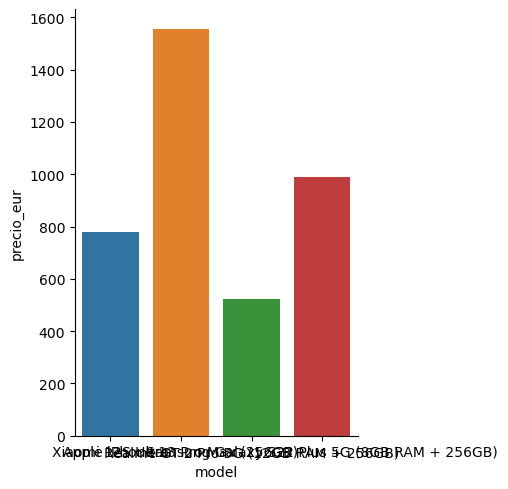

In [138]:
plt.figure(figsize = (20, 4))
plt.subplot(1, 3, 1)
sns.catplot(x='model', y='precio_eur', kind='bar', data = df_slc_bas)
plt.ylabel('cantidad')
plt.legend()
plt.subplot(1, 3, 2)
sns.catplot(x='model', y='precio_eur', kind='bar', data = df_slc_med)
plt.subplot(1, 3, 3)
sns.catplot(x='model', y='precio_eur', kind='bar', data = df_slc_alt)
plt.show()

Tanto este gráfico como los del apartado [5.2](#toc1_5_2_) parecen confirmar la hipótesis de que hay un factor marca que influye en el precio de los móviles. Sin embargo, tanto este análisis como el del apartado anterior tienen limitaciones: 
- En el análisis del apartado anterior, en el que se grafica el precio en función de distintas características técnicas para distintas marcas, no se asegura que se estén comparando móviles de características similares. 
- El análisis de este apartado se basa en observaciones puntuales. 

Sería necesario un análisis más detallado para contrastar de forma más rigurosa esta hipótesis. Sería de utilidad ajustar un modelo para predecir los precios en función de las características técnicas y de la marca. 

### <a id='toc1_5_3_'></a>[5.3. Hipótesis 3](#toc0_)

Hipótesis 3: Por encima del rango de precios medio, la mejora en prestaciones para un incremento de precio determinado tiende a ser menor que en precios más bajos.

En la gráfica del precio frente a la RAM mostrada en el apartado [5.1](#toc1_5_1_) se aprecia que la sensibilidad del precio a la RAM es mayor en precios altos en los Xiaomi y sobre todo en los Samsung. Pero se requiere un análisis más detallado para poder contrastar esta hipótesis. Una idea sería ajustar regresiones lineales para distintas gamas de precios, y revisar si las sensibilidades ó las elasticidades del precio frente a las distintas características técnicas son mayores en gamas de precios más altas. 

Por otra parte, se observa que el rating -que correla positivamente con el precio con varias características técnicas, como se indicó en el apartado [5.1](#toc1_5_1_)- tiene una sensibilidad menor al precio en las gamas de precio más altas, como se puede ver en las siguiente figuras. 

resolution_width


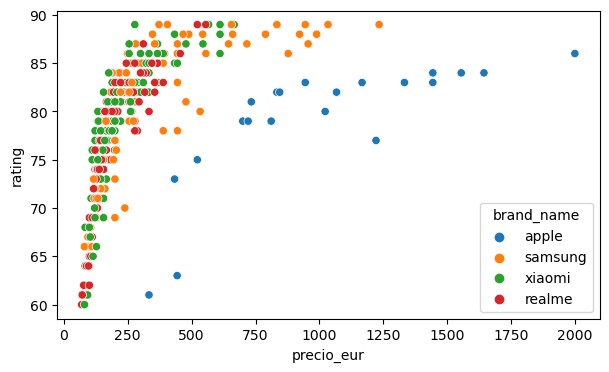

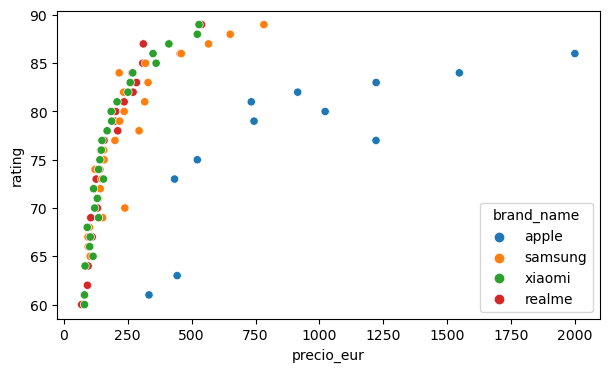

In [136]:
print(col)
plt.figure(figsize = (7, 4))
sns.scatterplot(data=df_gbma_tukey, x='precio_eur', y='rating', hue='brand_name', hue_order=lst_marcas_Tukey);
plt.figure(figsize = (7, 4))
df_gbma_tukey_gr = df_gbma_tukey.groupby(['brand_name', 'rating'])[['precio_eur', 'rating']].mean()
sns.scatterplot(data=df_gbma_tukey_gr, x='precio_eur', y='rating', hue='brand_name', hue_order=lst_marcas_Tukey);